# Tạo sinh ảnh phản thực X-ray toàn khung theo Grad-CAM

Chọn **GPU T4 x2**, bật **Internet**. Dataset và checkpoint công khai được tải tự động
từ Hugging Face theo revision cố định; không cần gắn dataset Kaggle.
Mặc định chạy **toàn bộ split test** (`SPLIT="test"`, `MAX_IMAGES=None`). Giữ nguyên split gốc, không thêm ảnh train, chia lại hay khử trùng.

Quy trình: ảnh grayscale 256×256 → ReStyle-pSp (5 vòng) → W+ → tái tạo → Grad-CAM
lớp gốc trên toàn khung → tối ưu W+ → đánh giá. Encoder step **3500** dùng đúng
StyleGAN2 **500 kimg** được ghi trong cấu hình huấn luyện.

Thử cả **normal → pneumonia** và **pneumonia → normal**. Chỉ tối ưu ảnh gốc phân
loại đúng và ảnh tái tạo giữ lớp; báo cáo tỷ lệ đủ điều kiện trên toàn bộ split đã chọn.
Validity đo việc đổi dự đoán classifier. Nếu chuyển sang val: split này chỉ có 16 ảnh và đã được dùng chọn checkpoint encoder,
nên kết quả val chỉ là kiểm tra phương pháp, không phải đánh giá độc lập.

Section 5 tự lưu mỗi 500 ảnh và khôi phục khi đổi session; section 8 lưu bổ sung lên `Purino/chest-xray-counterfactual-cam-results`.
Cần secret **HF_TOKEN** có quyền ghi của Purino ngay từ section 5.


## 1. Cấu hình thí nghiệm

Khi `MAX_IMAGES` là số nguyên, lấy xen kẽ các class sau khi trộn theo `SEED`,
đảm bảo ít nhất một ảnh cho mỗi class có trong split. Nếu giới hạn nhỏ hơn số class,
báo lỗi và yêu cầu tăng `MAX_IMAGES` hoặc đặt `None`; không tự vượt giới hạn.
Ví dụ split có `normal` và `pneumonia`: cần `MAX_IMAGES >= 2`.
Nếu giới hạn lớn hơn số ảnh trong split, lấy toàn bộ ảnh sẵn có.
`MAX_IMAGES=None` giữ nguyên cách lấy toàn bộ split. Số ảnh từng class được ghi
trong `selected_class_counts` và in ra khi chọn tập con.
Tập con lấy xen kẽ không giữ nguyên tỷ lệ class của split; việc đủ class ở đầu vào
không đảm bảo đủ class sau bước lọc điều kiện tạo ảnh phản thực.


In [1]:
from pathlib import Path
import json, os, subprocess, sys

ENCODER_STEP = 3500
GENERATOR_KIMG = 500
SPLIT = "train"                 # Giữ nguyên toàn bộ split test chính thức
MAX_IMAGES = 4000              # None = toàn bộ; số nguyên phải >= số class trong split
SEED = 42
REFINE_RECONSTRUCTION = False  # False: w0=E(x); True: tinh chỉnh tái tạo trước
RECON_STEPS = 150
RECON_LR = 0.01
CAM_TOP_RATIO = 0.30
LAMBDA_OUT = 10.0  # 0.0 = bỏ penalty ngoài ROI; vẫn tính/vẽ loss_out và CAM
LAMBDA_CLS = 1.0
LAMBDA_LATENT = 1e-4
CF_STEPS = 300
CF_LR = 0.01
        
NUM_GPUS = 2                   # Có thể dùng 1 để kiểm tra đối chiếu
BATCH_SIZE = 16                 # Số ảnh mỗi GPU; None = tự benchmark chọn batch
PREVIEW_IMAGES = 8
HF_CHECKPOINT_EVERY = 500       # 0 = tắt; mặc định lưu mỗi 500 ảnh hoàn tất
HF_RESULTS_REPO = "Purino/chest-xray-counterfactual-cam-results"
HF_PRIVATE = True              # Chỉ áp dụng khi tạo repo mới
HF_FILES_PER_COMMIT = 1000      # Số tệp, không phải số ảnh
RUN_SMOKE_TEST = False          # Kiểm tra nhỏ cả hai chế độ trước lần chạy đầy đủ
DATA_ROOT = "/kaggle/temp/chest_cf_runtime/dataset"
OUTPUT_ROOT = "/kaggle/working/chest_cf"
RUNTIME = Path("/kaggle/temp/chest_cf_runtime")
BUNDLE = Path("/kaggle/working/chest_cf_bundle")

ENCODER_REVISION = "ee53ea578502d6befa6cc73af4cd316ceb817c60"
GENERATOR_REVISION = "9f6e759670e129ee426771126411973e5fedc3c0"
CLASSIFIER_REVISION = "94d95886e98da0c3a7a61670429c60419ceba2c4"
ENCODER_REPO = "Purino/restyle-psp-chest-xray-pneumonia-256-gray"
GENERATOR_REPO = "Purino/stylegan2-ada-chest-xray-pneumonia-256-gray-scratch"
CLASSIFIER_REPO = "Purino/resnet50-chest-xray-256-fullframe-gray-v2"
DATASET_REPO = "Purino/chest-xray-pneumonia-256-fullframe-gray"
DATASET_REVISION = "558d8fad0b36f170a8f706370cc8dba5a7161e3d"

OPTIONS = dict(encoder_repo=ENCODER_REPO, generator_repo=GENERATOR_REPO,
    classifier_repo=CLASSIFIER_REPO, dataset_repo=DATASET_REPO, dataset_revision=DATASET_REVISION,
    encoder_step=ENCODER_STEP, generator_kimg=GENERATOR_KIMG,
    encoder_revision=ENCODER_REVISION, generator_revision=GENERATOR_REVISION,
    classifier_revision=CLASSIFIER_REVISION, data_root=DATA_ROOT,
    output_root=OUTPUT_ROOT, runtime_root=str(RUNTIME), split=SPLIT,
    max_images=MAX_IMAGES, seed=SEED, refine_reconstruction=REFINE_RECONSTRUCTION,
    recon_steps=RECON_STEPS, recon_lr=RECON_LR, cam_top_ratio=CAM_TOP_RATIO,
    lambda_out=LAMBDA_OUT, lambda_cls=LAMBDA_CLS, lambda_latent=LAMBDA_LATENT,
    cf_steps=CF_STEPS, cf_lr=CF_LR, num_gpus=NUM_GPUS, batch_size=BATCH_SIZE,
    preview_images=PREVIEW_IMAGES, hf_checkpoint_every=HF_CHECKPOINT_EVERY,
    hf_results_repo=HF_RESULTS_REPO, hf_private=HF_PRIVATE, hf_files_per_commit=HF_FILES_PER_COMMIT)
print("Chế độ:", "tinh chỉnh tái tạo" if REFINE_RECONSTRUCTION else "encoder trực tiếp")


Chế độ: encoder trực tiếp


## 2. Môi trường và mã nguồn

Tải `checkpoints/step-00003500/encoder.pt` và
`checkpoints/nimg-000000500000/network.pkl`; kiểm tra step, signature, revision và
SHA256 theo `complete.json` / cấu hình encoder. Giải nén đúng `source.zip` đi kèm
checkpoint để dùng kiến trúc ReStyle và mã NVIDIA đã huấn luyện.
Classifier dùng torchvision ResNet50, head Dropout(0.3) + Linear(2048, 2).
Tải và biên dịch lần đầu có thể mất vài phút; các lần sau dùng cache.


In [2]:
BUNDLED_FILES = {'src/chest_data.py': '"""Exact 256x256 grayscale data; no crop, resize, regrouping or deduplication."""\nimport numpy as np\nfrom PIL import Image\n\n\ndef load_rgb(path):\n    with Image.open(path) as image:\n        image.load()\n        if image.mode != \'L\' or image.size != (256, 256):\n            raise ValueError(f\'{path}: expected grayscale L 256x256, got {image.mode} {image.size}\')\n        return np.asarray(image.convert(\'RGB\')).copy()\n', 'src/chest_model.py': '"""Checkpoint-compatible ReStyle inversion and grayscale StyleGAN2 synthesis."""\nimport hashlib\nimport sys\nfrom pathlib import Path\nfrom types import SimpleNamespace\n\nimport torch\nfrom torch import nn\nimport torch.nn.functional as F\nfrom pytorch_msssim import ssim\n\n\nfrom restyle_model import Encoder, invert, load_generator, synthesize as synthesize_gray\n\n\nclass ChestEncoder(nn.Module):\n    """Five residual ReStyle iterations using the exact checkpoint architecture."""\n    def __init__(self, config, generator):\n        super().__init__()\n        self.encoder = Encoder(config, generator, pretrained=False)\n        # Generator is shared, not registered a second time in encoder state_dict.\n        object.__setattr__(self, \'_generator\', generator)\n        self.iterations = config[\'iterations\']\n\n    @torch.no_grad()\n    def forward(self, images):\n        gray = images.mean(1, keepdim=True)\n        ws, _ = invert(self.encoder, self._generator, gray,\n                       iterations=self.iterations, full_precision=True)\n        return ws.float()\n\n\ndef synthesize(generator, ws, full_precision=False):\n    # G is genuinely one-channel. Replication preserves the original RGB loss\n    # scale (sum over 3 channels / 3), LPIPS interface and artifact schema.\n    return synthesize_gray(generator, ws, full_precision).repeat(1, 3, 1, 1)\n\n\ndef assert_reconstruction_close(actual, expected):\n    """Allow FP32 GPU roundoff while detecting changed noise/weights/latents.\n\n    Images use the [-1,1] scale. Near zero, relative error is misleading; a 1e-5\n    absolute allowance is about 0.0013 of one 8-bit gray level. The original 1e-6\n    check rejected ~1.7e-6 differences on T4 even with constant synthesis noise.\n    """\n    if not torch.isfinite(actual).all() or not torch.isfinite(expected).all():\n        raise AssertionError(\'Reconstruction contains non-finite values\')\n    torch.testing.assert_close(actual, expected, atol=1e-5, rtol=1e-5)\n    return dict(max_abs_difference=(actual - expected).abs().max().item(),\n                atol=1e-5, rtol=1e-5)\n\n\nclass ReconstructionLoss(nn.Module):\n    def __init__(self, config, perceptual=None):\n        super().__init__()\n        self.weights = config[\'loss_weights\']\n        if perceptual is not None:\n            self.perceptual = perceptual\n        elif self.weights.get(\'lpips\', 0) > 0:\n            import lpips\n            self.perceptual = lpips.LPIPS(net=\'alex\', verbose=False)\n        else:\n            self.perceptual = None\n        if self.perceptual is not None:\n            self.perceptual.eval().requires_grad_(False)\n\n    def components(self, prediction, target):\n        prediction, target = prediction.float(), target.float()\n        # Pixel errors in [-1,1]. Do not clamp training output: out-of-range errors\n        # must still backpropagate. SSIM works on the corresponding [0,1] scale.\n        pixel = (prediction - target).square().flatten(1).mean(1)\n        gray_pred = (prediction.mean(1, keepdim=True) + 1) / 2\n        gray_target = (target.mean(1, keepdim=True) + 1) / 2\n        structural = 1 - ssim(gray_pred, gray_target, data_range=1, size_average=False)\n        perceptual = (self.perceptual(prediction, target).flatten(1).mean(1)\n                      if self.perceptual is not None else torch.zeros_like(pixel))\n        total = (self.weights[\'pixel\'] * pixel + self.weights[\'ssim\'] * structural\n                 + self.weights.get(\'lpips\', 0) * perceptual)\n        return {\'loss\': total, \'mse\': pixel, \'ssim\': 1 - structural, \'lpips\': perceptual}\n\n    def forward(self, prediction, target):\n        return self.components(prediction, target)[\'loss\'].mean()\n\n\ndef reconstruction_metrics(prediction, target, loss):\n    values = loss.components(prediction, target)\n    # All image metrics use unclipped RGB values unless explicitly grayscale SSIM.\n    mse01 = values.pop(\'mse\') / 4\n    values[\'mse_01\'] = mse01\n    values[\'mae_01\'] = (prediction - target).abs().flatten(1).mean(1) / 2\n    values[\'psnr\'] = -10 * torch.log10(mse01.clamp_min(1e-12))\n    return values\n\n\ndef refine_latent(generator, loss, images, initial_ws, steps=150, lr=0.01):\n    """Refine W+ only; retain the best value independently for each input image."""\n    ws = nn.Parameter(initial_ws.detach().clone().float())\n    optimizer = torch.optim.Adam([ws], lr=lr)\n    with torch.no_grad():\n        best_loss = loss.components(synthesize(generator, ws, True), images)[\'loss\']\n    best_ws = ws.detach().clone()\n    for _ in range(steps):\n        optimizer.zero_grad(set_to_none=True)\n        value = loss.components(synthesize(generator, ws, True), images)[\'loss\']\n        value.mean().backward()\n        if ws.grad is None or not torch.isfinite(ws.grad).all():\n            raise RuntimeError(\'Nonfinite W+ refinement gradient\')\n        optimizer.step()\n        with torch.no_grad():\n            candidate = loss.components(synthesize(generator, ws, True), images)[\'loss\']\n            improved = candidate < best_loss\n            best_ws[improved] = ws[improved]\n            best_loss = torch.minimum(best_loss, candidate)\n    return best_ws.detach()\n', 'src/psp_compat.py': '"""Unactivated EqualLinear used by upstream pSp style heads.\n\nEquivalent to the unactivated branch in pSp/models/stylegan2/model.py.\nAvoids importing the unrelated rosinality generator and its CUDA extensions.\n"""\nimport math\nimport torch\nfrom torch import nn\nfrom torch.nn import functional as F\n\n\nclass EqualLinear(nn.Module):\n    def __init__(self, in_dim, out_dim, bias=True, bias_init=0, lr_mul=1,\n                 activation=None):\n        super().__init__()\n        if activation is not None:\n            raise ValueError("Only pSp\'s unactivated EqualLinear is supported")\n        self.weight = nn.Parameter(torch.randn(out_dim, in_dim).div_(lr_mul))\n        self.bias = nn.Parameter(torch.full((out_dim,), float(bias_init))) if bias else None\n        self.scale = (1 / math.sqrt(in_dim)) * lr_mul\n        self.lr_mul = lr_mul\n\n    def forward(self, x):\n        bias = self.bias * self.lr_mul if self.bias is not None else None\n        return F.linear(x, self.weight * self.scale, bias=bias)\n', 'src/setup_sources.py': '"""Restore the exact, checksum-verified source archive shipped with step 3500."""\nfrom pathlib import Path, PurePosixPath\nimport zipfile\n\n\ndef extract_zip(archive, destination):\n    destination = Path(destination).resolve()\n    destination.mkdir(parents=True, exist_ok=True)\n    with zipfile.ZipFile(archive) as stream:\n        for entry in stream.infolist():\n            target = destination.joinpath(*PurePosixPath(entry.filename).parts).resolve()\n            if (\'\\\\\' in entry.filename or not target.is_relative_to(destination)\n                    or (entry.external_attr >> 16) & 0o170000 == 0o120000):\n                raise ValueError(\'Unsafe archive member: \' + entry.filename)\n        stream.extractall(destination)\n\n\ndef setup(archive, root):\n    extract_zip(archive, root)\n    root = Path(root)\n    for name in [\'adapted/restyle_upstream/encoders/restyle_psp_encoders.py\', \'stylegan3/legacy.py\']:\n        if not (root / name).is_file():\n            raise ValueError(\'Encoder source archive is incomplete: \' + name)\n    return dict(encoder_root=str(root / \'adapted\'), nvidia_root=str(root / \'stylegan3\'))\n', 'src/notebook_progress.py': '"""Render rank-zero training events in the notebook kernel, not worker processes.\n\nThis module needs no torch import, so it can run in Kaggle\'s notebook kernel\nwhile training uses the isolated environment. Non-event output remains visible.\n"""\nimport json\nimport os\nimport signal\nimport subprocess\n\nEVENT_PREFIX = \'PSP_PROGRESS \'\n\n\ndef emit_progress(rank, **event):\n    if rank == 0:\n        print(EVENT_PREFIX + json.dumps(event, allow_nan=False), flush=True)\n\n\ndef stop_process_group(process):\n    """A notebook interruption must not leave torchrun workers using both GPUs."""\n    if process.poll() is not None:\n        return\n    try:\n        if os.name == \'posix\':\n            os.killpg(process.pid, signal.SIGTERM)\n        else:\n            process.terminate()\n    except ProcessLookupError:\n        return\n    try:\n        process.wait(timeout=15)\n    except subprocess.TimeoutExpired:\n        if os.name == \'posix\':\n            os.killpg(process.pid, signal.SIGKILL)\n        else:\n            process.kill()\n        process.wait()\n\n\ndef run_with_progress(command, env=None, bar_factory=None):\n    """Stream one notebook-native bar; preserve tracebacks and process exit codes."""\n    if bar_factory is None:\n        from tqdm.auto import tqdm\n        bar_factory = tqdm\n    bar = None\n    metrics = {}\n    ended = False\n    print(\'Starting two-GPU training; loading models and any saved checkpoint...\', flush=True)\n    with subprocess.Popen(command, env=env, stdout=subprocess.PIPE,\n                          stderr=subprocess.STDOUT, text=True, bufsize=1,\n                          start_new_session=(os.name == \'posix\')) as process:\n        try:\n            for line in process.stdout:\n                event = None\n                if line.startswith(EVENT_PREFIX):\n                    try:\n                        event = json.loads(line[len(EVENT_PREFIX):])\n                    except json.JSONDecodeError:\n                        pass\n                if not isinstance(event, dict) or \'kind\' not in event:\n                    if bar is not None:\n                        bar_factory.write(line.rstrip())\n                    else:\n                        print(line, end=\'\', flush=True)\n                    continue\n                kind = event[\'kind\']\n                if kind == \'start\':\n                    if bar is not None:\n                        bar.close()\n                    bar = bar_factory(total=event[\'total\'], initial=event[\'step\'],\n                                      desc=\'Training (2 GPUs)\', unit=\'step\',\n                                      mininterval=1.0, dynamic_ncols=True)\n                elif bar is not None:\n                    if \'step\' in event:\n                        bar.update(max(0, event[\'step\'] - bar.n))\n                    if kind == \'step\':\n                        metrics.update(loss=f"{event[\'loss\']:.4f}",\n                                       lr=f"{event[\'lr\']:.2e}",\n                                       **{\'s/step\': f"{event[\'seconds_per_step\']:.2f}",\n                                          \'GPU GiB\': f"{event[\'peak_reserved_gib\']:.1f}",\n                                          \'session left\': f"{event[\'session_seconds_left\'] / 3600:.2f}h"})\n                        if not event[\'optimizer_updated\']:\n                            metrics[\'AMP\'] = \'update skipped\'\n                        else:\n                            metrics.pop(\'AMP\', None)\n                        bar.set_description(\'Training (2 GPUs)\', refresh=False)\n                        bar.set_postfix(metrics)\n                    elif kind == \'phase\':\n                        bar.set_description(event[\'phase\'])\n                    elif kind == \'validation\':\n                        metrics[\'val\'] = f"{event[\'loss\']:.4f}"\n                        metrics[\'best\'] = f"{event[\'best_loss\']:.4f}"\n                        bar.set_postfix(metrics)\n                    elif kind == \'end\':\n                        ended = True\n                        bar.set_description(event[\'status\'])\n                        bar.refresh()  # A time-limited run stays at its actual count.\n            returncode = process.wait()\n            if returncode:\n                if bar is not None:\n                    bar.set_description(\'Training failed; see traceback above\')\n                raise subprocess.CalledProcessError(returncode, command)\n            if bar is not None and not ended:\n                bar.set_description(\'Training process exited\')\n        except BaseException:\n            stop_process_group(process)\n            raise\n        finally:\n            if bar is not None:\n                bar.close()\n', 'src/counterfactual_core.py': '"""Differentiable, per-image Grad-CAM/W+ counterfactual operations.\n\nImages at this API are RGB NCHW floats on [-1, 1] (G may exceed that range).\nOnly the classifier/display path clips; outside-ROI loss uses raw G output.\n"""\nfrom contextlib import nullcontext\nfrom functools import lru_cache\n\nimport torch\nfrom torch import nn\nfrom torch.nn import functional as F\n\nfrom chest_model import synthesize\n\n\ndef display_image(image):\n    return ((image.float() + 1) / 2).clamp(0, 1)\n\n\n@lru_cache(maxsize=4096)\ndef autocontrast_lut(low, high):\n    # Pillow builds this LUT with Python double arithmetic. A vectorized GPU\n    # multiply/add may round integer boundaries differently by one gray level.\n    if high <= low:\n        return tuple(range(256))\n    scale = 255.0 / (high - low)\n    offset = -low * scale\n    return tuple(max(0, min(255, int(value * scale + offset))) for value in range(256))\n\n\nclass ClassifierInput(nn.Module):\n    """Full-frame grayscale, PIL-compatible cutoff=1 autocontrast, ImageNet norm.\n\n    Forward uses an 8-bit histogram/LUT, exactly as the published classifier.\n    Backward uses a straight-through continuous contrast stretch with detached\n    histogram endpoints. Quantization itself has zero derivative almost everywhere;\n    this explicitly documented surrogate keeps W+ optimization possible.\n    """\n    def __init__(self):\n        super().__init__()\n        self.register_buffer(\'mean\', torch.tensor([.485, .456, .406]).view(1, 3, 1, 1))\n        self.register_buffer(\'std\', torch.tensor([.229, .224, .225]).view(1, 3, 1, 1))\n\n    def forward(self, image):\n        if image.ndim != 4 or tuple(image.shape[1:]) != (3, 256, 256):\n            raise ValueError(\'ClassifierInput expects replicated grayscale [N,3,256,256]\')\n        # Inputs are grayscale replicated across RGB, so one channel is exact.\n        # Averaging identical FP32 channels can round differently on CPU/CUDA;\n        # at an 8-bit half-step this changes the quantized pixel and its LUT value.\n        # Selecting a channel still propagates gradients through G\'s RGB repeat.\n        gray = display_image(image[:, :1])\n        with torch.no_grad():\n            pixels = (gray * 255).round().long().flatten(1)\n            histogram = torch.zeros(len(image), 256, device=image.device, dtype=torch.int64)\n            histogram.scatter_add_(1, pixels, torch.ones_like(pixels))\n            cut = pixels.shape[1] // 100\n            lo = (histogram.cumsum(1) > cut).long().argmax(1)\n            hi = 255 - (histogram.flip(1).cumsum(1) > cut).long().argmax(1)\n            stretch = hi > lo\n            endpoints = torch.stack((lo, hi), 1).cpu().tolist()\n            lut = torch.tensor([autocontrast_lut(low, high) for low, high in endpoints],\n                               device=image.device, dtype=torch.float32)\n            exact = lut.gather(1, pixels).reshape_as(gray).float() / 255\n        low = lo.float().view(-1, 1, 1, 1) / 255\n        span = (hi - lo).clamp_min(1).float().view(-1, 1, 1, 1) / 255\n        continuous = torch.where(stretch.view(-1, 1, 1, 1), ((gray - low) / span).clamp(0, 1), gray)\n        # Identical forward in grad/no-grad paths; only the backward is approximated.\n        # Subtract identical values first: forward is exactly the LUT result,\n        # while backward remains the derivative of the continuous surrogate.\n        processed = exact + (continuous - continuous.detach())\n        return (processed.repeat(1, 3, 1, 1) - self.mean) / self.std\n\n\ndef logits_for(classifier, preprocess, image, mixed=False):\n    context = (torch.autocast(\'cuda\', dtype=torch.float16)\n               if mixed and image.device.type == \'cuda\' else nullcontext())\n    with context:\n        output = classifier(preprocess(image))\n    return output.float()\n\n\ndef grad_cam(classifier, preprocess, image, classes, target_layer=None):\n    """FP32 Grad-CAM of original class logits; no persistent backward hooks."""\n    if target_layer is None:\n        target_layer = classifier.layer4[-1]\n    captured = []\n    hook = target_layer.register_forward_hook(lambda module, args, output: captured.append(output))\n    try:\n        with torch.enable_grad(), torch.autocast(image.device.type, enabled=False):\n            inputs = image.detach().float().requires_grad_(True)\n            logits = logits_for(classifier, preprocess, inputs)\n            activations = captured[-1]\n            score = logits.gather(1, classes[:, None]).sum()\n            gradient, = torch.autograd.grad(score, activations)\n            cam = (gradient.mean((2, 3), keepdim=True) * activations).sum(1, keepdim=True).relu()\n            return F.interpolate(cam, (256, 256), mode=\'bilinear\', align_corners=False).detach()\n    finally:\n        hook.remove()\n\n\ndef roi_mask(cam, ratio=.30):\n    """Rank every full-frame pixel; stable ties are row-major, on the CPU.\n\nThe quota is a fraction of the full 256x256 frame.\nDegenerate CAMs return a zero mask plus an explicit invalid flag.\n"""\n    if cam.ndim != 4 or tuple(cam.shape[1:]) != (1, 256, 256):\n        raise ValueError(\'CAM must have shape [N,1,256,256]\')\n    count = round(float(ratio) * 256 * 256)\n    if not 0 < count < 256 * 256:\n        raise ValueError(\'ROI must leave at least one pixel outside the full-frame mask\')\n    visible = cam.detach().float().cpu().flatten(1)\n    valid = torch.isfinite(visible).all(1) & ((visible.max(1).values - visible.min(1).values) > 1e-8)\n    ranked = torch.argsort(visible, dim=1, descending=True, stable=True)\n    flat_mask = torch.zeros_like(visible)\n    flat_mask.scatter_(1, ranked[:, :count], 1)\n    flat_mask[~valid] = 0\n    mask = flat_mask.reshape(-1, 1, 256, 256)\n    return mask.to(cam.device), valid.to(cam.device)\n\n\ndef loss_components(generated, original, mask, ws, w0, logits, targets, options):\n    """One loss per image. Latent L2 is a SUM, outside L1 a channel/pixel MEAN."""\n    outside = 1 - mask.float()\n    denominator = 3 * outside.flatten(1).sum(1)\n    if torch.any(denominator <= 0):\n        raise ValueError(\'Outside-ROI loss requires at least one outside pixel\')\n    out = ((generated.float() - original.float()).abs() * outside).flatten(1).sum(1) / denominator\n    cls = F.cross_entropy(logits.float(), targets, reduction=\'none\')\n    latent = (ws.float() - w0.float()).square().flatten(1).sum(1)\n    regularizer = options[\'lambda_out\'] * out + options[\'lambda_latent\'] * latent\n    return dict(out=out, cls=cls, latent=latent, regularizer=regularizer,\n                total=regularizer + options[\'lambda_cls\'] * cls)\n\n\ndef optimize_counterfactual(generator, classifier, preprocess, images, initial_ws,\n                            mask, targets, options, mixed=False, progress=None):\n    """Optimize independent latents and retain the best FP32 candidate per image.\n\nEvery step is evaluated in FP32, including mixed-precision optimization steps.\nSuccessful candidates outrank unsuccessful ones; ties preserve the earlier step.\nNonfinite optimization returns the best finite candidates with an error flag.\n"""\n    ws = nn.Parameter(initial_ws.detach().clone().float())\n    w0 = initial_ws.detach().clone().float()\n    optimizer = torch.optim.Adam([ws], lr=options[\'cf_lr\'])\n    scaler = torch.amp.GradScaler(\'cuda\', init_scale=1024., enabled=mixed and ws.device.type == \'cuda\')\n    size = len(images)\n    best_ws = w0.clone()\n    best_valid = torch.zeros(size, dtype=torch.bool, device=ws.device)\n    best_key = torch.full((size,), float(\'inf\'), device=ws.device)\n    best_step = torch.zeros(size, dtype=torch.int64, device=ws.device)\n    history = []\n    numerical_error = False\n\n    def assess(step):\n        nonlocal best_ws, best_valid, best_key, best_step\n        with torch.no_grad():\n            generated = synthesize(generator, ws, full_precision=True)\n            logits = logits_for(classifier, preprocess, generated)\n            losses = loss_components(generated, images, mask, ws, w0, logits, targets, options)\n            probability = logits.softmax(1).gather(1, targets[:, None]).squeeze(1)\n            finite = torch.isfinite(generated).flatten(1).all(1)\n            finite &= torch.isfinite(logits).all(1) & torch.isfinite(ws).flatten(1).all(1)\n            for value in losses.values():\n                finite &= torch.isfinite(value)\n            valid = logits.argmax(1).eq(targets) & finite\n            key = torch.where(valid, losses[\'regularizer\'], losses[\'total\'])\n            improve = finite & ((valid & ~best_valid) | ((valid == best_valid) & (key < best_key)))\n            best_ws[improve] = ws[improve]\n            best_valid[improve], best_key[improve] = valid[improve], key[improve]\n            best_step[improve] = step\n            # Keep numerical failures visible while producing strict JSON downstream.\n            history.append(dict(step=step, **{k: v.detach().cpu().tolist() for k, v in losses.items()},\n                                target_probability=probability.cpu().tolist()))\n            return bool(finite.all())\n\n    if not assess(0):\n        raise FloatingPointError(\'Initial reconstruction is nonfinite; cannot define a counterfactual baseline\')\n    for step in range(1, options[\'cf_steps\'] + 1):\n        optimizer.zero_grad(set_to_none=True)\n        generated = synthesize(generator, ws, full_precision=not mixed)\n        logits = logits_for(classifier, preprocess, generated, mixed=mixed)\n        values = loss_components(generated, images, mask, ws, w0, logits, targets, options)\n        if not all(torch.isfinite(v).all() for v in values.values()):\n            numerical_error = True\n            break\n        # Sum, not batch mean: each sample has the same gradient at any batch size.\n        scaler.scale(values[\'total\'].sum()).backward()\n        scaler.unscale_(optimizer)\n        if ws.grad is None or not torch.isfinite(ws.grad).all():\n            numerical_error = True\n            break\n        scaler.step(optimizer)\n        scaler.update()\n        if not assess(step):\n            numerical_error = True\n            break\n        if progress is not None and (step % 25 == 0 or step == options[\'cf_steps\']):\n            progress(step, options[\'cf_steps\'])\n    with torch.no_grad():\n        result = synthesize(generator, best_ws, full_precision=True)\n    return dict(ws=best_ws.detach(), images=result.detach(), best_step=best_step.detach(),\n                valid=best_valid.detach(), numerical_error=numerical_error, history=history)\n\n\ndef evaluate_images(original_prob, reconstruction_prob, final_prob, labels):\n    """Unthresholded argmax validity and signed confidence differences."""\n    source = original_prob.argmax(1)\n    target = 1 - source\n    correct = source.eq(labels)\n    preserved = reconstruction_prob.argmax(1).eq(source)\n    eligible = correct & preserved\n    take = lambda probabilities: probabilities.gather(1, source[:, None]).squeeze(1)\n    return dict(source=source, target=target, correct=correct, preserved=preserved,\n                eligible=eligible, valid=eligible & final_prob.argmax(1).eq(target),\n                confidence_drop=take(original_prob) - take(final_prob),\n                confidence_drop_from_reconstruction=take(reconstruction_prob) - take(final_prob))\n', 'src/counterfactual_io.py': '"""Configuration, immutable model provenance, raw splits and atomic CF artifacts."""\nfrom collections import Counter\nfrom statistics import stdev\nimport csv\nimport hashlib\nimport importlib.metadata\nimport json\nimport math\nfrom pathlib import Path\nimport re\nimport time\nimport shutil\nimport zipfile\n\nimport numpy as np\nfrom PIL import Image\nimport torch\n\nfrom chest_data import load_rgb\n\n\nDEFAULTS = dict(\n    encoder_repo=\'Purino/restyle-psp-chest-xray-pneumonia-256-gray\',\n    encoder_revision=\'ee53ea578502d6befa6cc73af4cd316ceb817c60\', encoder_step=3500,\n    generator_repo=\'Purino/stylegan2-ada-chest-xray-pneumonia-256-gray-scratch\',\n    generator_revision=\'9f6e759670e129ee426771126411973e5fedc3c0\', generator_kimg=500,\n    classifier_repo=\'Purino/resnet50-chest-xray-256-fullframe-gray-v2\',\n    classifier_revision=\'94d95886e98da0c3a7a61670429c60419ceba2c4\',\n    dataset_repo=\'Purino/chest-xray-pneumonia-256-fullframe-gray\',\n    dataset_revision=\'558d8fad0b36f170a8f706370cc8dba5a7161e3d\',\n    data_root=\'/kaggle/temp/chest_cf_runtime/dataset\',\n    runtime_root=\'/kaggle/temp/chest_cf_runtime\', output_root=\'/kaggle/working/chest_cf\',\n    split=\'val\', max_images=None, seed=42, refine_reconstruction=False,\n    recon_steps=150, recon_lr=.01, cam_top_ratio=.30,\n    lambda_out=10., lambda_cls=1., lambda_latent=1e-4, cf_steps=200, cf_lr=.01,\n    num_gpus=2, preview_images=8, batch_size=16, batch_candidates=[1, 2, 4, 8, 16],\n    memory_fraction=.90, benchmark_warmup=2, benchmark_steps=5,\n    hf_checkpoint_every=500, hf_results_repo=\'Purino/chest-xray-counterfactual-cam-results\',\n    hf_private=True, hf_files_per_commit=1000,\n)\n\n\ndef validate_options(overrides):\n    unknown = set(overrides) - set(DEFAULTS)\n    if unknown:\n        raise ValueError(f\'Unknown options: {sorted(unknown)}\')\n    options = {**DEFAULTS, **overrides}\n    if type(options[\'hf_checkpoint_every\']) is not int or options[\'hf_checkpoint_every\'] < 0:\n        raise ValueError(\'hf_checkpoint_every must be a nonnegative integer (0 disables HF)\')\n    if type(options[\'hf_files_per_commit\']) is not int or options[\'hf_files_per_commit\'] < 1:\n        raise ValueError(\'hf_files_per_commit must be a positive integer\')\n    if type(options[\'hf_private\']) is not bool:\n        raise ValueError(\'hf_private must be a boolean\')\n    if not isinstance(options[\'hf_results_repo\'], str) or not options[\'hf_results_repo\'].startswith(\'Purino/\'):\n        raise ValueError(\'hf_results_repo must belong to Purino\')\n    for key in [\'encoder_step\', \'preview_images\', \'num_gpus\', \'benchmark_steps\']:\n        if type(options[key]) is not int or options[key] <= 0:\n            raise ValueError(f\'{key} must be a positive integer\')\n    for key in [\'cf_steps\', \'recon_steps\', \'benchmark_warmup\', \'seed\']:\n        if type(options[key]) is not int or options[key] < 0:\n            raise ValueError(f\'{key} must be a nonnegative integer\')\n    # Zero disables the outside-ROI penalty, not its measurement or CAM/ROI.\n    value = options[\'lambda_out\']\n    if type(value) not in (float, int) or not math.isfinite(value) or value < 0:\n        raise ValueError(\'lambda_out must be finite and nonnegative\')\n    for key in [\'generator_kimg\', \'cf_lr\', \'recon_lr\', \'lambda_cls\', \'lambda_latent\']:\n        if not isinstance(options[key], (float, int)) or not math.isfinite(options[key]) or options[key] <= 0:\n            raise ValueError(f\'{key} must be finite and positive\')\n    if type(options[\'refine_reconstruction\']) is not bool:\n        raise ValueError(\'refine_reconstruction must be False or True\')\n    if options[\'split\'] not in {\'train\', \'val\', \'test\'}:\n        raise ValueError(\'split must be train, val or test\')\n    if options[\'max_images\'] is not None and (type(options[\'max_images\']) is not int or options[\'max_images\'] <= 0):\n        raise ValueError(\'max_images must be None or a positive integer\')\n    if not 0 < options[\'cam_top_ratio\'] < 1 or not 0 < round(options[\'cam_top_ratio\'] * 65536) < 65536:\n        raise ValueError(\'CAM quota must leave at least one full-frame pixel outside ROI\')\n    if not 0 < options[\'memory_fraction\'] <= .90:\n        raise ValueError(\'memory_fraction must leave at least 10% VRAM free\')\n    if options[\'num_gpus\'] not in (1, 2):\n        raise ValueError(\'num_gpus must be 1 or 2\')\n    if options[\'batch_size\'] is not None and (type(options[\'batch_size\']) is not int or options[\'batch_size\'] <= 0):\n        raise ValueError(\'batch_size must be None (automatic) or a positive integer per GPU\')\n    candidates = options[\'batch_candidates\']\n    if not candidates or any(type(n) is not int or n < 1 for n in candidates):\n        raise ValueError(\'batch_candidates must contain positive integers\')\n    options[\'batch_candidates\'] = sorted(set(candidates) | {1})\n    return options\n\n\ndef sha256(path):\n    with Path(path).open(\'rb\') as stream:\n        return hashlib.file_digest(stream, \'sha256\').hexdigest()\n\n\ndef clean_json(value):\n    if isinstance(value, dict):\n        return {str(k): clean_json(v) for k, v in value.items()}\n    if isinstance(value, (list, tuple)):\n        return [clean_json(v) for v in value]\n    if isinstance(value, (float, np.floating)) and not math.isfinite(value):\n        return None\n    return value\n\n\ndef atomic_json(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    temporary = path.with_name(path.name + \'.tmp\')\n    temporary.write_text(json.dumps(clean_json(value), ensure_ascii=False, indent=2, allow_nan=False), encoding=\'utf-8\')\n    temporary.replace(path)\n\n\ndef discover_records(root, split, manifest, seed=42, limit=None):\n    """Use official manifest identity and labels, preserving every split member."""\n    root = Path(root)\n    source_rows = [r for r in manifest[\'rows\'] if r[\'split\'] == split]\n    if not source_rows:\n        raise ValueError(f\'No images in official {split} split\')\n    if limit is not None:\n        if type(limit) is not int or limit <= 0:\n            raise ValueError(\'MAX_IMAGES must be None or a positive integer\')\n        split_classes = sorted({item[\'class\'].lower() for item in source_rows})\n        if limit < len(split_classes):\n            raise ValueError(\n                f\'MAX_IMAGES={limit} cannot cover all {len(split_classes)} classes \'\n                f\'in split {split!r}: {split_classes}. \'\n                f\'Set MAX_IMAGES >= {len(split_classes)} or None.\')\n    archive_path = root / (split + \'.zip\')\n    if sha256(archive_path) != manifest[\'archives\'][split]:\n        raise ValueError(\'Dataset archive checksum mismatch: \' + split)\n    with zipfile.ZipFile(archive_path) as archive:\n        expected_files = {item[\'output\']: hashlib.sha256(archive.read(item[\'output\'])).hexdigest()\n                          for item in source_rows}\n    rows = []\n    for item in source_rows:\n        relative = (Path(split) / item[\'output\']).as_posix()\n        path = (root / relative).resolve()\n        if not path.is_relative_to(root.resolve()):\n            raise ValueError(\'Unsafe dataset manifest path\')\n        rgb = load_rgb(path)\n        gray_hash = hashlib.sha256(rgb[:, :, 0].copy().tobytes()).hexdigest()\n        if sha256(path) != expected_files[item[\'output\']]:\n            raise ValueError(f\'Extracted dataset file differs from verified archive: {relative}\')\n        label = item[\'class\'].lower()\n        if label not in {\'normal\', \'pneumonia\'}:\n            raise ValueError(\'Unexpected dataset class: \' + label)\n        rows.append(dict(id=hashlib.sha256(relative.encode()).hexdigest()[:20], path=relative,\n                         original_path=item[\'source\'], split=split, label=label,\n                         label_id={\'normal\': 0, \'pneumonia\': 1}[label],\n                         pixel_sha256=gray_hash, source_pixel_fingerprint=item[\'pixels_sha256\'], audited=True))\n    if len(rows) != sum(manifest[\'counts\'][split].values()):\n        raise ValueError(\'Manifest count does not match official split\')\n    if len({r[\'id\'] for r in rows}) != len(rows):\n        raise ValueError(\'Duplicate output path in manifest\')\n    counts = dict(Counter(r[\'label\'] for r in rows))\n    rng = np.random.default_rng(seed)\n    groups = [[r for r in rows if r[\'label\'] == label] for label in sorted(counts)]\n    for group in groups:\n        rng.shuffle(group)\n    ordered = [group[i] for i in range(max(map(len, groups))) for group in groups if i < len(group)]\n    # Each nonempty class contributes once before any class contributes twice.\n    selected = ordered if limit is None else ordered[:limit]\n    selected_counts = dict(Counter(r[\'label\'] for r in selected))\n    if limit is not None:\n        missing_classes = set(counts) - set(selected_counts)\n        if missing_classes:\n            raise ValueError(f\'Selected subset is missing classes: {sorted(missing_classes)}\')\n        print(f\'Selected {len(selected)}/{len(rows)} images from {split}: {selected_counts}\', flush=True)\n    return selected, dict(raw_count=len(rows), raw_class_counts=counts, selected_count=len(selected),\n                         selected_class_counts=selected_counts,\n                         full_split=len(selected) == len(rows), split=split,\n                         manifest_verification=\'Archive SHA256 and extracted file integrity; processed pixels hashed for resume\',\n                         subset_note=\'Seeded class-interleaved subsets do not preserve prevalence.\',\n                         split_policy=\'Official split retained; no holdout, regrouping or deduplication\')\n\n\ndef generator_filename(filenames, kimg):\n    nimg = float(kimg) * 1000\n    if not nimg.is_integer():\n        raise ValueError(\'Generator kimg must correspond to an integer image count\')\n    name = f\'checkpoints/nimg-{int(nimg):012d}/network.pkl\'\n    if name not in filenames:\n        raise ValueError(f\'Missing exact generator checkpoint: {name}\')\n    return name\n\n\ndef validate_processor(config):\n    expected = dict(arch=\'torchvision.resnet50\', classes=[\'NORMAL\', \'PNEUMONIA\'], input_size=256,\n                    preprocessing=\'autocontrast\', mean=[.485, .456, .406], std=[.229, .224, .225],\n                    fc=\'Sequential(Dropout(0.3), Linear(2048, 2))\')\n    for key, value in expected.items():\n        if config.get(key) != value:\n            raise ValueError(f\'Published classifier configuration changed: {key}\')\n\n\ndef download_with_retry(downloader, *args, **kwargs):\n    """Hub preserves partial downloads; retry an interrupted transfer in place."""\n    for attempt in range(3):\n        try:\n            return Path(downloader(*args, **kwargs))\n        except Exception as error:\n            if attempt == 2:\n                raise\n            print(f\'Checkpoint download interrupted ({type(error).__name__}); \'\n                  f\'retrying cached transfer {attempt + 2}/3\', flush=True)\n            time.sleep(2 ** attempt)\n\n\ndef scientific_options(options):\n    operational = {\'data_root\', \'runtime_root\', \'output_root\', \'num_gpus\', \'preview_images\',\n                   \'batch_size\', \'batch_candidates\', \'memory_fraction\', \'benchmark_warmup\', \'benchmark_steps\',\n                   \'hf_checkpoint_every\', \'hf_results_repo\', \'hf_private\', \'hf_files_per_commit\'}\n    return {key: value for key, value in options.items() if key not in operational}\n\n\ndef prepare_run(overrides):\n    from huggingface_hub import HfApi, hf_hub_download\n    from setup_sources import setup, extract_zip\n    options = validate_options(overrides)\n    runtime = Path(options[\'runtime_root\'])\n    runtime.mkdir(parents=True, exist_ok=True)\n    api = HfApi(token=False)\n    infos = {kind: api.model_info(options[f\'{kind}_repo\'], revision=options[f\'{kind}_revision\'])\n             for kind in (\'encoder\', \'generator\', \'classifier\')}\n    infos[\'dataset\'] = api.dataset_info(options[\'dataset_repo\'], revision=options[\'dataset_revision\'])\n    for kind, info in infos.items():\n        if info.sha != options[f\'{kind}_revision\']:\n            raise ValueError(f\'{kind} revision must be an immutable full commit SHA\')\n    files = {kind: {s.rfilename for s in info.siblings} for kind, info in infos.items()}\n    prefix = f"checkpoints/step-{options[\'encoder_step\']:08d}/"\n    required = {\'encoder.pt\', \'config.json\', \'complete.json\', \'source.zip\'}\n    if not all(prefix + name in files[\'encoder\'] for name in required):\n        raise ValueError(f\'Encoder step {options["encoder_step"]} lacks required files\')\n\n    def download(kind, filename):\n        return download_with_retry(hf_hub_download, options[f\'{kind}_repo\'], filename,\n                    repo_type=\'dataset\' if kind == \'dataset\' else \'model\',\n                    revision=options[f\'{kind}_revision\'], token=False,\n                    local_dir=runtime / \'downloads\' / kind / options[f\'{kind}_revision\'])\n\n    metadata_path = download(\'encoder\', prefix + \'complete.json\')\n    metadata = json.loads(metadata_path.read_text(encoding=\'utf-8\'))\n    if metadata[\'step\'] != options[\'encoder_step\']:\n        raise ValueError(\'Encoder metadata step mismatch\')\n\n    def encoder_file(name):\n        path = download(\'encoder\', prefix + name)\n        if sha256(path) != metadata[\'files\'][name]:\n            raise ValueError(\'Encoder checkpoint file checksum mismatch: \' + name)\n        return path\n\n    encoder_config_path = encoder_file(\'config.json\')\n    model_config = json.loads(encoder_config_path.read_text(encoding=\'utf-8\'))\n    gen_file = generator_filename(files[\'generator\'], options[\'generator_kimg\'])\n    for key, value in dict(generator_repo=options[\'generator_repo\'], generator_revision=options[\'generator_revision\'],\n                           generator_file=gen_file, dataset_repo=options[\'dataset_repo\'],\n                           dataset_revision=options[\'dataset_revision\'], iterations=5,\n                           encoder=\'ResNetBackboneEncoder\',\n                           restyle_commit=\'5e80276228cc5d9e0a39a16119210ee49ce2c975\',\n                           nvidia_commit=\'c233a919a6faee6e36a316ddd4eddababad1adf9\').items():\n        if model_config.get(key) != value:\n            raise ValueError(f\'Encoder/generator/dataset provenance mismatch: {key}\')\n    encoder_path = encoder_file(\'encoder.pt\')\n    generator_path = download(\'generator\', gen_file)\n    digest = sha256(generator_path)\n    if digest != model_config[\'generator_sha256\']:\n        raise ValueError(\'Generator SHA256 differs from encoder training configuration\')\n    source_archive = encoder_file(\'source.zip\')\n    model_config.update(setup(source_archive, runtime / \'source\' / options[\'encoder_revision\']))\n    model_config[\'generator_path\'] = str(generator_path)\n    manifest_path = download(\'dataset\', \'manifest.json\')\n    manifest = json.loads(manifest_path.read_text(encoding=\'utf-8\'))\n    if any(manifest[\'recipe\'][k] != v for k, v in\n           dict(resolution=256, mode=\'L\', crop=False, padding=False).items()):\n        raise ValueError(\'Dataset must contain full-frame grayscale 256x256 images\')\n    # Download only the selected official split. The manifest keeps original labels\n    # even though NVIDIA archive filenames have no class folders.\n    split = options[\'split\']\n    archive = download(\'dataset\', split + \'.zip\')\n    if sha256(archive) != manifest[\'archives\'][split]:\n        raise ValueError(\'Dataset archive checksum mismatch: \' + split)\n    data_root = Path(options[\'data_root\'])\n    data_root.mkdir(parents=True, exist_ok=True)\n    shutil.copyfile(archive, data_root / (split + \'.zip\'))\n    extract_zip(archive, data_root / split)\n    records, dataset = discover_records(options[\'data_root\'], split, manifest,\n                                        options[\'seed\'], options[\'max_images\'])\n    classifier_paths = {name: download(\'classifier\', name) for name in (\'config.json\', \'model.safetensors\')}\n    classifier_config = json.loads(classifier_paths[\'config.json\'].read_text(encoding=\'utf-8\'))\n    validate_processor(classifier_config)\n    # No automatic split cleanup and no reconstruction criterion downloads in direct mode.\n    model_config[\'loss_weights\'] = dict(pixel=1., ssim=.2, lpips=.1)\n    versions = {name: importlib.metadata.version(name) for name in\n                (\'torch\', \'torchvision\', \'safetensors\', \'numpy\', \'pillow\', \'huggingface-hub\', \'lpips\', \'pytorch-msssim\')}\n    source_hashes = {name: sha256(Path(__file__).with_name(name)) for name in\n                     (\'counterfactual_core.py\', \'counterfactual_io.py\', \'counterfactual_run.py\', \'counterfactual_hub.py\',\n                      \'chest_model.py\', \'chest_data.py\', \'setup_sources.py\', \'psp_compat.py\',\n                      \'restyle_model.py\', \'restyle_common.py\')}\n    scientific = scientific_options(options)\n    provenance = dict(options=scientific, dataset=dataset, records=records, versions=versions,\n                      source_sha256=source_hashes, generator_sha256=digest,\n                      encoder_sha256=sha256(encoder_path), classifier_sha256=sha256(classifier_paths[\'model.safetensors\']),\n                      manifest_sha256=sha256(manifest_path), encoder_source_sha256=sha256(source_archive),\n                      classifier_preprocessing=\'PIL autocontrast cutoff=1; quantization STE; no spatial transforms\',\n                      format_version=2)\n    fingerprint = hashlib.sha256(json.dumps(provenance, sort_keys=True).encode()).hexdigest()\n    mode = \'refined\' if options[\'refine_reconstruction\'] else \'encoder_only\'\n    output = Path(options[\'output_root\']) / mode / options[\'split\'] / fingerprint[:16]\n    output.mkdir(parents=True, exist_ok=True)\n    prepared = dict(options=options, model_config=model_config, encoder_path=str(encoder_path),\n                    encoder_signature=metadata[\'signature\'],\n                    classifier_dir=str(classifier_paths[\'config.json\'].parent), records=records,\n                    dataset=dataset, fingerprint=fingerprint, output_dir=str(output), provenance=provenance)\n    # Self-contained experiment provenance is included in the result upload.\n    for source, name in [(manifest_path, \'dataset_manifest.json\'),\n                         (encoder_config_path, \'encoder_training_config.json\'),\n                         (metadata_path, \'encoder_complete.json\'),\n                         (classifier_paths[\'config.json\'], \'classifier_config.json\')]:\n        shutil.copyfile(source, output / name)\n    atomic_json(output / \'environment.json\', dict(packages=versions, preprocessing=provenance[\'classifier_preprocessing\']))\n    bundle = Path(__file__).resolve().parent.parent\n    with zipfile.ZipFile(output / \'source.zip\', \'w\', zipfile.ZIP_DEFLATED) as archive:\n        for name in (\'src\', \'reference\'):\n            for path in sorted((bundle / name).rglob(\'*\')):\n                if path.is_file() and \'__pycache__\' not in path.parts and path.suffix != \'.pyc\':\n                    archive.write(path, path.relative_to(bundle).as_posix())\n        archive.write(source_archive, \'encoder_source.zip\')\n    atomic_json(output / \'config.json\', prepared)\n    atomic_json(Path(options[\'output_root\']) / \'latest_run.json\', dict(output_dir=str(output)))\n    return prepared\n\n\ndef completed_record(directory, fingerprint):\n    directory = Path(directory)\n    marker = directory / \'record.json\'\n    if not marker.exists():\n        return None\n    try:\n        row = json.loads(marker.read_text(encoding=\'utf-8\'))\n        if row[\'fingerprint\'] != fingerprint:\n            raise ValueError(f\'Resume fingerprint mismatch at {directory}\')\n        if set(row[\'artifact_sha256\']) != {\'tensors.npz\', \'history.json\', \'counterfactual.png\'}:\n            return None\n        for filename, digest in row[\'artifact_sha256\'].items():\n            if not (directory / filename).is_file() or sha256(directory / filename) != digest:\n                return None\n        return row\n    except (json.JSONDecodeError, KeyError):\n        return None\n\n\ndef save_record(output, row, arrays, history, fingerprint):\n    """Record marker is committed last, after all artifacts are durable."""\n    directory = Path(output) / \'images\' / row[\'id\']\n    directory.mkdir(parents=True, exist_ok=True)\n    temporary = directory / \'tensors.npz.tmp\'\n    with temporary.open(\'wb\') as stream:\n        np.savez_compressed(stream, **arrays)\n    temporary.replace(directory / \'tensors.npz\')\n    atomic_json(directory / \'history.json\', history)\n    rgb = np.round(np.clip((arrays[\'counterfactual\'] + 1) / 2, 0, 1).transpose(1, 2, 0) * 255).astype(np.uint8)\n    temporary = directory / \'counterfactual.png.tmp\'\n    Image.fromarray(rgb).save(temporary, format=\'PNG\')\n    temporary.replace(directory / \'counterfactual.png\')\n    row = dict(row, fingerprint=fingerprint,\n               artifact_sha256={name: sha256(directory / name) for name in\n                                (\'tensors.npz\', \'history.json\', \'counterfactual.png\')})\n    atomic_json(directory / \'record.json\', row)\n    return row\n\n\ndef summarize(rows, total):\n    groups = {}\n    eligible = [r for r in rows if r[\'eligible\']]\n    selections = dict(overall=eligible,\n                      normal_to_pneumonia=[r for r in eligible if r[\'source\'] == 0],\n                      pneumonia_to_normal=[r for r in eligible if r[\'source\'] == 1],\n                      manifest_verified_subset=[r for r in eligible if r[\'audited\']])\n    for name, selected in selections.items():\n        count = len(selected)\n        mean = lambda key: sum(r[key] for r in selected) / count if count else None\n        std = lambda key: stdev(r[key] for r in selected) if count > 1 else None\n        outside = [r[\'outside_mae_raw\'] for r in selected if r[\'cam_valid\']]\n        groups[name] = dict(count=count, valid_count=sum(r[\'valid\'] for r in selected),\n                            validity=mean(\'valid\'), confidence_drop=mean(\'confidence_drop\'),\n                            confidence_drop_std=std(\'confidence_drop\'),\n                            confidence_drop_from_reconstruction=mean(\'confidence_drop_from_reconstruction\'),\n                            confidence_drop_from_reconstruction_std=std(\'confidence_drop_from_reconstruction\'),\n                            outside_mae_raw=sum(outside) / len(outside) if outside else None,\n                            outside_mae_count=len(outside))\n    return dict(selected_count=total, completed_count=len(rows), complete=len(rows) == total,\n                eligible_count=len(eligible), eligible_fraction=len(eligible) / len(rows) if rows else None,\n                original_accuracy=sum(r[\'correct\'] for r in rows) / len(rows) if rows else None,\n                reconstruction_flip_rate=sum(not r[\'preserved\'] for r in rows) / len(rows) if rows else None,\n                exclusion_reasons=dict(Counter(r[\'exclusion_reason\'] for r in rows if not r[\'eligible\'])),\n                statuses=dict(Counter(r[\'status\'] for r in rows)), metrics=groups,\n                protocol=dict(confidence_std=\'Sample standard deviation across eligible images (ddof=1); null for N < 2; not SEM or a confidence interval\',\n                              confidence=\'Signed absolute probability difference; original-image reference\',\n                              validity=\'Target argmax on eligible images, including failed CAM/optimization cases\',\n                              outside=\'Raw [-1,1] RGB mean; undefined ROI is excluded ONLY from this diagnostic\',\n                              image=\'FP32 float tensor; PNG is a visualization\',\n                              interpretation=\'Classifier decision change, not clinical correctness\'))\n\n\ndef export_summary(prepared):\n    output = Path(prepared[\'output_dir\'])\n    rows = []\n    for record in prepared[\'records\']:\n        row = completed_record(output / \'images\' / record[\'id\'], prepared[\'fingerprint\'])\n        if row is not None:\n            rows.append(row)\n    report = summarize(rows, len(prepared[\'records\']))\n    report.update(dataset=prepared[\'dataset\'], fingerprint=prepared[\'fingerprint\'])\n    atomic_json(output / \'summary.json\', report)\n    if rows:\n        flattened = [{k: v for k, v in r.items() if k not in {\'artifact_sha256\', \'fingerprint\'}} for r in rows]\n        temporary = output / \'per_image_metrics.csv.tmp\'\n        with temporary.open(\'w\', newline=\'\', encoding=\'utf-8\') as stream:\n            writer = csv.DictWriter(stream, fieldnames=list(flattened[0]))\n            writer.writeheader()\n            writer.writerows(flattened)\n        temporary.replace(output / \'per_image_metrics.csv\')\n    return report\n', 'src/counterfactual_run.py': '"""Kaggle runner: independent GPU workers, benchmarking, recovery and reporting."""\nimport argparse\nimport gc\nimport json\nimport multiprocessing as mp\nimport os\nfrom pathlib import Path\nimport queue\nimport random\nimport time\nimport traceback\n\nimport numpy as np\nimport torch\n\nfrom chest_data import load_rgb\nfrom chest_model import (ChestEncoder, ReconstructionLoss, assert_reconstruction_close,\n                         load_generator, refine_latent, synthesize)\nfrom counterfactual_core import (ClassifierInput, display_image, evaluate_images, grad_cam,\n                                 logits_for, loss_components, optimize_counterfactual, roi_mask)\nfrom counterfactual_io import (atomic_json, completed_record, export_summary, prepare_run, save_record)\n\nEVENT_PREFIX = \'CF_PROGRESS \'\n\n\ndef emit(**event):\n    print(EVENT_PREFIX + json.dumps(event, allow_nan=False), flush=True)\n\n\ndef seed_everything(seed):\n    random.seed(seed)\n    np.random.seed(seed)\n    torch.manual_seed(seed)\n    if torch.cuda.is_available():\n        torch.cuda.manual_seed_all(seed)\n    torch.backends.cudnn.benchmark = False\n    torch.backends.cuda.matmul.allow_tf32 = False\n    torch.backends.cudnn.allow_tf32 = False\n    torch.set_num_threads(2)\n\n\ndef load_models(prepared, device):\n    from torchvision.models import resnet50\n    from safetensors.torch import load_file\n    config = prepared[\'model_config\']\n    generator = load_generator(config, device)\n    encoder = ChestEncoder(config, generator).to(device).eval().requires_grad_(False)\n    checkpoint = torch.load(prepared[\'encoder_path\'], map_location=\'cpu\', weights_only=True, mmap=True)\n    if checkpoint[\'step\'] != prepared[\'options\'][\'encoder_step\']:\n        raise ValueError(\'Encoder payload step differs from selection\')\n    if checkpoint[\'signature\'] != prepared[\'encoder_signature\']:\n        raise ValueError(\'Encoder payload signature differs from complete.json\')\n    encoder.encoder.load_state_dict(checkpoint[\'state_dict\'], strict=True)\n    del checkpoint\n    classifier = resnet50(weights=None)\n    classifier.fc = torch.nn.Sequential(torch.nn.Dropout(.3), torch.nn.Linear(2048, 2))\n    classifier.load_state_dict(load_file(str(Path(prepared[\'classifier_dir\']) / \'model.safetensors\')), strict=True)\n    classifier = classifier.to(device).eval().requires_grad_(False)\n    criterion = (ReconstructionLoss(config).to(device).eval().requires_grad_(False)\n                 if prepared[\'options\'][\'refine_reconstruction\'] else None)\n    return dict(encoder=encoder, generator=generator, classifier=classifier,\n                preprocess=ClassifierInput().to(device), criterion=criterion)\n\n\ndef read_batch(prepared, indices, device):\n    records = [prepared[\'records\'][index] for index in indices]\n    arrays = [load_rgb(Path(prepared[\'options\'][\'data_root\']) / record[\'path\']) for record in records]\n    image = torch.from_numpy(np.stack(arrays)).permute(0, 3, 1, 2).float() / 127.5 - 1\n    return image.to(device), records\n\n\ndef check_processor(prepared, images, preprocess):\n    from PIL import Image, ImageOps\n    from torchvision.transforms.functional import to_tensor, normalize\n    # Check the replicated-grayscale contract before using a single channel.\n    if not torch.equal(images[:, :1], images[:, 1:2]) or not torch.equal(images[:, :1], images[:, 2:3]):\n        raise ValueError(\'Processor parity check expects identical grayscale RGB channels\')\n    gray = display_image(images.detach().cpu()[:, 0]).numpy()\n    reference = []\n    for item in gray:\n        pil = Image.fromarray(np.rint(item * 255).astype(np.uint8))\n        rgb = ImageOps.autocontrast(pil, cutoff=1).convert(\'RGB\')\n        reference.append(normalize(to_tensor(rgb), [.485, .456, .406], [.229, .224, .225]))\n    reference = torch.stack(reference)\n    actual = preprocess(images).detach().cpu()\n    torch.testing.assert_close(actual, reference, atol=2e-6, rtol=1e-5)\n    return dict(max_abs_difference=(actual - reference).abs().max().item(),\n                geometry=\'Full-frame 256x256; grayscale autocontrast cutoff=1; ImageNet normalization\',\n                quantization=\'Single replicated grayscale channel; round-to-even 8-bit; no RGB reduction\',\n                backward=\'Straight-through contrast stretch; histogram endpoints detached\')\n\n\ndef preflight(prepared, device=\'cuda:0\'):\n    """Real models, processor parity, fixed noise and nonzero W+ gradient."""\n    seed_everything(prepared[\'options\'][\'seed\'])\n    models = load_models(prepared, device)\n    images, _ = read_batch(prepared, list(range(min(2, len(prepared[\'records\'])))), device)\n    report = dict(device=str(device), processor=check_processor(prepared, images, models[\'preprocess\']))\n    with torch.no_grad():\n        encoded = models[\'encoder\'](images)\n        if encoded.shape != (len(images), 14, 512) or not torch.isfinite(encoded).all():\n            raise ValueError(\'Encoder must return finite [N,14,512] W+\')\n        reconstruction = synthesize(models[\'generator\'], encoded, True)\n        report[\'reconstruction_processor\'] = check_processor(prepared, reconstruction, models[\'preprocess\'])\n        report[\'fixed_noise\'] = assert_reconstruction_close(\n            reconstruction, synthesize(models[\'generator\'], encoded, True))\n        probabilities = logits_for(models[\'classifier\'], models[\'preprocess\'], images).softmax(1)\n    cam = grad_cam(models[\'classifier\'], models[\'preprocess\'], images, probabilities.argmax(1))\n    mask, valid = roi_mask(cam, prepared[\'options\'][\'cam_top_ratio\'])\n    report[\'cam_valid\'] = valid.cpu().tolist()\n    report[\'roi_pixel_counts\'] = mask.flatten(1).sum(1).cpu().tolist()\n    latent = encoded.detach().clone().requires_grad_(True)\n    prediction = synthesize(models[\'generator\'], latent, True)\n    logits = logits_for(models[\'classifier\'], models[\'preprocess\'], prediction)\n    values = loss_components(prediction, images, mask, latent, encoded, logits,\n                             1 - probabilities.argmax(1), prepared[\'options\'])\n    classification_gradient, = torch.autograd.grad(values[\'cls\'].sum(), latent, retain_graph=True)\n    if not torch.isfinite(classification_gradient).all() or classification_gradient.abs().sum() == 0:\n        raise FloatingPointError(\'Classification loss has no finite nonzero W+ gradient\')\n    report[\'classification_wplus_gradient_norm\'] = classification_gradient.norm().item()\n    values[\'total\'].sum().backward()\n    if latent.grad is None or not torch.isfinite(latent.grad).all() or latent.grad.abs().sum() == 0:\n        raise FloatingPointError(\'Real checkpoint preflight has no finite nonzero W+ gradient\')\n    if any(parameter.grad is not None for name in (\'encoder\', \'generator\', \'classifier\')\n           for parameter in models[name].parameters()):\n        raise AssertionError(\'Frozen model accumulated gradients\')\n    report[\'wplus_gradient_norm\'] = latent.grad.norm().item()\n    report[\'checkpoint_step\'] = prepared[\'options\'][\'encoder_step\']\n    atomic_json(Path(prepared[\'output_dir\']) / \'preflight.json\', report)\n    del models, latent, encoded, prediction, reconstruction, logits, values\n    gc.collect()\n    if str(device).startswith(\'cuda\'):\n        torch.cuda.empty_cache()\n    return report\n\n\ndef initialization(models, images, options):\n    with torch.no_grad():\n        encoded = models[\'encoder\'](images).float()\n    if not torch.isfinite(encoded).all():\n        raise FloatingPointError(\'Encoder output is nonfinite\')\n    w0 = encoded.clone()\n    refinement_error = False\n    if options[\'refine_reconstruction\']:\n        try:\n            w0 = refine_latent(models[\'generator\'], models[\'criterion\'], images, encoded,\n                               steps=options[\'recon_steps\'], lr=options[\'recon_lr\'])\n        except RuntimeError as error:\n            if \'Nonfinite W+ refinement gradient\' not in str(error):\n                raise\n            refinement_error = True  # Use direct encoder as an explicitly flagged fallback.\n            w0 = encoded.clone()\n    return encoded, w0, refinement_error\n\n\ndef process_batch(models, images, records, options, mixed=False, progress=None):\n    encoded, w0, refinement_error = initialization(models, images, options)\n    with torch.no_grad():\n        x0 = synthesize(models[\'generator\'], w0, True)\n        original_prob = logits_for(models[\'classifier\'], models[\'preprocess\'], images).softmax(1)\n        recon_prob = logits_for(models[\'classifier\'], models[\'preprocess\'], x0).softmax(1)\n    if not all(torch.isfinite(t).all() for t in (x0, original_prob, recon_prob)):\n        raise FloatingPointError(\'Nonfinite baseline: cannot define cohort/metrics\')\n    labels = torch.tensor([r[\'label_id\'] for r in records], device=images.device)\n    baseline = evaluate_images(original_prob, recon_prob, recon_prob, labels)\n    cam = grad_cam(models[\'classifier\'], models[\'preprocess\'], images, baseline[\'source\'])\n    mask, cam_valid = roi_mask(cam, options[\'cam_top_ratio\'])\n    active = baseline[\'eligible\'] & cam_valid\n    indices = active.nonzero(as_tuple=True)[0]\n    final_ws, final_images = w0.clone(), x0.clone()\n    best_steps = torch.zeros(len(images), dtype=torch.long, device=images.device)\n    histories = [[] for _ in records]\n    numerical = torch.zeros(len(images), dtype=torch.bool, device=images.device)\n    if len(indices):\n        optimized = optimize_counterfactual(models[\'generator\'], models[\'classifier\'], models[\'preprocess\'],\n            images[indices], w0[indices], mask[indices], baseline[\'target\'][indices], options, mixed, progress)\n        final_ws[indices], final_images[indices] = optimized[\'ws\'], optimized[\'images\']\n        best_steps[indices] = optimized[\'best_step\']\n        numerical[indices] = optimized[\'numerical_error\']\n        for position, index in enumerate(indices.cpu().tolist()):\n            histories[index] = [dict(step=entry[\'step\'], **{key: value[position] for key, value in entry.items()\n                                                          if key != \'step\'}) for entry in optimized[\'history\']]\n    with torch.no_grad():\n        final_prob = logits_for(models[\'classifier\'], models[\'preprocess\'], final_images).softmax(1)\n    metrics = evaluate_images(original_prob, recon_prob, final_prob, labels)\n    outside = 1 - mask\n    outside_mae = ((final_images - images).abs() * outside).flatten(1).sum(1) / (3 * outside.flatten(1).sum(1))\n    reconstruction_mae = (x0 - images).abs().flatten(1).mean(1) / 2\n    payloads = []\n    for index, record in enumerate(records):\n        correct, preserved, eligible = (bool(metrics[key][index]) for key in (\'correct\', \'preserved\', \'eligible\'))\n        exclusion = \'original_misclassified\' if not correct else (\'reconstruction_changed_class\' if not preserved else \'\')\n        valid = bool(metrics[\'valid\'][index])\n        status = (\'excluded\' if not eligible else \'cam_invalid\' if not cam_valid[index] else\n                  \'numerical_failure\' if numerical[index] else \'success\' if valid else \'target_not_reached\')\n        row = dict(record, source=int(metrics[\'source\'][index]), target=int(metrics[\'target\'][index]),\n                   correct=correct, preserved=preserved, eligible=eligible, valid=valid,\n                   exclusion_reason=exclusion, status=status, cam_valid=bool(cam_valid[index]),\n                   refinement_error=refinement_error, mixed=mixed, best_step=int(best_steps[index]),\n                   roi_pixels=int(mask[index].sum()), reconstruction_mae_01=float(reconstruction_mae[index]),\n                   outside_mae_raw=float(outside_mae[index]) if cam_valid[index] else None,\n                   confidence_drop=float(metrics[\'confidence_drop\'][index]),\n                   confidence_drop_from_reconstruction=float(metrics[\'confidence_drop_from_reconstruction\'][index]))\n        for name, probabilities in [(\'original\', original_prob), (\'reconstruction\', recon_prob), (\'final\', final_prob)]:\n            for label_id, label in enumerate((\'normal\', \'pneumonia\')):\n                row[f\'p_{name}_{label}\'] = float(probabilities[index, label_id])\n        arrays = {name: tensor[index].detach().cpu().numpy() for name, tensor in\n                  dict(original=images, reconstruction=x0, counterfactual=final_images,\n                       w_encoder=encoded, w0=w0, w_cf=final_ws, cam=cam, mask=mask).items()}\n        payloads.append((row, arrays, histories[index]))\n    return payloads\n\n\ndef memory_usage(device):\n    free, total = torch.cuda.mem_get_info(device)\n    return dict(allocated_gib=torch.cuda.memory_allocated(device) / 2**30,\n                reserved_gib=torch.cuda.memory_reserved(device) / 2**30,\n                device_used_gib=(total - free) / 2**30,\n                peak_reserved_gib=torch.cuda.max_memory_reserved(device) / 2**30)\n\n\ndef precision_probe(models, images, ws, options):\n    """AMP needs both forward parity and finite scaled-backward gradients."""\n    with torch.no_grad():\n        fp32_image = synthesize(models[\'generator\'], ws, True)\n        fp32_prob = logits_for(models[\'classifier\'], models[\'preprocess\'], fp32_image).softmax(1)\n        half_image = synthesize(models[\'generator\'], ws, False)\n        half_prob = logits_for(models[\'classifier\'], models[\'preprocess\'], half_image, mixed=True).softmax(1)\n    delta = float((fp32_prob - half_prob).abs().max())\n    same = bool(fp32_prob.argmax(1).eq(half_prob.argmax(1)).all())\n    latent = torch.nn.Parameter(ws.detach().clone())\n    optimizer = torch.optim.Adam([latent], lr=options[\'cf_lr\'])\n    scaler = torch.amp.GradScaler(\'cuda\', init_scale=1024.)\n    image = synthesize(models[\'generator\'], latent, False)\n    logits = logits_for(models[\'classifier\'], models[\'preprocess\'], image, mixed=True)\n    mask = torch.zeros(len(images), 1, 256, 256, device=images.device)\n    mask[:, :, 70:186, 70:186] = 1\n    values = loss_components(image, images, mask, latent, ws, logits, 1 - fp32_prob.argmax(1), options)\n    scaler.scale(values[\'total\'].sum()).backward()\n    scaler.unscale_(optimizer)\n    finite = (latent.grad is not None and bool(torch.isfinite(latent.grad).all())\n              and bool(latent.grad.abs().sum() > 0))\n    return dict(accepted=finite and same and delta <= 1e-3, finite_gradient=finite,\n                same_labels=same, max_probability_difference=delta)\n\n\ndef benchmark(models, prepared, device, callback=None):\n    """Measure actual backward+FP32 candidate selection, not just inference FPS."""\n    options = prepared[\'options\']\n    samples = list(range(min(max(options[\'batch_candidates\']), len(prepared[\'records\']))))\n    base, _ = read_batch(prepared, samples, device)\n    with torch.no_grad():\n        encoded = models[\'encoder\'](base)\n    probe = precision_probe(models, base[:min(2, len(base))], encoded[:min(2, len(base))], options)\n    results = []\n    candidates = []\n    for mixed in ([False, True] if probe[\'accepted\'] else [False]):\n        for batch in options[\'batch_candidates\']:\n            gc.collect()\n            torch.cuda.empty_cache()\n            torch.cuda.reset_peak_memory_stats(device)\n            if callback:\n                callback(f\'benchmark batch={batch}, mixed={mixed}\')\n            succeeded = False\n            try:\n                take = torch.arange(batch, device=device) % len(base)\n                images, ws = base[take], encoded[take]\n                # Check encoder/refinement/CAM memory too, even though they run only once per image.\n                _, refined, _ = initialization(models, images, dict(options, recon_steps=min(2, options[\'recon_steps\'])))\n                with torch.no_grad():\n                    source = logits_for(models[\'classifier\'], models[\'preprocess\'], images).argmax(1)\n                cam = grad_cam(models[\'classifier\'], models[\'preprocess\'], images, source)\n                mask, _ = roi_mask(cam, options[\'cam_top_ratio\'])\n                warm_options = dict(options, cf_steps=options[\'benchmark_warmup\'])\n                warm = optimize_counterfactual(models[\'generator\'], models[\'classifier\'], models[\'preprocess\'],\n                    images, ws, mask, 1 - source, warm_options, mixed)\n                if warm[\'numerical_error\']:\n                    raise FloatingPointError(\'Nonfinite benchmark warmup\')\n                del warm\n                torch.cuda.synchronize(device)\n                start = time.perf_counter()\n                measured = optimize_counterfactual(models[\'generator\'], models[\'classifier\'], models[\'preprocess\'],\n                    images, ws, mask, 1 - source, dict(options, cf_steps=options[\'benchmark_steps\']), mixed)\n                torch.cuda.synchronize(device)\n                seconds = time.perf_counter() - start\n                if measured[\'numerical_error\']:\n                    raise FloatingPointError(\'Nonfinite benchmark optimization\')\n                free, total = torch.cuda.mem_get_info(device)\n                reserved = torch.cuda.memory_reserved(device)\n                external = max(0, total - free - reserved)\n                peak = torch.cuda.max_memory_reserved(device) + external\n                rate = batch * options[\'benchmark_steps\'] / seconds\n                succeeded = peak <= total * options[\'memory_fraction\']\n                result = dict(batch_size=batch, mixed=mixed, image_steps_per_second=rate,\n                              peak_device_estimate_gib=peak / 2**30, accepted=succeeded)\n                results.append(result)\n                if succeeded:\n                    candidates.append(result)\n                del images, ws, refined, cam, mask, measured\n            except torch.cuda.OutOfMemoryError:\n                results.append(dict(batch_size=batch, mixed=mixed, accepted=False, reason=\'OOM\'))\n            except FloatingPointError as error:\n                results.append(dict(batch_size=batch, mixed=mixed, accepted=False, reason=str(error)))\n            finally:\n                gc.collect()\n                torch.cuda.empty_cache()\n            # Larger batches will not fit after the first memory failure for this precision.\n            if not succeeded and results[-1].get(\'reason\') == \'OOM\':\n                break\n    if not candidates:\n        raise RuntimeError(\'No batch fits the 90% VRAM budget with finite gradients\')\n    selected = max(candidates, key=lambda row: row[\'image_steps_per_second\'])\n    return dict(selected=selected, candidates=results, precision_probe=probe)\n\n\ndef configure_execution(models, prepared, device, callback=None):\n    """Fixed per-GPU batch skips timing/memory search; keep a one-image AMP check."""\n    options = prepared[\'options\']\n    if options[\'batch_size\'] is None:\n        return dict(benchmark(models, prepared, device, callback), mode=\'automatic\')\n    if callback:\n        callback(f"Batch cố định {options[\'batch_size\']} ảnh/GPU; kiểm tra precision trên 1 ảnh")\n    images = encoded = None\n    try:\n        images, _ = read_batch(prepared, [0], device)\n        with torch.no_grad():\n            encoded = models[\'encoder\'](images)\n        probe = precision_probe(models, images, encoded, options)\n    except torch.cuda.OutOfMemoryError:\n        probe = dict(accepted=False, reason=\'Precision probe OOM; using FP32\')\n    finally:\n        del images, encoded\n        gc.collect()\n        torch.cuda.empty_cache()\n    return dict(mode=\'fixed\', selected=dict(batch_size=options[\'batch_size\'], mixed=probe[\'accepted\']),\n                precision_probe=probe, candidates=[])\n\n\ndef worker(rank, prepared, jobs, events):\n    """One process/GPU. A fetched batch is retried intact after OOM, with smaller slices."""\n    try:\n        torch.cuda.set_device(rank)\n        device = torch.device(\'cuda\', rank)\n        seed_everything(prepared[\'options\'][\'seed\'])\n        options = prepared[\'options\']\n        models = load_models(prepared, device)\n\n        def phase(message):\n            events.put(dict(kind=\'phase\', rank=rank, message=message))\n\n        tuning = configure_execution(models, prepared, device, phase)\n        atomic_json(Path(prepared[\'output_dir\']) / f\'benchmark_gpu{rank}.json\', tuning)\n        batch_size = tuning[\'selected\'][\'batch_size\']\n        mixed = tuning[\'selected\'][\'mixed\']\n        phase(f\'GPU {rank}: batch={batch_size}, mixed={mixed}\')\n        exhausted = False\n        while not exhausted:\n            first = jobs.get()\n            if first is None:\n                break\n            pending = [first]\n            while len(pending) < batch_size:\n                try:\n                    item = jobs.get_nowait()\n                except queue.Empty:\n                    break\n                if item is None:\n                    exhausted = True\n                    break\n                pending.append(item)\n            while pending:\n                indices = pending[:batch_size]\n                start = time.perf_counter()\n                try:\n                    images, records = read_batch(prepared, indices, device)\n                    phase(f\'GPU {rank}: encode/refine + Grad-CAM ({len(indices)} ảnh)\')\n                    progress = lambda step, total: events.put(dict(kind=\'step\', rank=rank, step=step,\n                        total=total, batch_size=len(indices), **memory_usage(device)))\n                    payloads = process_batch(models, images, records, options, mixed, progress)\n                    for row, arrays, history in payloads:\n                        save_record(prepared[\'output_dir\'], row, arrays, history, prepared[\'fingerprint\'])\n                    seconds = time.perf_counter() - start\n                    events.put(dict(kind=\'batch\', rank=rank, completed=len(indices), seconds=seconds,\n                                    batch_size=batch_size, mixed=mixed, **memory_usage(device)))\n                    pending = pending[len(indices):]\n                    del images, payloads\n                except torch.cuda.OutOfMemoryError:\n                    # Locals and exception tracebacks otherwise keep old CUDA graphs alive.\n                    images = payloads = None\n                    gc.collect()\n                    torch.cuda.empty_cache()\n                    if batch_size == 1:\n                        raise RuntimeError(f\'GPU {rank}: OOM even with batch=1; run cannot continue safely\')\n                    batch_size = max(1, batch_size // 2)\n                    phase(f\'GPU {rank}: OOM, retry cùng ảnh với batch={batch_size}\')\n        events.put(dict(kind=\'worker_done\', rank=rank))\n    except BaseException:\n        events.put(dict(kind=\'error\', rank=rank, traceback=traceback.format_exc()))\n        raise\n\n\ndef checkpoint_waves(pending, completed, interval):\n    """Stop exactly at cumulative 500/1000/... images, then flush the final remainder."""\n    offset = 0\n    while offset < len(pending):\n        size = min(interval - completed % interval, len(pending) - offset)\n        yield pending[offset:offset + size]\n        offset += size\n        completed += size\n\n\ndef run(prepared):\n    options = prepared[\'options\']\n    from counterfactual_hub import HubCheckpoints\n    checkpoint = HubCheckpoints(prepared) if options[\'hf_checkpoint_every\'] else None\n    if checkpoint:\n        checkpoint.restore()\n    if not torch.cuda.is_available() or torch.cuda.device_count() < options[\'num_gpus\']:\n        raise RuntimeError(f"Need {options[\'num_gpus\']} GPU(s). Select Kaggle T4 x2, or set NUM_GPUS=1.")\n    output = Path(prepared[\'output_dir\'])\n    pending = [index for index, row in enumerate(prepared[\'records\'])\n               if completed_record(output / \'images\' / row[\'id\'], prepared[\'fingerprint\']) is None]\n    emit(kind=\'start\', total=len(prepared[\'records\']), completed=len(prepared[\'records\']) - len(pending),\n         output_dir=str(output))\n    if not pending:\n        report = export_summary(prepared)\n        if checkpoint:\n            checkpoint.save()\n        emit(kind=\'end\', complete=True, output_dir=str(output))\n        return report\n    emit(kind=\'phase\', rank=0, message=\'Preflight: checkpoint, processor, gradient, fixed noise\')\n    preflight(prepared)  # Also serializes first CUDA extension build and optional LPIPS downloads.\n    context = mp.get_context(\'spawn\')\n    jobs, events = context.Queue(), context.Queue()\n    workers = [context.Process(target=worker, args=(rank, prepared, jobs, events))\n               for rank in range(options[\'num_gpus\'])]\n    completed = len(prepared[\'records\']) - len(pending)\n    interval = options[\'hf_checkpoint_every\'] or len(prepared[\'records\'])\n    waves = checkpoint_waves(pending, completed, interval)\n    wave_target = completed\n\n    def enqueue_wave():\n        nonlocal wave_target\n        wave = next(waves, None)\n        if wave is None:\n            for _ in workers:\n                jobs.put(None)\n            return\n        wave_target += len(wave)\n        for index in wave:\n            jobs.put(index)\n\n    enqueue_wave()\n    done = set()\n    try:\n        for process in workers:\n            process.start()\n        while len(done) < len(workers):\n            try:\n                event = events.get(timeout=2)\n            except queue.Empty:\n                for rank, process in enumerate(workers):\n                    if process.exitcode is not None and process.exitcode != 0:\n                        raise RuntimeError(f\'GPU worker {rank} exited with code {process.exitcode}; see traceback\')\n                    if process.exitcode == 0:\n                        done.add(rank)\n                continue\n            if event[\'kind\'] == \'error\':\n                raise RuntimeError(event[\'traceback\'])\n            if event[\'kind\'] == \'worker_done\':\n                done.add(event[\'rank\'])\n            if event[\'kind\'] == \'batch\':\n                completed += event[\'completed\']\n                event[\'completed_total\'] = completed\n            emit(**event)\n            if event[\'kind\'] == \'batch\' and completed == wave_target:\n                # No next-wave jobs exist yet, so both GPUs are idle while saving.\n                if checkpoint:\n                    checkpoint.save()\n                enqueue_wave()\n        for process in workers:\n            process.join()\n            if process.exitcode != 0:\n                raise RuntimeError(f\'Worker exited with {process.exitcode}\')\n    finally:\n        for process in workers:\n            if process.is_alive():\n                process.terminate()\n                process.join(timeout=10)\n                if process.is_alive():\n                    process.kill()\n                    process.join()\n        report = export_summary(prepared)\n        # Do not wait for unconsumed queued jobs when a worker failed.\n        jobs.cancel_join_thread()\n        events.cancel_join_thread()\n        jobs.close()\n        events.close()\n    if not report[\'complete\']:\n        raise RuntimeError(\'Workers ended with incomplete artifacts; rerun to resume unfinished images\')\n    emit(kind=\'end\', complete=True, output_dir=str(output))\n    return report\n\n\nif __name__ == \'__main__\':\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'options\')\n    parser.add_argument(\'--preflight-only\', action=\'store_true\')\n    arguments = parser.parse_args()\n    with open(arguments.options, encoding=\'utf-8\') as stream:\n        configured = json.load(stream)\n    emit(kind=\'phase\', rank=0, message=\'Chuẩn bị checkpoints, mã nguồn và dữ liệu\')\n    prepared_run = prepare_run(configured)\n    if arguments.preflight_only:\n        preflight(prepared_run, \'cuda:0\' if torch.cuda.is_available() else \'cpu\')\n    else:\n        run(prepared_run)\n', 'src/counterfactual_progress.py': '"""Notebook-native progress; deliberately has no torch/runtime dependencies."""\nimport json\nimport os\nimport subprocess\n\nfrom notebook_progress import stop_process_group\n\n\ndef run_with_progress(command, env=None, bar_factory=None):\n    if bar_factory is None:\n        from tqdm.auto import tqdm\n        bar_factory = tqdm\n    overall = None\n    workers = {}\n    completed = 0\n    with subprocess.Popen(command, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,\n                          text=True, encoding=\'utf-8\', errors=\'replace\', bufsize=1,\n                          start_new_session=(os.name == \'posix\')) as process:\n        try:\n            for line in process.stdout:\n                if not line.startswith(\'CF_PROGRESS \'):\n                    bar_factory.write(line.rstrip())\n                    continue\n                event = json.loads(line[len(\'CF_PROGRESS \'):])\n                kind = event[\'kind\']\n                if kind == \'start\':\n                    completed = event[\'completed\']\n                    overall = bar_factory(total=event[\'total\'], initial=completed,\n                                          desc=\'Ảnh hoàn thành\', unit=\'ảnh\', dynamic_ncols=True)\n                elif kind == \'phase\':\n                    bar_factory.write(event[\'message\'])\n                elif kind == \'step\':\n                    rank = event[\'rank\']\n                    workers[rank] = (f"GPU{rank}: {event[\'step\']}/{event[\'total\']} bước, "\n                                     f"{event[\'device_used_gib\']:.1f} GiB")\n                    if overall is not None:\n                        overall.set_postfix_str(\' | \'.join(workers.values()))\n                elif kind == \'batch\':\n                    completed = event[\'completed_total\']\n                    if overall is not None:\n                        overall.update(max(0, completed - overall.n))\n                        workers[event[\'rank\']] = (f"GPU{event[\'rank\']}: "\n                            f"{event[\'seconds\'] / event[\'completed\']:.2f}s/ảnh, "\n                            f"{event[\'device_used_gib\']:.1f} GiB, batch={event[\'batch_size\']}")\n                        overall.set_postfix_str(\' | \'.join(workers.values()))\n                elif kind == \'end\':\n                    bar_factory.write(\'Kết quả: \' + event[\'output_dir\'])\n            if process.wait():\n                raise subprocess.CalledProcessError(process.returncode, command)\n        except BaseException:\n            stop_process_group(process)\n            raise\n        finally:\n            if overall is not None:\n                overall.close()\n', 'src/counterfactual_report.py': '"""Render float-artifact comparisons, signed differences and loss trajectories."""\nimport argparse\nimport json\nfrom pathlib import Path\n\nimport matplotlib\nmatplotlib.use(\'Agg\')\nimport matplotlib.pyplot as plt\nimport numpy as np\n\n\ndef render(output, limit=8):\n    output = Path(output)\n    config = json.loads((output / \'config.json\').read_text(encoding=\'utf-8\'))\n    available = []\n    for record in config[\'records\']:\n        directory = output / \'images\' / record[\'id\']\n        if (directory / \'record.json\').exists():\n            row = json.loads((directory / \'record.json\').read_text(encoding=\'utf-8\'))\n            available.append((directory, row))\n    # Include both successful and failed eligible cases where available, then exclusions.\n    groups = [[item for item in available if item[1][\'eligible\'] and item[1][\'valid\']],\n              [item for item in available if item[1][\'eligible\'] and not item[1][\'valid\']],\n              [item for item in available if not item[1][\'eligible\']]]\n    selected = [group[index] for index in range(max(map(len, groups), default=0))\n                for group in groups if index < len(group)][:limit]\n    if not selected:\n        return []\n    figures = []\n    labels = [\'normal\', \'pneumonia\']\n    for number, (directory, row) in enumerate(selected):\n        with np.load(directory / \'tensors.npz\', allow_pickle=False) as data:\n            original, reconstruction, cf = [np.clip((data[key].transpose(1, 2, 0) + 1) / 2, 0, 1)\n                                             for key in (\'original\', \'reconstruction\', \'counterfactual\')]\n            cam, mask = data[\'cam\'][0], data[\'mask\'][0]\n        fig, axes = plt.subplots(2, 3, figsize=(13, 8))\n        for axis, image, title in zip(axes.flat[:3], [original, reconstruction, cf],\n                                     [\'Ảnh gốc\', \'Tái tạo G(w₀)\', \'Phản thực G(w*)\']):\n            axis.imshow(image)\n            axis.set_title(title)\n        axes[1, 0].imshow(original)\n        finite_cam = np.nan_to_num(cam, nan=0., posinf=0., neginf=0.)\n        axes[1, 0].imshow(finite_cam, cmap=\'jet\', alpha=.45)\n        axes[1, 0].set_title(\'Grad-CAM lớp gốc; toàn khung 256×256\')\n        axes[1, 1].imshow(mask, vmin=0, vmax=1, cmap=\'gray\')\n        axes[1, 1].set_title(f"ROI: {row[\'roi_pixels\']} pixel | hợp lệ={row[\'cam_valid\']}")\n        error = np.abs(cf - original).mean(-1)\n        handle = axes[1, 2].imshow(error, cmap=\'inferno\', vmin=0, vmax=max(.05, float(error.max())))\n        if row[\'cam_valid\']:\n            axes[1, 2].contour(mask, levels=[.5], colors=[\'cyan\'], linewidths=.6)\n        axes[1, 2].set_title(\'|Phản thực − gốc|; đường cyan = ROI\')\n        fig.colorbar(handle, ax=axes[1, 2], fraction=.046)\n        for axis in axes.flat:\n            axis.axis(\'off\')\n        source = labels[row[\'source\']]\n        probabilities = [row[f\'p_{name}_{source}\'] for name in (\'original\', \'reconstruction\', \'final\')]\n        fig.suptitle(f"{row[\'path\']}\\n{source} → {labels[row[\'target\']]} | {row[\'status\']} | "\n                     f"p(lớp gốc): {probabilities[0]:.3f} → {probabilities[1]:.3f} → {probabilities[2]:.3f}\\n"\n                     f"Confidence drop={row[\'confidence_drop\']:.4f} | đủ điều kiện={row[\'eligible\']}", fontsize=11)\n        fig.tight_layout()\n        filename = output / f\'comparison_{number:02d}.png\'\n        fig.savefig(filename, dpi=120, bbox_inches=\'tight\')\n        plt.close(fig)\n        figures.append(str(filename))\n        history = json.loads((directory / \'history.json\').read_text(encoding=\'utf-8\'))\n        if history:\n            fig, axes = plt.subplots(1, 4, figsize=(15, 3))\n            for axis, key in zip(axes[:3], [\'out\', \'cls\', \'latent\']):\n                axis.plot([entry[\'step\'] for entry in history], [entry[key] for entry in history])\n                axis.axvline(row[\'best_step\'], linestyle=\'--\', color=\'gray\', label=\'Bước được chọn\')\n                axis.set_title(\'L_\' + key)\n                axis.set_xlabel(\'Bước\')\n            axes[3].plot([entry[\'step\'] for entry in history], [entry[\'target_probability\'] for entry in history])\n            axes[3].set_title(\'Xác suất lớp đích (FP32)\')\n            axes[3].set_ylim(0, 1)\n            fig.tight_layout()\n            filename = output / f\'losses_{number:02d}.png\'\n            fig.savefig(filename, dpi=120, bbox_inches=\'tight\')\n            plt.close(fig)\n            figures.append(str(filename))\n    (output / \'figures.json\').write_text(json.dumps(figures, ensure_ascii=False, indent=2), encoding=\'utf-8\')\n    return figures\n\n\nif __name__ == \'__main__\':\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'output\')\n    parser.add_argument(\'--limit\', type=int, default=8)\n    args = parser.parse_args()\n    render(args.output, args.limit)\n', 'reference/generator_bootstrap.py': '"""Install an isolated Python/PyTorch and a matching minimal NVIDIA CUDA toolkit."""\nimport hashlib\nimport json\nimport os\nfrom pathlib import Path\nimport shutil\nimport subprocess\nimport sys\nimport tarfile\nimport urllib.request\n\nCUDA_COMPONENTS = {\n    \'cuda_nvcc/linux-x86_64/cuda_nvcc-linux-x86_64-12.4.131-archive.tar.xz\': \'7ffba1ada0e4b8c17e451ac7a60d386aa2642ecd08d71202a0b100c98bd74681\',\n    \'cuda_cudart/linux-x86_64/cuda_cudart-linux-x86_64-12.4.127-archive.tar.xz\': \'0483bff9a36e7a44465db3cd42874f6f70f019297dcf803fbefcbf58d7448c8f\',\n    \'cuda_cccl/linux-x86_64/cuda_cccl-linux-x86_64-12.4.127-archive.tar.xz\': \'e1636f27a142d24e73dfd831c54bbf5575b498fd5900648d7372fae46f824fdf\',\n}\nPACKAGES = [\'numpy==1.26.4\', \'scipy==1.13.1\', \'pillow==10.4.0\', \'click==8.1.8\',\n            \'requests==2.32.3\', \'tqdm==4.67.1\', \'pyspng==0.1.2\', \'ninja==1.11.1.3\',\n            \'imageio-ffmpeg==0.6.0\', \'psutil==6.1.1\', \'huggingface-hub==0.34.4\',\n            \'setuptools==75.8.0\', \'tensorboard==2.18.0\']\n\n\ndef sha256(path):\n    with open(path, \'rb\') as file:\n        return hashlib.file_digest(file, \'sha256\').hexdigest()\n\n\ndef download(url, path, digest):\n    path = Path(path)\n    if path.exists() and sha256(path) == digest:\n        return\n    path.parent.mkdir(parents=True, exist_ok=True)\n    temporary = path.with_suffix(path.suffix + \'.partial\')\n    for attempt in range(3):\n        try:\n            with urllib.request.urlopen(url, timeout=120) as response, temporary.open(\'wb\') as output:\n                shutil.copyfileobj(response, output)\n            if sha256(temporary) != digest:\n                raise ValueError(f\'SHA256 mismatch for {path.name}\')\n            temporary.replace(path)\n            return\n        except Exception:\n            if attempt == 2:\n                raise\n\n\ndef setup(root):\n    root = Path(root).resolve()\n    root.mkdir(parents=True, exist_ok=True)\n    bootstrap = root / \'bootstrap-packages\'\n    subprocess.run([sys.executable, \'-m\', \'pip\', \'install\', \'--quiet\', \'--target\', str(bootstrap), \'uv==0.8.22\'], check=True)\n    uv = bootstrap / \'bin\' / \'uv\'\n    env_dir = root / \'venv\'\n    if not (env_dir / \'bin/python\').exists():\n        subprocess.run([str(uv), \'venv\', \'--python\', \'3.11\', \'--no-project\', str(env_dir)], check=True)\n    python = env_dir / \'bin/python\'\n    subprocess.run([str(uv), \'pip\', \'install\', \'--python\', str(python), \'torch==2.5.1\', \'--index-url\', \'https://download.pytorch.org/whl/cu124\'], check=True)\n    subprocess.run([str(uv), \'pip\', \'install\', \'--python\', str(python), *PACKAGES], check=True)\n    cuda = root / \'cuda-12.4\'\n    if not (cuda / \'.complete\').exists():\n        for relative, digest in CUDA_COMPONENTS.items():\n            archive = root / \'downloads\' / Path(relative).name\n            download(\'https://developer.download.nvidia.com/compute/cuda/redist/\' + relative, archive, digest)\n            with tarfile.open(archive) as tar:\n                tar.extractall(root / \'cuda-extract\', filter=\'data\')\n                top = root / \'cuda-extract\' / tar.getmembers()[0].name.split(\'/\')[0]\n            shutil.copytree(top, cuda, dirs_exist_ok=True)\n        if (cuda / \'lib\').exists() and not (cuda / \'lib64\').exists():\n            (cuda / \'lib64\').symlink_to(\'lib\', target_is_directory=True)\n        (cuda / \'.complete\').touch()\n    compiler = next((shutil.which(name) for name in [\'g++-12\', \'g++-11\', \'g++\'] if shutil.which(name)), None)\n    if compiler is None:\n        raise RuntimeError(\'A C++ compiler is required to build the NVIDIA CUDA extensions.\')\n    major = int(subprocess.check_output([compiler, \'-dumpversion\'], text=True).split(\'.\')[0])\n    if major > 13:\n        raise RuntimeError(\'CUDA 12.4 requires an older compiler. Install g++-12, then rerun setup.\')\n    site_packages = Path(subprocess.check_output([str(python), \'-c\', \'import sysconfig; print(sysconfig.get_paths()["purelib"])\'], text=True).strip())\n    # CUDAContext.h includes cuBLAS/cuSPARSE/cuSOLVER headers. These already ship\n    # with the pinned PyTorch NVIDIA wheels; the minimal compiler archive does not.\n    wheel_includes = sorted((site_packages / \'nvidia\').glob(\'*/include\'))\n    for header in [\'cublas_v2.h\', \'cusparse.h\', \'cusolverDn.h\', \'cudnn.h\']:\n        if not any((directory / header).exists() for directory in wheel_includes):\n            raise RuntimeError(f\'Missing PyTorch CUDA dependency header: {header}\')\n    environment = {\'CUDA_HOME\': str(cuda), \'PATH\': str(cuda / \'bin\') + os.pathsep + os.environ[\'PATH\'],\n                   \'CXX\': compiler, \'CC\': compiler.replace(\'g++\', \'gcc\'),\n                   \'TORCH_CUDA_ARCH_LIST\': \'7.5\', \'MAX_JOBS\': \'2\', \'OMP_NUM_THREADS\': \'1\',\n                   \'TORCH_EXTENSIONS_DIR\': str(root / \'torch-extensions\'),\n                   \'DNNLIB_CACHE_DIR\': str(root / \'dnnlib-cache\'),\n                   \'PYTHONUNBUFFERED\': \'1\', \'PYTHONNOUSERSITE\': \'1\',\n                   \'CPATH\': os.pathsep.join([str(cuda / \'include\'), *map(str, wheel_includes)]),\n                   \'LD_LIBRARY_PATH\': str(cuda / \'lib64\') + os.pathsep + os.environ.get(\'LD_LIBRARY_PATH\', \'\')}\n    (root / \'environment.json\').write_text(json.dumps({\'python\': str(python), \'env\': environment}, indent=2))\n    subprocess.run([str(cuda / \'bin/nvcc\'), \'--version\'], check=True)\n    print(\'Isolated environment ready:\', python)\n\n\nif __name__ == \'__main__\':\n    setup(sys.argv[1])\n', 'reference/counterfactual_research_notes.md': '# Giao thức full-frame ReStyle Grad-CAM (2026-10-01)\n\nNguồn đã đọc trực tiếp qua Hugging Face API/raw endpoint:\n- https://huggingface.co/Purino/restyle-psp-chest-xray-pneumonia-256-gray/blob/ee53ea578502d6befa6cc73af4cd316ceb817c60/checkpoints/step-00003500/config.json\n- https://huggingface.co/Purino/restyle-psp-chest-xray-pneumonia-256-gray/blob/ee53ea578502d6befa6cc73af4cd316ceb817c60/checkpoints/step-00003500/complete.json\n- https://huggingface.co/Purino/stylegan2-ada-chest-xray-pneumonia-256-gray-scratch/tree/9f6e759670e129ee426771126411973e5fedc3c0\n- https://huggingface.co/Purino/resnet50-chest-xray-256-fullframe-gray-v2/blob/94d95886e98da0c3a7a61670429c60419ceba2c4/README.md\n- https://huggingface.co/datasets/Purino/chest-xray-pneumonia-256-fullframe-gray/tree/558d8fad0b36f170a8f706370cc8dba5a7161e3d\n\nEncoder: ResNetBackboneEncoder, input 6 channels (original grayscale RGB plus previous\nreconstruction grayscale RGB), W+ [14,512], five residual iterations, step 3500 encoder.pt.\nUse exact adapted source from checkpoint source.zip, verify complete.json hashes.\nGenerator: G_ema, grayscale L 256x256, 500 kimg, const noise,\nSHA256 49e25108f8c2a964b02e236a2a6504ce7b44c971b6fb3cb855220b29551f15f4.\nInference initialization is FP32; generator grayscale is replicated to RGB at the\nexisting counterfactual API boundary. This keeps channel-mean losses unchanged.\n\nClassifier: torchvision ResNet50, strict safetensors load, NORMAL=0/PNEUMONIA=1,\nDropout(.3)+Linear(2048,2). Full-frame input: grayscale -> 8-bit -> PIL-compatible\nautocontrast cutoff=1 -> replicated RGB -> ImageNet normalization. Exact histogram\nendpoints/LUT forward. Backward uses a straight-through continuous contrast stretch;\nhistogram endpoints are detached. This is a surrogate gradient, not the true derivative\nof discrete quantization. Baseline and final candidate use the same exact forward.\nPreflight compares against Pillow on original and reconstructed images and checks\nnonzero classification-only W+ gradients independently of regularizers.\n\nGrad-CAM uses layer4[-1], original-class logits, ReLU, bilinear upsampling directly\nto 256x256. No crop, padding, coordinate remapping, morphology or registration.\nROI = round(.30*65536)=19661 pixels over the entire image with stable row-major ties.\nCAM nonfinite/constant => cam_invalid; mask fixed during optimization.\n\nData: original official val only, 16 images (8/8). Manifest maps anonymous ZIP paths\nto original filenames/classes. Archive SHA256 and member contents are verified;\nprocessed 256x256 pixels are hashed separately. Manifest pixels_sha256 refers to\nsource images BEFORE resizing and must not be compared to processed pixel hashes. No holdout, regrouping or deduplication.\nManifest verification is NOT verified patient independence. Val was used to select\nthe encoder checkpoint; this is a method check, not an independent final evaluation.\n\nPreserved settings: SEED=42, REFINE_RECONSTRUCTION=False, RECON_STEPS=150,\nRECON_LR=.01, CAM_TOP_RATIO=.30, LAMBDA_OUT=10, LAMBDA_CLS=1, LAMBDA_LATENT=1e-4,\nCF_STEPS=200, CF_LR=.01, NUM_GPUS=2, BATCH_SIZE=16, PREVIEW_IMAGES=8,\nRUN_SMOKE_TEST=False, MAX_IMAGES=None. Optional reconstruction objective remains\nMSE+.2*(1-SSIM)+.1*LPIPS. Do not substitute the encoder training loss for this objective.\n\nCounterfactual objective: 10*outside_L1 + CE(target) + 1e-4*sum((w-w0)^2).\nOutside L1 is a channel/pixel mean in [-1,1]. Target=1-original_argmax.\nFrozen models/noise; optimize W+ only. Best successful candidate minimizes regularizers;\notherwise lowest total loss. Candidate evaluation FP32. Failed eligible images stay\nin validity denominator; confidence drop is signed from original probability.\nKeep coverage, exclusions, statuses and outside-ROI deviation. No image compositing.\n\nArtifacts: all processed images, even excluded/failed, carry original/reconstruction/\ncounterfactual float tensors, w_encoder/w0/w_cf, CAM/mask, loss history, PNG and record.\nSave marker last with hashes. Resume by scientific fingerprint. Per-run CSV/JSON,\npreflight, benchmark, model/dataset metadata, environment and exact source archive.\nUpload all completed run artifacts under configured output roots to private-by-default\nPurino/chest-xray-counterfactual-cam-results. Verify account, local artifact hashes and\nremote content hashes; retries/resume skip matching files. Token remains in memory.\n\nAny older validation report for step 7000/RGB generators does not apply to this notebook.\nLocal tests and CPU checkpoint checks do not establish Kaggle T4x2 performance or\nfull-val counterfactual effectiveness. See counterfactual_validation.json.\n\n\n## So sánh có/không có ràng buộc ngoài ROI\n\n- `LAMBDA_OUT = 10.0`: có ràng buộc ngoài ROI như cấu hình gốc.\n- `LAMBDA_OUT = 0.0`: bỏ đóng góp loss_out vào tổng loss và tiêu chí chọn ứng viên.\n  Vẫn tính loss_out thô ở mỗi bước, lưu history/CSV, vẽ L_out và sai khác ngoài ROI.\n- CAM lớp gốc, mask ROI, cách tính các loss và điều kiện chọn cohort giữ nguyên.\n  Giữ cùng ảnh, seed, checkpoint, chế độ tái tạo và các tham số khác khi so sánh.\n- Chạy lại cell cấu hình rồi cell thí nghiệm/kết quả/upload cho mỗi hệ số.\n  Lambda thuộc fingerprint nên hai giá trị tạo hai thư mục riêng; upload giữ cả hai.\n- Đồ thị L_out thể hiện giá trị chưa nhân lambda_out, không bị ép về 0 khi tắt penalty.\n', 'reference/counterfactual_validation.json': '{\n  "status": "passed_14_tests_real_cpu_preflight_and_both_smoke_modes",\n  "date": "2026-10-01",\n  "automated_tests": {\n    "command": ".venv\\\\Scripts\\\\python.exe -m pytest tests/test_validation_fullframe_notebook.py -q",\n    "passed": 14\n  },\n  "real_checkpoints": {\n    "encoder_step": 3500,\n    "generator_kimg": 500,\n    "encoder_sha256": "6e4a5dbee386afc08ed61b36d8ec0fbc73a63bc50c0a37d29e45c91c48144e14",\n    "generator_sha256": "49e25108f8c2a964b02e236a2a6504ce7b44c971b6fb3cb855220b29551f15f4",\n    "classifier_sha256": "c08dea792332b5a135646b2704d5aee04195faec19d4a500a272e7a98a8a36f7"\n  },\n  "device": "cpu",\n  "versions": {\n    "torch": "2.5.1+cpu",\n    "torchvision": "0.20.1+cpu",\n    "safetensors": "0.4.5",\n    "numpy": "1.26.4",\n    "pillow": "10.4.0",\n    "huggingface-hub": "0.34.4",\n    "lpips": "0.1.4",\n    "pytorch-msssim": "1.0.0"\n  },\n  "preflight": {\n    "device": "cpu",\n    "processor": {\n      "max_abs_difference": 0.0,\n      "geometry": "Full-frame 256x256; grayscale autocontrast cutoff=1; ImageNet normalization",\n      "backward": "Straight-through contrast stretch; histogram endpoints detached"\n    },\n    "reconstruction_processor": {\n      "max_abs_difference": 0.0,\n      "geometry": "Full-frame 256x256; grayscale autocontrast cutoff=1; ImageNet normalization",\n      "backward": "Straight-through contrast stretch; histogram endpoints detached"\n    },\n    "fixed_noise": {\n      "max_abs_difference": 0.0,\n      "atol": 1e-05,\n      "rtol": 1e-05\n    },\n    "cam_valid": [\n      true,\n      true\n    ],\n    "roi_pixel_counts": [\n      19661.0,\n      19661.0\n    ],\n    "classification_wplus_gradient_norm": 7.598931789398193,\n    "wplus_gradient_norm": 7.588140964508057,\n    "checkpoint_step": 3500\n  },\n  "dataset_inventory": {\n    "raw_count": 16,\n    "raw_class_counts": {\n      "normal": 8,\n      "pneumonia": 8\n    },\n    "selected_count": 16,\n    "full_split": true,\n    "split": "val",\n    "manifest_verification": "Archive SHA256 and extracted file integrity; processed pixels hashed for resume",\n    "subset_note": "Seeded class-interleaved subsets do not preserve prevalence.",\n    "split_policy": "Official split retained; no holdout, regrouping or deduplication"\n  },\n  "full_val_experiment_executed": false,\n  "actual_huggingface_upload": false,\n  "not_checked": [\n    "Kaggle T4x2 CUDA compilation/mixed precision/VRAM",\n    "Full 16-image val run with 200 counterfactual steps/image",\n    "Actual Hugging Face upload; no HF_TOKEN in local environment"\n  ],\n  "smoke": {\n    "images_per_mode": 2,\n    "classes": [\n      "normal",\n      "pneumonia"\n    ],\n    "cf_steps": 2,\n    "recon_steps_when_enabled": 2,\n    "modes": [\n      {\n        "refine_reconstruction": false,\n        "complete": true,\n        "all_artifacts_finite": true,\n        "figures_generated": 4\n      },\n      {\n        "refine_reconstruction": true,\n        "complete": true,\n        "all_artifacts_finite": true,\n        "figures_generated": 4\n      }\n    ],\n    "purpose": "CPU integration checks only; not the 16-image, 200-step validation experiment",\n    "visual_inspection": "Encoder-only comparison inspected; full-frame CAM/ROI shown correctly"\n  }\n}', 'src/restyle_model.py': '"""ReStyle encoder with the unmodified grayscale NVIDIA synthesis network."""\nfrom pathlib import Path\nimport sys\nfrom types import SimpleNamespace\nimport zipfile\n\nimport numpy as np\nfrom PIL import Image\nimport torch\nfrom torch import nn\nfrom torch.utils.data import Dataset, Sampler\n\nfrom restyle_common import digest, read_json\n\n\ndef import_sources(c):\n    for key in [\'nvidia_root\', \'encoder_root\']:\n        if c[key] not in sys.path:\n            sys.path.insert(0, c[key])\n\n\ndef load_generator(c, device):\n    import_sources(c)\n    import legacy\n    from torch_utils.ops import conv2d_gradfix\n    conv2d_gradfix.enabled = False  # First-order inversion only.\n    if digest(c[\'generator_path\']) != c[\'generator_sha256\']:\n        raise ValueError(\'Generator checksum mismatch\')\n    with open(c[\'generator_path\'], \'rb\') as f:\n        payload = legacy.load_network_pkl(f)\n    g = payload[\'G_ema\'].eval().requires_grad_(False).to(device)\n    if (g.img_resolution, g.img_channels, g.c_dim, g.num_ws, g.w_dim) != (256, 1, 0, 14, 512):\n        raise ValueError(\'Expected unconditional grayscale 256 generator with W+ [14,512]\')\n    return g\n\n\nclass Encoder(nn.Module):\n    def __init__(self, c, generator, pretrained=True, backbone=None):\n        super().__init__()\n        if backbone is None:\n            import_sources(c)\n            from restyle_upstream.encoders.restyle_psp_encoders import ResNetBackboneEncoder\n            backbone = ResNetBackboneEncoder(generator.num_ws, SimpleNamespace(input_nc=6, pretrained=pretrained))\n        self.backbone = backbone\n        self.register_buffer(\'latent_avg\', generator.mapping.w_avg.detach().float().reshape(1, 1, -1)\n                             .repeat(1, generator.num_ws, 1))\n\n    def forward(self, original, previous, latent):\n        x = torch.cat([original.repeat(1, 3, 1, 1), previous.repeat(1, 3, 1, 1)], dim=1)\n        delta = self.backbone(x).float()\n        return delta + (self.latent_avg if latent is None else latent.detach())\n\n\ndef synthesize(g, ws, full_precision=False):\n    with torch.autocast(device_type=ws.device.type, enabled=False):\n        return g.synthesis(ws.float(), noise_mode=\'const\', force_fp32=full_precision).float()\n\n\nclass Loss(nn.Module):\n    def __init__(self, weight=0.8, perceptual=None):\n        super().__init__()\n        if perceptual is None:\n            import lpips\n            perceptual = lpips.LPIPS(net=\'alex\', verbose=False)\n        self.perceptual = perceptual.eval().requires_grad_(False)\n        self.weight = weight\n\n    def components(self, y, x, metrics=False):\n        with torch.autocast(device_type=x.device.type, enabled=False):\n            y, x = y.float(), x.float()\n            mse = (y - x).square().flatten(1).mean(1)\n            lpips_value = self.perceptual(y.repeat(1, 3, 1, 1), x.repeat(1, 3, 1, 1)).flatten(1).mean(1)\n            result = dict(mse=mse, lpips=lpips_value, loss=mse + self.weight * lpips_value)\n            if metrics:\n                from pytorch_msssim import ssim\n                result[\'psnr\'] = -10 * torch.log10((mse / 4).clamp_min(1e-12))\n                result[\'ssim\'] = ssim((y + 1) / 2, (x + 1) / 2, data_range=1, size_average=False)\n            return result\n\n    def forward(self, y, x):\n        return self.components(y, x)[\'loss\'].mean()\n\n\ndef image_tensor(image):\n    image = image.convert(\'L\')\n    if image.size != (256, 256):\n        image = image.resize((256, 256), Image.Resampling.LANCZOS)\n    return torch.from_numpy(np.array(image, dtype=np.float32)).unsqueeze(0) / 127.5 - 1\n\n\nclass Images(Dataset):\n    def __init__(self, root, split):\n        self.root, self.split = Path(root), split\n        self.rows = [r for r in read_json(self.root / \'manifest.json\')[\'rows\'] if r[\'split\'] == split]\n        self.archive = None\n\n    def __len__(self):\n        return len(self.rows)\n\n    def __getitem__(self, idx):\n        if self.archive is None:\n            self.archive = zipfile.ZipFile(self.root / (self.split + \'.zip\'))\n        row = self.rows[idx]\n        with self.archive.open(row[\'output\']) as stream:\n            with Image.open(stream) as image:\n                if image.mode != \'L\' or image.size != (256, 256):\n                    raise ValueError(\'Pinned archive contains a non-grayscale/non-256 image\')\n                tensor = image_tensor(image)\n        return tensor, 0 if row[\'class\'] == \'NORMAL\' else 1, idx\n\n    def __getstate__(self):\n        return {**self.__dict__, \'archive\': None}\n\n\nclass ReplaySampler(Sampler):\n    """Deterministic rank-strided epochs; consumed cursor excludes loader prefetch."""\n    def __init__(self, length, rank, seed, consumed=0):\n        if length % 2:\n            raise ValueError(\'Training sample count must be divisible by two\')\n        self.length, self.rank, self.seed, self.consumed = length, rank, seed, consumed\n\n    def __iter__(self):\n        per_rank = self.length // 2\n        epoch, offset = divmod(self.consumed, per_rank)\n        while True:\n            gen = torch.Generator().manual_seed(self.seed + epoch)\n            order = torch.randperm(self.length, generator=gen).tolist()[self.rank::2]\n            yield from order[offset:]\n            epoch, offset = epoch + 1, 0\n\n\n@torch.no_grad()\ndef invert(encoder, generator, x, iterations=5, full_precision=False):\n    base = encoder.module if hasattr(encoder, \'module\') else encoder\n    avg = synthesize(generator, base.latent_avg, full_precision)\n    previous = avg.expand(x.shape[0], -1, -1, -1)\n    ws, outputs = None, []\n    for _ in range(iterations):\n        with torch.autocast(device_type=x.device.type, dtype=torch.float16,\n                            enabled=x.device.type == \'cuda\' and not full_precision):\n            ws = encoder(x, previous, ws)\n        previous = synthesize(generator, ws, full_precision)\n        outputs.append(previous)\n    return ws, outputs\n', 'src/restyle_common.py': '"""Configuration, integrity and metric cards; usable without torch/CUDA."""\nimport hashlib\nimport json\nimport math\nimport os\nfrom pathlib import Path\n\nRESTYLE_COMMIT = \'5e80276228cc5d9e0a39a16119210ee49ce2c975\'\nNVIDIA_COMMIT = \'c233a919a6faee6e36a316ddd4eddababad1adf9\'\nDATA_REVISION = \'558d8fad0b36f170a8f706370cc8dba5a7161e3d\'\nGEN_REVISION = \'9f6e759670e129ee426771126411973e5fedc3c0\'\nGEN_FILE = \'checkpoints/nimg-000000500000/network.pkl\'\nGEN_SHA = \'49e25108f8c2a964b02e236a2a6504ce7b44c971b6fb3cb855220b29551f15f4\'\nSOURCE_SHA = \'6a40f1e7f1fcaffed7da1f7147603c185900c2fd6ab044396fc41d58aab7c208\'\nSCHEMA = 1\n\n\ndef read_json(path):\n    return json.loads(Path(path).read_text(encoding=\'utf-8\'))\n\n\ndef write_json(path, value):\n    path = Path(path)\n    path.parent.mkdir(parents=True, exist_ok=True)\n    tmp = path.with_name(path.name + \'.tmp\')\n    tmp.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding=\'utf-8\')\n    os.replace(tmp, path)\n\n\ndef digest(path):\n    h = hashlib.sha256()\n    with open(path, \'rb\') as f:\n        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b\'\'):\n            h.update(chunk)\n    return h.hexdigest()\n\n\ndef defaults(work, bundle):\n    return dict(work=str(work), bundle=str(bundle), model_repo=\'Purino/restyle-psp-chest-xray-pneumonia-256-gray\',\n                dataset_repo=\'Purino/chest-xray-pneumonia-256-fullframe-gray\',\n                generator_repo=\'Purino/stylegan2-ada-chest-xray-pneumonia-256-gray-scratch\',\n                dataset_revision=DATA_REVISION, generator_revision=GEN_REVISION, generator_file=GEN_FILE,\n                generator_sha256=GEN_SHA, restyle_commit=RESTYLE_COMMIT, nvidia_commit=NVIDIA_COMMIT,\n                seed=42, global_batch=32, microbatch=4, benchmark=True, candidates=[1, 2, 4, 8, 16],\n                iterations=5, lr=1e-4, lpips_weight=0.8, max_steps=50000, val_every=500,\n                save_every=2000, save_minutes=60, session_hours=10, reserve_minutes=20,\n                workers=2, log_every=10, eval_batch=2, benchmark_steps=3, precision=\'fp16\',\n                encoder=\'ResNetBackboneEncoder\', num_gpus=2)\n\n\ndef accumulation(config, microbatch=None):\n    m = config[\'microbatch\'] if microbatch is None else microbatch\n    b = config[\'global_batch\']\n    if type(m) is not int or type(b) is not int or m <= 0 or b <= 0 or b % (2 * m):\n        raise ValueError(\'MICROBATCH_PER_GPU must be a positive integer; GLOBAL_BATCH_SIZE must divide by 2 * microbatch.\')\n    return b // (2 * m)\n\n\ndef validate_config(c):\n    accumulation(c)\n    if c[\'num_gpus\'] != 2 or c[\'iterations\'] != 5 or c[\'precision\'] != \'fp16\':\n        raise ValueError(\'This recipe requires two GPUs, five ReStyle iterations and FP16 encoder AMP.\')\n    for k in [\'max_steps\', \'val_every\', \'save_every\', \'log_every\', \'eval_batch\', \'benchmark_steps\']:\n        if type(c[k]) is not int or c[k] <= 0:\n            raise ValueError(f\'{k} must be a positive integer\')\n    if not 0 < c[\'reserve_minutes\'] < c[\'session_hours\'] * 60 or c[\'save_minutes\'] <= 0:\n        raise ValueError(\'Invalid session/checkpoint time budget\')\n    if c[\'benchmark\']:\n        if not c[\'candidates\']:\n            raise ValueError(\'Empty benchmark candidates\')\n        for m in c[\'candidates\']:\n            accumulation(c, m)\n    if not c[\'model_repo\'].startswith(\'Purino/\'):\n        raise ValueError(\'Output must be in the Purino namespace\')\n\n\ndef signature(c):\n    # Execution tuning and stop targets may change without resetting training.\n    keys = [\'dataset_repo\', \'dataset_revision\', \'generator_repo\', \'generator_revision\',\n            \'generator_file\', \'generator_sha256\', \'restyle_commit\', \'nvidia_commit\',\n            \'seed\', \'global_batch\', \'iterations\', \'lr\', \'lpips_weight\', \'precision\', \'encoder\']\n    recipe = dict(schema=SCHEMA, preprocessing=\'L-256-fullframe-minus1-plus1\', noise=\'const\',\n                  **{k: c[k] for k in keys})\n    return hashlib.sha256(json.dumps(recipe, sort_keys=True).encode()).hexdigest()\n\n\ndef checkpoint_name(step):\n    return f\'step-{step:08d}\'\n\n\ndef validate_metadata(meta, expected=None):\n    if meta[\'schema\'] != SCHEMA or (expected is not None and meta[\'signature\'] != expected):\n        raise ValueError(\'Checkpoint recipe/schema mismatch\')\n    if type(meta[\'step\']) is not int or meta[\'step\'] < 0:\n        raise ValueError(\'Invalid step\')\n    required = {\'encoder.pt\', \'optimizer.pt\', \'rank-0.pt\', \'rank-1.pt\', \'best_encoder.pt\',\n                \'config.json\', \'metrics.json\', \'progress.json\', \'environment.json\', \'source.zip\',\n                \'README.md\', \'training.jsonl\', \'validation.jsonl\', \'validation.png\'}\n    if not required <= meta[\'files\'].keys():\n        raise ValueError(\'Incomplete checkpoint inventory\')\n    for name, sha in meta[\'files\'].items():\n        if Path(name).name != name or \'/\' in name or \'\\\\\' in name or name in {\'.\', \'..\'}:\n            raise ValueError(\'Unsafe manifest path\')\n        if len(sha) != 64 or any(ch not in \'0123456789abcdef\' for ch in sha):\n            raise ValueError(\'Invalid checksum\')\n    return meta\n\n\ndef verify_checkpoint(folder, expected=None):\n    folder = Path(folder)\n    meta = validate_metadata(read_json(folder / \'complete.json\'), expected)\n    if folder.name != checkpoint_name(meta[\'step\']):\n        raise ValueError(\'Folder/step mismatch\')\n    for name, sha in meta[\'files\'].items():\n        if not (folder / name).is_file() or digest(folder / name) != sha:\n            raise ValueError(f\'Checkpoint checksum mismatch: {name}\')\n    return meta\n\n\ndef card(c, progress, metrics, dataset_summary, environment, root=False):\n    step = progress[\'step\']\n    if metrics[\'step\'] != step or metrics[\'split\'] != \'val\':\n        raise ValueError(\'Card metrics must describe this checkpoint on validation\')\n    prefix = f\'checkpoints/{checkpoint_name(step)}/\' if root else \'\'\n    rows = []\n    for iteration in metrics[\'iterations\']:\n        for group, values in iteration[\'groups\'].items():\n            vals = [values[k] for k in [\'mse\', \'psnr\', \'ssim\', \'lpips\', \'loss\']]\n            if any(not math.isfinite(v) for v in vals):\n                raise ValueError(\'Nonfinite card metric\')\n            rows.append(f"| {iteration[\'iteration\']} | {group} | {values[\'count\']} | " +\n                        \' | \'.join(f\'{v:.6f}\' for v in vals) + \' |\')\n    best = progress[\'best_step\']\n    return f\'\'\'---\nlicense: other\nlicense_name: nvidia-source-code-license-nc\nlicense_link: https://github.com/NVlabs/stylegan3/blob/{NVIDIA_COMMIT}/LICENSE.txt\ntags: [restyle, psp, stylegan2, image-to-image, chest-xray, grayscale]\ndatasets: [Purino/chest-xray-pneumonia-256-fullframe-gray]\n---\n# ReStyle-pSp — Chest X-ray grayscale 256\n\nIterative ResNet34 encoder producing W+ `[N,14,512]` for the **frozen** NVIDIA StyleGAN2 generator.\nFive residual iterations, deterministic constant synthesis noise; no per-image latent optimization.\n\n## Checkpoints\n\n- Latest full state: [{checkpoint_name(step)}]({prefix or \'./\'}).\n- Best encoder: [best_encoder.pt]({prefix}best_encoder.pt), trained at step **{best}**,\n  validation loss **{progress[\'best_loss\']:.6f}**. This bundled best file may precede the latest encoder.\n- Current encoder: [encoder.pt]({prefix}encoder.pt); step **{step}**, images consumed **{progress[\'images\']}**.\n- Full resume also needs optimizer and both rank states, manifest, config and pinned sources.\n\n## Evaluation of the CURRENT encoder\n\nSplit **val**, checkpoint **{checkpoint_name(step)}**, **{metrics[\'count\']}** images.\nFinal reconstruction is iteration **5**. Best selection uses final-iteration MSE + 0.8 LPIPS.\nMSE uses the unclipped `[-1,1]` scale; PSNR uses MSE/4 with data range 1;\nSSIM uses unclipped `(image+1)/2`, data range 1. LPIPS-AlexNet uses replicated grayscale RGB.\nValues are per-image means, including class-specific rows; no test data is used for selection.\n\n| Iteration | Group | Images | MSE | PSNR (dB) | SSIM | LPIPS | Total loss |\n|---|---|---|---|---|---|---|---|\n{chr(10).join(rows)}\n\n![Original followed by five reconstructions]({prefix}validation.png)\n\nExact machine-readable results: [metrics.json]({prefix}metrics.json).\nTest metrics are published separately under `evaluations/` only after an actual test run;\nthey are identified by evaluated checkpoint, never attributed to later weights.\n\n## Data and recipe\n\nDataset: [{c[\'dataset_repo\']}](https://huggingface.co/datasets/{c[\'dataset_repo\']}/tree/{c[\'dataset_revision\']}).\nOriginal splits retained: {json.dumps(dataset_summary.get(\'counts\', {}), ensure_ascii=False)}.\nFull-frame grayscale 256x256, normalized to [-1,1], no crop/padding/augmentation or class balancing.\nDuplicate audit: {json.dumps(dataset_summary.get(\'duplicate_audit\', {}), ensure_ascii=False)}.\nNo patient regrouping or automatic deduplication. Validation has only 16 images;\nbest-checkpoint selection is consequently noisy. Fidelity is limited by the frozen generator.\n\nAdam lr={c[\'lr\']}, betas=(0.9,0.999); loss=MSE + {c[\'lpips_weight\']} LPIPS at every iteration;\nfive detached residual iterations per update. ResNet34 ImageNet initialization, new style heads.\nTwo GPUs with DDP/NCCL; microbatch/GPU={c[\'microbatch\']}, global batch={c[\'global_batch\']},\naccumulation={accumulation(c)}, FP16 encoder AMP / native NVIDIA mixed precision, FP32 losses.\nSeed={c[\'seed\']}. Microbatch changes across sessions are recorded in progress.json.\n\n## Loading and inference\n\nRun the accompanying standalone Kaggle notebook, enable Internet and T4 x2, and grant\nKaggle secret HF_TOKEN to download/resume. The inference cell selects `best` or `latest`\nand writes W+ .npy, grayscale PNG, comparisons and metrics. For a separately downloaded\nbundle, use `restyle_pipeline.py infer config.json --image IMAGE --selection best`.\nW+ is decoded using the exact generator below with `G_ema.synthesis(ws, noise_mode=\'const\')`.\nGenerator is NOT duplicated in encoder checkpoints.\n\nGenerator: [{c[\'generator_repo\']}](https://huggingface.co/{c[\'generator_repo\']}/tree/{c[\'generator_revision\']}),\nfile `{c[\'generator_file\']}`, SHA256 `{c[\'generator_sha256\']}`.\nSource/environment/config: [{prefix}source.zip]({prefix}source.zip),\n[environment.json]({prefix}environment.json), [config.json]({prefix}config.json).\nRuntime: Python {environment.get(\'python\')}, torch {environment.get(\'torch\')}, CUDA {environment.get(\'cuda\')}.\n\n## Sources, licenses and citation\n\n[ReStyle](https://github.com/yuval-alaluf/restyle-encoder/tree/{RESTYLE_COMMIT}), commit `{RESTYLE_COMMIT}`;\n[NVIDIA](https://github.com/NVlabs/stylegan3/tree/{NVIDIA_COMMIT}), commit `{NVIDIA_COMMIT}`.\nOriginal source, notices and adapter diff are included. ReStyle/pSp components retain their\nupstream licenses; the frozen generator is subject to NVIDIA\'s noncommercial source license.\nDataset: CC BY 4.0, Kermany et al. via Paul Mooney/Kaggle; see the dataset card.\n\nAlaluf, Patashnik and Cohen-Or, **ReStyle: A Residual-Based StyleGAN Encoder via Iterative Refinement**, ICCV 2021.\nRichardson et al., **Encoding in Style: a StyleGAN Encoder for Image-to-Image Translation**, CVPR 2021.\n\'\'\'\n', 'src/counterfactual_hub.py': '"""Verified HF snapshots shared by periodic checkpoints and section 8."""\nfrom pathlib import Path, PurePosixPath\nimport argparse\nimport hashlib\nimport json\nimport os\nimport re\nimport shutil\nimport time\nfrom datetime import datetime, timezone\nfrom email.utils import parsedate_to_datetime\n\nfrom counterfactual_io import atomic_json, completed_record, export_summary, sha256\n\nUPLOAD_MAX_RATE_LIMIT_RETRIES = 3\nROOT_PATTERNS = ["config.json", "summary.json", "per_image_metrics.csv", "preflight.json",\n                 "benchmark_gpu*.json", "comparison_*.png", "losses_*.png", "figures.json",\n                 "dataset_manifest.json", "encoder_training_config.json", "encoder_complete.json",\n                 "classifier_config.json", "environment.json", "source.zip"]\n\ndef _hf_retry_delay(error):\n    response = error.response\n    headers = {key.lower(): value for key, value in response.headers.items()}\n    message = str(error).lower()\n    delays = []\n    retry_after = headers.get("retry-after", "")\n    try:\n        delays.append(float(retry_after))\n    except ValueError:\n        try:\n            deadline = parsedate_to_datetime(retry_after)\n            delays.append((deadline - datetime.now(timezone.utc)).total_seconds())\n        except (TypeError, ValueError, OverflowError):\n            pass\n    delays.extend(float(value) for value in re.findall(r"\\bt=(\\d+)", headers.get("ratelimit", "")))\n    for value, unit in re.findall(\n            r"(?:retry after|retry this action in(?: about)?)\\s+(\\d+(?:\\.\\d+)?)\\s*(seconds?|minutes?|hours?)",\n            message):\n        delays.append(float(value) * (3600 if unit.startswith("hour") else 60 if unit.startswith("minute") else 1))\n    # Commit quota is separate from the general 300-second API window.\n    if "repository commits" in message or "commits per hour" in message:\n        delays.append(3600)\n    return max([1, *delays] if delays else [300]) + 5\n\ndef _hf_with_rate_limit_retry(action):\n    from huggingface_hub.utils import HfHubHTTPError\n\n    for attempt in range(UPLOAD_MAX_RATE_LIMIT_RETRIES + 1):\n        try:\n            return action()\n        except HfHubHTTPError as error:\n            if (error.response is None or error.response.status_code != 429\n                    or attempt == UPLOAD_MAX_RATE_LIMIT_RETRIES):\n                raise\n            delay = _hf_retry_delay(error)\n            print(f"HF rate limit: chờ {delay:.0f} giây, thử lại {attempt + 1}/{UPLOAD_MAX_RATE_LIMIT_RETRIES}.", flush=True)\n            time.sleep(delay)\n\ndef _matches_remote_file(path, remote):\n    if remote is None or path.stat().st_size != remote.size:\n        return False\n    lfs = remote.lfs\n    if lfs:\n        expected = lfs["sha256"] if isinstance(lfs, dict) else lfs.sha256\n        digest = hashlib.sha256()\n    else:\n        expected = remote.blob_id\n        digest = hashlib.sha1(f"blob {path.stat().st_size}\\0".encode())\n    with path.open("rb") as stream:\n        for chunk in iter(lambda: stream.read(1024 * 1024), b""):\n            digest.update(chunk)\n    return digest.hexdigest() == expected\n\n\ndef checkpoint_environment(base):\n    """Resolve Kaggle secrets in the notebook process; never persist the token."""\n    from huggingface_hub import get_token\n    token = os.environ.get(\'HF_TOKEN\') or get_token()\n    if not token:\n        try:\n            from kaggle_secrets import UserSecretsClient\n            token = UserSecretsClient().get_secret(\'HF_TOKEN\')\n        except Exception as error:\n            raise RuntimeError(\'Cần bật secret HF_TOKEN có quyền ghi của Purino trước section 5.\') from error\n    if not token:\n        raise RuntimeError(\'HF_TOKEN rỗng.\')\n    return {**base, \'HF_TOKEN\': token}\n\n\ndef destination_for(prepared):\n    mode = \'refined\' if prepared[\'options\'][\'refine_reconstruction\'] else \'encoder_only\'\n    return f"runs/{mode}/{prepared[\'options\'][\'split\']}/{prepared[\'fingerprint\']}"\n\n\ndef collect_files(prepared):\n    output = Path(prepared[\'output_dir\'])\n    files = {p.relative_to(output).as_posix() for pattern in ROOT_PATTERNS\n             for p in output.glob(pattern) if p.is_file()}\n    completed = []\n    for record in prepared[\'records\']:\n        directory = output / \'images\' / record[\'id\']\n        if not (directory / \'record.json\').exists():\n            continue\n        row = completed_record(directory, prepared[\'fingerprint\'])\n        required = {\'tensors.npz\', \'history.json\', \'counterfactual.png\'}\n        if row is None or row.get(\'id\') != record[\'id\'] or set(row.get(\'artifact_sha256\', {})) != required:\n            raise ValueError(f"Artifact bị thiếu hoặc sai hash: {record[\'id\']}")\n        completed.append(record[\'id\'])\n        files.update(f"images/{record[\'id\']}/{name}" for name in required | {\'record.json\'})\n    if not completed:\n        raise ValueError(\'Chưa có ảnh xử lý hoàn tất để tải lên.\')\n    return sorted(files), completed\n\n\nclass HubCheckpoints:\n    def __init__(self, prepared):\n        from huggingface_hub import HfApi\n        self.prepared = prepared\n        options = prepared[\'options\']\n        self.repo = options.get(\'hf_results_repo\', \'Purino/chest-xray-counterfactual-cam-results\')\n        self.batch_size = options.get(\'hf_files_per_commit\', 1000)\n        if type(self.batch_size) is not int or self.batch_size < 1:\n            raise ValueError(\'hf_files_per_commit must be a positive integer\')\n        self.token = os.environ.get(\'HF_TOKEN\')\n        if not self.token:\n            raise RuntimeError(\'Cần HF_TOKEN trước khi chạy thí nghiệm có checkpoint.\')\n        self.api = HfApi(token=self.token)\n        if self.repo.split(\'/\', 1)[0] != \'Purino\' or _hf_with_rate_limit_retry(self.api.whoami)[\'name\'] != \'Purino\':\n            raise ValueError(\'HF_TOKEN và repo phải thuộc Purino.\')\n        _hf_with_rate_limit_retry(lambda: self.api.create_repo(repo_id=self.repo, repo_type=\'dataset\',\n            private=options.get(\'hf_private\', True), exist_ok=True))\n        self.destination = destination_for(prepared)\n\n    def _download(self, name, revision):\n        from huggingface_hub import hf_hub_download\n        return Path(_hf_with_rate_limit_retry(lambda: hf_hub_download(\n            repo_id=self.repo, repo_type=\'dataset\', filename=f\'{self.destination}/{name}\',\n            revision=revision, token=self.token)))\n\n    def _tree(self, revision):\n        from huggingface_hub.utils import EntryNotFoundError\n        try:\n            entries = _hf_with_rate_limit_retry(lambda: list(self.api.list_repo_tree(\n                repo_id=self.repo, repo_type=\'dataset\', path_in_repo=self.destination,\n                revision=revision, recursive=True, expand=False)))\n        except EntryNotFoundError:\n            entries = []\n        return {entry.path: entry for entry in entries if hasattr(entry, \'blob_id\')}\n\n    def save(self):\n        from huggingface_hub import CommitOperationAdd\n        from huggingface_hub.utils import EntryNotFoundError\n        prepared = self.prepared\n        output = Path(prepared[\'output_dir\'])\n        # Workers are waiting for the next wave: all files form a stable snapshot.\n        files, completed = collect_files(prepared)\n        report = export_summary(prepared)\n        files, completed = collect_files(prepared)\n        if report[\'completed_count\'] != len(completed):\n            raise ValueError(\'Số ảnh hoàn tất không khớp summary.\')\n        remote = self._tree(\'main\')\n        changed = [name for name in files if not _matches_remote_file(\n            output / name, remote.get(f\'{self.destination}/{name}\'))]\n        hashes = {name: sha256(output / name) for name in files}\n        if not changed:\n            try:\n                previous = json.loads(self._download(\'checkpoint.json\', \'main\').read_text(encoding=\'utf-8\'))\n            except EntryNotFoundError:\n                previous = {}\n            if (previous.get(\'fingerprint\') == prepared[\'fingerprint\'] and previous.get(\'files\') == hashes\n                    and previous.get(\'completed_ids\') == completed):\n                print(f\'Checkpoint HF đã khớp: {len(completed)} ảnh.\', flush=True)\n                return previous\n        print(f"HF checkpoint: {len(completed)}/{len(prepared[\'records\'])} ảnh; "\n              f\'{len(changed)}/{len(files)} tệp cần upload.\', flush=True)\n        for start in range(0, len(changed), self.batch_size):\n            batch = changed[start:start + self.batch_size]\n            _hf_with_rate_limit_retry(lambda: self.api.create_commit(\n                repo_id=self.repo, repo_type=\'dataset\', revision=\'main\',\n                operations=[CommitOperationAdd(path_in_repo=f\'{self.destination}/{name}\',\n                    path_or_fileobj=str(output / name)) for name in batch],\n                commit_message=f"CF {prepared[\'fingerprint\'][:16]}: {len(completed)} images, files {start + 1}-{start + len(batch)}"))\n        revision = _hf_with_rate_limit_retry(lambda: self.api.dataset_info(self.repo, revision=\'main\')).sha\n        verified = self._tree(revision)\n        if any(not _matches_remote_file(output / name, verified.get(f\'{self.destination}/{name}\')) for name in files):\n            raise RuntimeError(\'Upload chưa đủ hoặc sai hash; checkpoint trước vẫn được giữ.\')\n        marker = dict(format_version=1, fingerprint=prepared[\'fingerprint\'], revision=revision,\n                      completed_ids=completed, completed_count=len(completed),\n                      selected_count=len(prepared[\'records\']), complete=report[\'complete\'],\n                      files=hashes)\n        # Publish only after every file has been verified at an immutable commit.\n        # A failed later upload cannot invalidate this older snapshot\'s revision.\n        marker_bytes = json.dumps(marker, sort_keys=True).encode(\'utf-8\')\n        _hf_with_rate_limit_retry(lambda: self.api.create_commit(\n            repo_id=self.repo, repo_type=\'dataset\', revision=\'main\',\n            operations=[CommitOperationAdd(path_in_repo=f\'{self.destination}/checkpoint.json\',\n                                           path_or_fileobj=marker_bytes)],\n            commit_message=f"CF checkpoint complete: {len(completed)}/{len(prepared[\'records\'])}"))\n        print(f"Đã xác minh checkpoint {len(completed)} ảnh, fingerprint={prepared[\'fingerprint\']}", flush=True)\n        return marker\n\n    def restore(self):\n        from huggingface_hub.utils import EntryNotFoundError\n        try:\n            marker = json.loads(self._download(\'checkpoint.json\', \'main\').read_text(encoding=\'utf-8\'))\n        except EntryNotFoundError:\n            print(\'Chưa có checkpoint HF cho fingerprint này; dùng kết quả local hoặc chạy mới.\', flush=True)\n            return 0\n        prepared = self.prepared\n        ids = marker.get(\'completed_ids\', [])\n        expected_ids = {record[\'id\'] for record in prepared[\'records\']}\n        if (marker.get(\'format_version\') != 1 or marker.get(\'fingerprint\') != prepared[\'fingerprint\']\n                or marker.get(\'selected_count\') != len(expected_ids)\n                or len(ids) != len(set(ids)) or not set(ids) <= expected_ids\n                or marker.get(\'completed_count\') != len(ids)\n                or not re.fullmatch(r\'[0-9a-f]{40}\', marker.get(\'revision\', \'\'))):\n            raise ValueError(\'Checkpoint HF không khớp fingerprint/dataset hoặc revision không cố định.\')\n        files = marker[\'files\']\n        required = {\'config.json\', \'summary.json\', \'source.zip\', \'environment.json\'}\n        required.update(f\'images/{id_}/{name}\' for id_ in ids for name in\n                        (\'record.json\', \'tensors.npz\', \'history.json\', \'counterfactual.png\'))\n        if not required <= files.keys():\n            raise ValueError(\'Checkpoint HF thiếu artifact bắt buộc.\')\n        output = Path(prepared[\'output_dir\'])\n        staged = {}\n        # Verify all downloads before publishing record markers locally.\n        for name, digest in files.items():\n            path = PurePosixPath(name)\n            if path.is_absolute() or \'..\' in path.parts or \'\\\\\' in name or \':\' in name:\n                raise ValueError(\'Unsafe checkpoint path\')\n            local = output / name\n            source = local if local.is_file() and sha256(local) == digest else self._download(name, marker[\'revision\'])\n            if sha256(source) != digest:\n                raise ValueError(f\'Checkpoint HF sai hash: {name}\')\n            staged[name] = source\n        saved = json.loads(staged[\'config.json\'].read_text(encoding=\'utf-8\'))\n        if (saved.get(\'fingerprint\') != prepared[\'fingerprint\']\n                or saved.get(\'provenance\') != prepared[\'provenance\']\n                or saved.get(\'records\') != prepared[\'records\']):\n            raise ValueError(\'Checkpoint HF khác cấu hình/kết quả khoa học của lần chạy này.\')\n        for name in sorted(staged, key=lambda n: n.endswith(\'/record.json\')):\n            # Keep current absolute runtime/model paths; never restore old session paths.\n            if name == \'config.json\':\n                continue\n            target = output / name\n            if staged[name] != target:\n                target.parent.mkdir(parents=True, exist_ok=True)\n                temporary = target.with_name(target.name + \'.restore-tmp\')\n                shutil.copyfile(staged[name], temporary)\n                temporary.replace(target)\n        for id_ in ids:\n            if completed_record(output / \'images\' / id_, prepared[\'fingerprint\']) is None:\n                raise ValueError(f\'Artifact HF không hợp lệ sau khôi phục: {id_}\')\n        export_summary(prepared)\n        print(f"Đã khôi phục {len(ids)} ảnh từ HF; giữ fingerprint={prepared[\'fingerprint\']}", flush=True)\n        return len(ids)\n\n\nif __name__ == \'__main__\':\n    parser = argparse.ArgumentParser()\n    parser.add_argument(\'output\')\n    parser.add_argument(\'--repo\', default=\'Purino/chest-xray-counterfactual-cam-results\')\n    parser.add_argument(\'--files-per-commit\', type=int, default=1000)\n    args = parser.parse_args()\n    output = Path(args.output).resolve()\n    prepared = json.loads((output / \'config.json\').read_text(encoding=\'utf-8\'))\n    prepared[\'output_dir\'] = str(output)\n    prepared[\'options\'].update(hf_results_repo=args.repo, hf_files_per_commit=args.files_per_commit)\n    HubCheckpoints(prepared).save()\n'}

for relative, content in BUNDLED_FILES.items():
    path = BUNDLE / relative
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(content, encoding="utf-8")
del BUNDLED_FILES
subprocess.run([sys.executable, str(BUNDLE / "reference/generator_bootstrap.py"), str(RUNTIME)], check=True)
runtime = json.loads((RUNTIME / "environment.json").read_text())
PYTHON = runtime["python"]
RUN_ENV = {**os.environ, **runtime["env"], "PYTHONPATH": str(BUNDLE / "src"),
           "HF_HUB_DISABLE_IMPLICIT_TOKEN": "1", "PYTHONUNBUFFERED": "1",
           "PYTHONIOENCODING": "utf-8", "MPLBACKEND": "Agg"}
RUN_ENV.pop("HF_TOKEN", None)
uv = str(RUNTIME / "bootstrap-packages/bin/uv")
subprocess.run([uv, "pip", "install", "--python", PYTHON, "torchvision==0.20.1",
                "--index-url", "https://download.pytorch.org/whl/cu124"], env=RUN_ENV, check=True)
subprocess.run([uv, "pip", "install", "--python", PYTHON,
    "safetensors==0.4.5",
    "lpips==0.1.4", "pytorch-msssim==1.0.0", "matplotlib==3.9.2"], env=RUN_ENV, check=True)
if str(BUNDLE / "src") not in sys.path:
    sys.path.insert(0, str(BUNDLE / "src"))
from counterfactual_progress import run_with_progress
print("Sẵn sàng. Tài liệu tra cứu:", BUNDLE / "reference/counterfactual_research_notes.md")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.3/21.3 MB 31.5 MB/s eta 0:00:00


Using CPython 3.11.13
Creating virtual environment at: /kaggle/temp/chest_cf_runtime/venv
Activate with: source /kaggle/temp/chest_cf_runtime/venv/bin/activate
Using Python 3.11.13 environment at: /kaggle/temp/chest_cf_runtime/venv
Resolved 22 packages in 639ms
Prepared 22 packages in 34.42s
Installed 22 packages in 263ms
 + filelock==3.32.3
 + fsspec==2026.7.0
 + jinja2==3.1.6
 + markupsafe==3.0.3
 + mpmath==1.3.0
 + networkx==3.6.1
 + nvidia-cublas-cu12==12.4.5.8
 + nvidia-cuda-cupti-cu12==12.4.127
 + nvidia-cuda-nvrtc-cu12==12.4.127
 + nvidia-cuda-runtime-cu12==12.4.127
 + nvidia-cudnn-cu12==9.1.0.70
 + nvidia-cufft-cu12==11.2.1.3
 + nvidia-curand-cu12==10.3.5.147
 + nvidia-cusolver-cu12==11.6.1.9
 + nvidia-cusparse-cu12==12.3.1.170
 + nvidia-nccl-cu12==2.21.5
 + nvidia-nvjitlink-cu12==12.4.127
 + nvidia-nvtx-cu12==12.4.127
 + sympy==1.13.1
 + torch==2.5.1+cu124
 + triton==3.1.0
 + typing-extensions==4.16.0
Using Python 3.11.13 environment at: /kaggle/temp/chest_cf_runtime/venv
Reso

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2024 NVIDIA Corporation
Built on Thu_Mar_28_02:18:24_PDT_2024
Cuda compilation tools, release 12.4, V12.4.131
Build cuda_12.4.r12.4/compiler.34097967_0
Isolated environment ready: /kaggle/temp/chest_cf_runtime/venv/bin/python


Using Python 3.11.13 environment at: /kaggle/temp/chest_cf_runtime/venv
Resolved 25 packages in 383ms
Prepared 1 package in 160ms
Installed 1 package in 76ms
 + torchvision==0.20.1+cu124
Using Python 3.11.13 environment at: /kaggle/temp/chest_cf_runtime/venv
Resolved 39 packages in 175ms


Sẵn sàng. Tài liệu tra cứu: /kaggle/working/chest_cf_bundle/reference/counterfactual_research_notes.md


Prepared 10 packages in 313ms
Installed 10 packages in 18ms
 + contourpy==1.3.3
 + cycler==0.12.1
 + fonttools==4.66.1
 + kiwisolver==1.5.1
 + lpips==0.1.4
 + matplotlib==3.9.2
 + pyparsing==3.3.3
 + python-dateutil==2.9.0.post0
 + pytorch-msssim==1.0.0
 + safetensors==0.4.5


## 3. Quy ước ảnh, ROI và hàm mục tiêu

Encoder/generator dùng grayscale 256×256, thang [-1,1]. Trong mã phản thực, một kênh
được lặp thành RGB để giữ nguyên cách tính loss trung bình theo kênh và LPIPS.
Classifier quan sát **toàn bộ 256×256**: clamp [0,1], lượng tử hóa 8-bit,
autocontrast `cutoff=1` theo model card, lặp RGB rồi chuẩn hóa ImageNet.
Không crop, resize ảnh đầu vào, padding hoặc căn chỉnh tọa độ CAM.
Ảnh grayscale được lặp thành ba kênh giống nhau; trước lượng tử hóa, lấy trực tiếp
một kênh, không tính trung bình RGB để tránh sai số FP32 CPU/GPU tại ngưỡng làm tròn
8-bit. Preflight kiểm tra ba kênh giống nhau và vẫn đối chiếu với Pillow ở ngưỡng
`atol=2e-6, rtol=1e-5`. Nhánh straight-through giữ đúng giá trị LUT khi forward
và truyền gradient của phép giãn tương phản liên tục khi backward.

Autocontrast/lượng tử hóa là phép rời rạc. Forward khớp Pillow; khi tối ưu,
backward dùng **straight-through gradient** của phép kéo giãn tương phản liên tục,
giữ ngưỡng histogram cố định trong mỗi bước. Preflight đối chiếu forward và kiểm
tra riêng gradient từ classification loss về W+.

Grad-CAM lấy tại `layer4[-1]` theo logit lớp dự đoán ảnh gốc. Chỉ nội suy bản đồ
đặc trưng nhỏ lên 256×256 để tạo mask cùng kích thước ảnh; không dịch hay ghép CAM.
ROI chọn **19.661 pixel** (xấp xỉ 30% toàn ảnh) có điểm cao nhất trên toàn khung.
Mask cố định trong tối ưu; hòa điểm xử lý ổn định; CAM suy biến ghi là thất bại.

$$\mathcal L=\lambda_{out}\mathcal L_{out}+\lambda_{cls}\mathcal L_{cls}
  +\lambda_{latent}\mathcal L_{latent}$$
$$\mathcal L_{out}=\frac{\sum|(1-M)\odot(G(w)-x)|}{3\sum(1-M)},\quad
  \mathcal L_{cls}=-\log p_{c_t}(G(w)),\quad
  \mathcal L_{latent}=\sum_{\ell,d}(w_{\ell,d}-w_{0,\ell,d})^2.$$

Ngoài ROI là **ràng buộc mềm**: vẫn có thể thay đổi, nên notebook báo cáo sai khác
ngoài ROI. Không ghép ảnh gốc để tạo cảm giác vùng ngoài được giữ nguyên tuyệt đối.
Chỉ cập nhật W+, giữ nguyên ba mô hình và noise của generator.

Khi bật tinh chỉnh tái tạo, dùng 150 bước mặc định với
MSE + 0.2×(1−SSIM) + 0.1×LPIPS; lấy latent tốt nhất làm w₀.
Bước phản thực chỉ dùng đúng ba loss ở trên. Cấu hình hiện tại là điểm bắt đầu,
không được xem là tối ưu và không tự tìm siêu tham số trên test.

## So sánh có/không có ràng buộc ngoài ROI

- `LAMBDA_OUT = 10.0`: có ràng buộc ngoài ROI như cấu hình gốc.
- `LAMBDA_OUT = 0.0`: bỏ đóng góp loss_out vào tổng loss và tiêu chí chọn ứng viên.
  Vẫn tính loss_out thô ở mỗi bước, lưu history/CSV, vẽ L_out và sai khác ngoài ROI.
- CAM lớp gốc, mask ROI, cách tính các loss và điều kiện chọn cohort giữ nguyên.
  Giữ cùng ảnh, seed, checkpoint, chế độ tái tạo và các tham số khác khi so sánh.
- Chạy lại cell cấu hình rồi cell thí nghiệm/kết quả/upload cho mỗi hệ số.
  Lambda thuộc fingerprint nên hai giá trị tạo hai thư mục riêng; upload giữ cả hai.
- Đồ thị L_out thể hiện giá trị chưa nhân lambda_out, không bị ép về 0 khi tắt penalty.



## 4. Kiểm tra nhỏ cả hai chế độ

Chạy 4 ảnh, 5 bước phản thực, 5 bước tái tạo khi bật chế độ đó. Đây là kiểm tra
vận hành, không phải kết quả nghiên cứu. Kết quả được lưu tách khỏi lần chạy chính.
Có thể tắt RUN_SMOKE_TEST sau khi đã kiểm tra thành công trong cùng môi trường.


In [3]:
if RUN_SMOKE_TEST:
    for refine in (False, True):
        smoke = dict(OPTIONS, max_images=4, cf_steps=5, recon_steps=5,
                     refine_reconstruction=refine, output_root=OUTPUT_ROOT + "_smoke",
                     hf_checkpoint_every=0, batch_size=1, batch_candidates=[1], benchmark_warmup=0, benchmark_steps=1)
        path = BUNDLE / "smoke_options.json"
        path.write_text(json.dumps(smoke), encoding="utf-8")
        run_with_progress([PYTHON, str(BUNDLE / "src/counterfactual_run.py"), str(path)], env=RUN_ENV)
    print("Đã hoàn tất kiểm tra nhỏ cả hai chế độ.")


## 5. Chạy thí nghiệm và tiếp tục sau gián đoạn

Hai GPU xử lý các nhóm ảnh độc lập. Mặc định BATCH_SIZE=16 ảnh trên mỗi GPU,
bỏ qua bước tìm batch/tốc độ; vẫn kiểm tra precision trên 1 ảnh. Đặt BATCH_SIZE=None
để thử batch 1,2,4,8,16 và chọn tốc độ tốt nhất còn ít nhất 10% VRAM trống.
Mixed precision chỉ được chọn nếu qua kiểm
tra gradient và xác suất (chênh không quá 1e-3, cùng nhãn); CAM và ứng viên cuối
luôn được đánh giá FP32. Bộ nhớ hai GPU riêng biệt; tổng có thể vượt 20 GB.

Kết quả mỗi ảnh được ghi nguyên tử sau batch. Với `HF_CHECKPOINT_EVERY=500`, hai GPU
xử lý đến đúng các mốc **500, 1000, 1500, ... ảnh hoàn tất**, tạm chờ upload/xác minh
rồi tự tiếp tục. Ca bị loại hoặc tối ưu thất bại vẫn là ảnh đã xử lý. Phần cuối dưới
500 ảnh cũng được lưu ngay khi hoàn tất split. Smoke test không tự checkpoint.

**Bật secret HF_TOKEN có quyền ghi của Purino trước khi chạy section này.** Snapshot
chứa cùng loại artifact như section 8: dữ liệu từng ảnh, CSV/JSON, cấu hình, mã nguồn,
manifest, preflight/benchmark và các hình minh họa đã có. Chỉ upload tệp thay đổi.
`checkpoint.json` được publish cuối cùng, trỏ tới commit cố định đã xác minh hash;
ngắt giữa upload không làm hỏng checkpoint hoàn tất trước đó. Nếu upload vẫn lỗi sau
retry, cell dừng và giữ dữ liệu local; sửa kết nối/quyền rồi chạy lại để tiếp tục.

**Session mới: chạy lại từ section 1 (Run All), không cần tải/copy Output bằng tay.**
Sau khi tính fingerprint, notebook tự tìm checkpoint đúng run trên Hugging Face,
tải và kiểm tra hash, rồi chỉ xử lý những ảnh chưa có kết quả hợp lệ. Ví dụ đã chạy
600 ảnh nhưng checkpoint gần nhất là 500: session mới khôi phục 500 ảnh đó và chạy
phần còn lại, gồm 100 ảnh chưa kịp lưu. Nếu dữ liệu local vẫn còn, giữ cả tiến độ local.
`MAX_IMAGES=None` đảm bảo xử lý toàn bộ split được chọn.

Giữ nguyên notebook đã cập nhật, seed, split, tham số và revision dữ liệu/mô hình
khi resume: fingerprint được tính xác định từ cấu hình khoa học, nội dung dữ liệu,
hash mã nguồn và các phiên bản thư viện đã ghim. Không đưa đường dẫn session, token,
mốc checkpoint hoặc cấu hình upload vào fingerprint. Khôi phục không thay fingerprint
hay dùng lại đường dẫn runtime của session cũ. Đổi mã nguồn/tham số/dữ liệu tạo run mới;
bản notebook cũ trước cập nhật này có fingerprint khác và không được tự ghép vào run mới.


In [4]:
from counterfactual_hub import checkpoint_environment

options_path = BUNDLE / "options.json"
options_path.write_text(json.dumps(OPTIONS, ensure_ascii=False, indent=2), encoding="utf-8")
# Secret truyền qua môi trường process; không ghi vào options/config/source.zip.
experiment_env = checkpoint_environment(RUN_ENV) if HF_CHECKPOINT_EVERY else dict(RUN_ENV)
try:
    run_with_progress([PYTHON, str(BUNDLE / "src/counterfactual_run.py"), str(options_path)], env=experiment_env)
finally:
    experiment_env.pop("HF_TOKEN", None)
    del experiment_env
OUTPUT = Path(json.loads((Path(OUTPUT_ROOT) / "latest_run.json").read_text())["output_dir"])
print("Thư mục kết quả:", OUTPUT)


Chuẩn bị checkpoints, mã nguồn và dữ liệu
Selected 4000/5216 images from train: {'normal': 1341, 'pneumonia': 2659}
HF rate limit: chờ 38 giây, thử lại 1/3.
HF rate limit: chờ 109 giây, thử lại 1/3.
Đã khôi phục 2500 ảnh từ HF; giữ fingerprint=9558531e20158ca14c5ea988eb5e06cfcb5ec034911514ca3c66120a66ef85cf


Ảnh hoàn thành:  62%|######2   | 2500/4000 [00:00<?, ?ảnh/s]

Preflight: checkpoint, processor, gradient, fixed noise
Setting up PyTorch plugin "bias_act_plugin"... /kaggle/temp/chest_cf_runtime/venv/lib/python3.11/site-packages/torch/utils/cpp_extension.py:1964: UserWarning: TORCH_CUDA_ARCH_LIST is not set, all archs for visible cards are included for compilation.
If this is not desired, please set os.environ['TORCH_CUDA_ARCH_LIST'].
  warnings.warn(
Done.
Setting up PyTorch plugin "upfirdn2d_plugin"... /kaggle/temp/chest_cf_runtime/venv/lib/python3.11/site-packages/torch/utils/cpp_extension.py:1964: UserWarning: TORCH_CUDA_ARCH_LIST is not set, all archs for visible cards are included for compilation.
If this is not desired, please set os.environ['TORCH_CUDA_ARCH_LIST'].
  warnings.warn(
Done.
Batch cố định 16 ảnh/GPU; kiểm tra precision trên 1 ảnh
Setting up PyTorch plugin "bias_act_plugin"... /kaggle/temp/chest_cf_runtime/venv/lib/python3.11/site-packages/torch/utils/cpp_extension.py:1964: UserWarning: TORCH_CUDA_ARCH_LIST is not set, all arc

## 6. Kết quả và diễn giải

Với mỗi ảnh đủ điều kiện, đặt
$$d_i=p_{c_{0,i}}(x_i)-p_{c_{0,i}}(x_{cf,i}),\qquad
  d_i^{rec}=p_{c_{0,i}}(G(w_{0,i}))-p_{c_{0,i}}(x_{cf,i}).$$
Các thống kê được tính trực tiếp trên từng ảnh:
$$Validity=\frac{1}{N}\sum_i\mathbf1[\arg\max C(x_{cf,i})=c_{t,i}],$$
$$\overline d=\frac{1}{N}\sum_i d_i,\qquad
  s_d=\sqrt{\frac{1}{N-1}\sum_i(d_i-\overline d)^2}.$$

Báo cáo **Confidence drop = Mean ± SD (N ảnh)**, với độ lệch chuẩn mẫu
(`ddof=1`). Áp dụng cùng công thức cho mức giảm từ ảnh tái tạo và từng nhóm.
Kết quả tổng thể được tính từ tất cả ảnh đủ điều kiện, không lấy trung bình các
trung bình hoặc SD của hai hướng chuyển lớp. N=0: trung bình và SD không xác định;
N=1: chỉ có trung bình, SD hiển thị N/A (JSON lưu `null`).

N là số ảnh **gốc phân loại đúng và tái tạo giữ lớp**. Ca CAM/tối ưu thất bại
vẫn nằm trong mẫu số; ảnh dự phòng là G(w₀). Confidence drop giữ dấu âm, không
chia cho xác suất ban đầu và tính cả ca đổi lớp không thành công.
Giá trị dương nghĩa là xác suất lớp gốc giảm; giá trị âm nghĩa là tăng.
Đơn vị là chênh lệch xác suất; nhân cả Mean và SD với 100 để đổi sang điểm phần trăm.
SD mô tả mức phân tán giữa các ảnh, **không phải sai số chuẩn (SEM), khoảng tin cậy
hay biến thiên giữa nhiều lần chạy**. SD nhỏ không tự chứng minh hiệu quả cao;
cần đọc cùng Mean, Validity và N. Không suy diễn thay đổi quyết định của classifier
thành hiệu quả lâm sàng.

Báo cáo thêm độ lệch ngoài ROI, coverage, lý do loại và nhóm đã kiểm tra hash archive
và tệp giải nén theo manifest dataset. Kiểm tra hash không xác nhận độc lập về bệnh nhân.
Kết quả trên tập con hoặc run chưa hoàn tất phải được ghi rõ.


Hoàn thành 4000/4000 ảnh; đủ điều kiện: 3861; toàn split: False
Loại khỏi cohort: {'original_misclassified': 73, 'reconstruction_changed_class': 66}
Trạng thái: {'success': 3844, 'excluded': 139, 'numerical_failure': 16, 'target_not_reached': 1}
Confidence drop tổng thể (Mean ± SD): 0.86990 ± 0.11411 (N = 3861)
SD mẫu giữa các ảnh (ddof=1); N/A khi N < 2; đơn vị: chênh lệch xác suất.


,N,Đổi lớp thành công,Validity,MAE ngoài ROI,N ROI hợp lệ,Confidence drop (Mean ± SD),Drop từ tái tạo (Mean ± SD)
Nhóm đánh giá,,,,,,,
overall,3861,3844,0.99560,0.06359,3861,0.86990 ± 0.11411,0.84429 ± 0.11890
normal_to_pneumonia,1319,1311,0.99393,0.07283,1319,0.95716 ± 0.07928,0.92944 ± 0.09795
pneumonia_to_normal,2542,2533,0.99646,0.05880,2542,0.82463 ± 0.10255,0.80010 ± 0.10384
manifest_verified_subset,3861,3844,0.99560,0.06359,3861,0.86990 ± 0.11411,0.84429 ± 0.11890


,id,path,original_path,split,label,label_id,pixel_sha256,source_pixel_fingerprint,audited,source,...,reconstruction_mae_01,outside_mae_raw,confidence_drop,confidence_drop_from_reconstruction,p_original_normal,p_original_pneumonia,p_reconstruction_normal,p_reconstruction_pneumonia,p_final_normal,p_final_pneumonia
0,e8009c92816d508ec03c,train/00000/img00000614.png,train/NORMAL/NORMAL2-IM-0401-0001.jpeg,train,normal,0,4e6e1cdbdc9808184aa161b91c0074e5697c9cdd7c55b2...,44e6a8a2503e34084186fb93a994fba3aa9c0e307ec7a6...,True,0,...,0.042648,0.073046,0.973573,0.961292,0.987332,0.012668,0.975051,0.024949,0.013759,0.986241
1,1077a95afeda6ccbb7bd,train/00002/img00002805.png,train/PNEUMONIA/person1709_bacteria_4524.jpeg,train,pneumonia,1,f249f1930474a0cdfacc2bf427a270d7fc36b28f134586...,2c6b069ae4faa8e2ba0fe0452b05ff5ffec908b95b9cbe...,True,1,...,0.030410,0.045847,0.873059,0.780972,0.122885,0.877115,0.214972,0.785028,0.995944,0.004056
2,a543d5a3a0e4be822f2b,train/00000/img00000048.png,train/NORMAL/IM-0209-0001.jpeg,train,normal,0,f2958a8b80badfc401835184aafe1a496d8ec0a123ea32...,adc863d5c5de59ea93d7165da575432c9c9f74d006afe3...,True,0,...,0.044624,0.074238,0.979014,0.972744,0.990810,0.009190,0.984540,0.015460,0.011795,0.988204
3,eea42663a3f8ae8fd043,train/00003/img00003661.png,train/PNEUMONIA/person400_bacteria_1807.jpeg,train,pneumonia,1,3cdcf871662cc79d139197807316efece6cc5f5249b399...,e92db0740563dbb32660b890195e78a2902e06758821cc...,True,1,...,0.037809,0.055589,0.873962,0.862438,0.118217,0.881783,0.129741,0.870259,0.992179,0.007821
4,88eab1e72eddb5bb1afe,train/00000/img00000045.png,train/NORMAL/IM-0205-0001.jpeg,train,normal,0,e034fbfa1e2085dda40328366e59de557a39205b5ead00...,d7ccc811f3a52e88243c5e3157732a0f85e3c6dc94b50c...,True,0,...,0.032677,0.052390,0.960660,0.929057,0.974677,0.025323,0.943075,0.056925,0.014017,0.985982


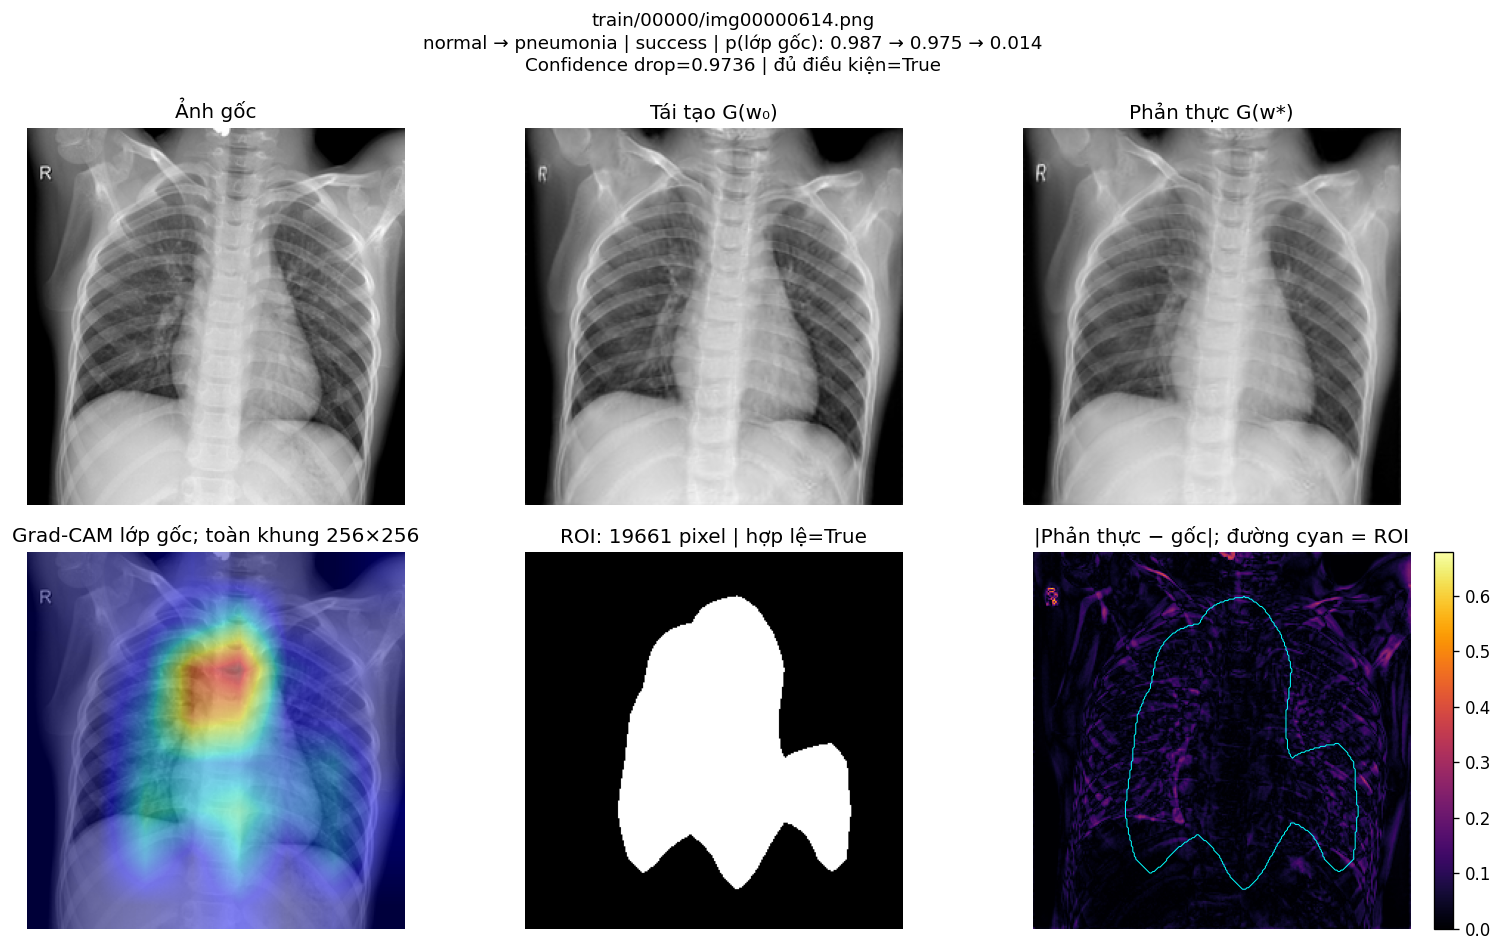

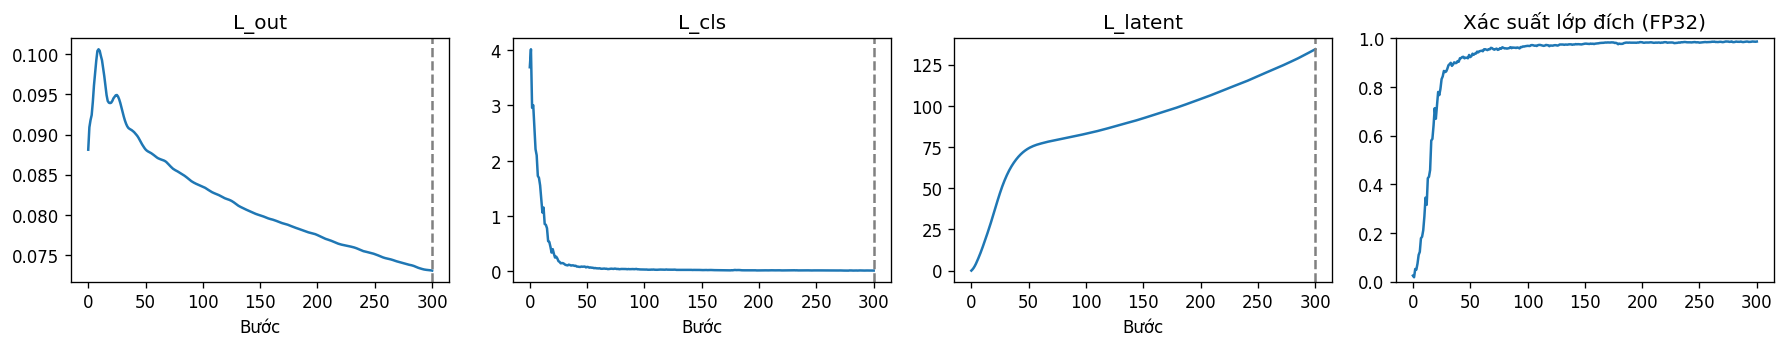

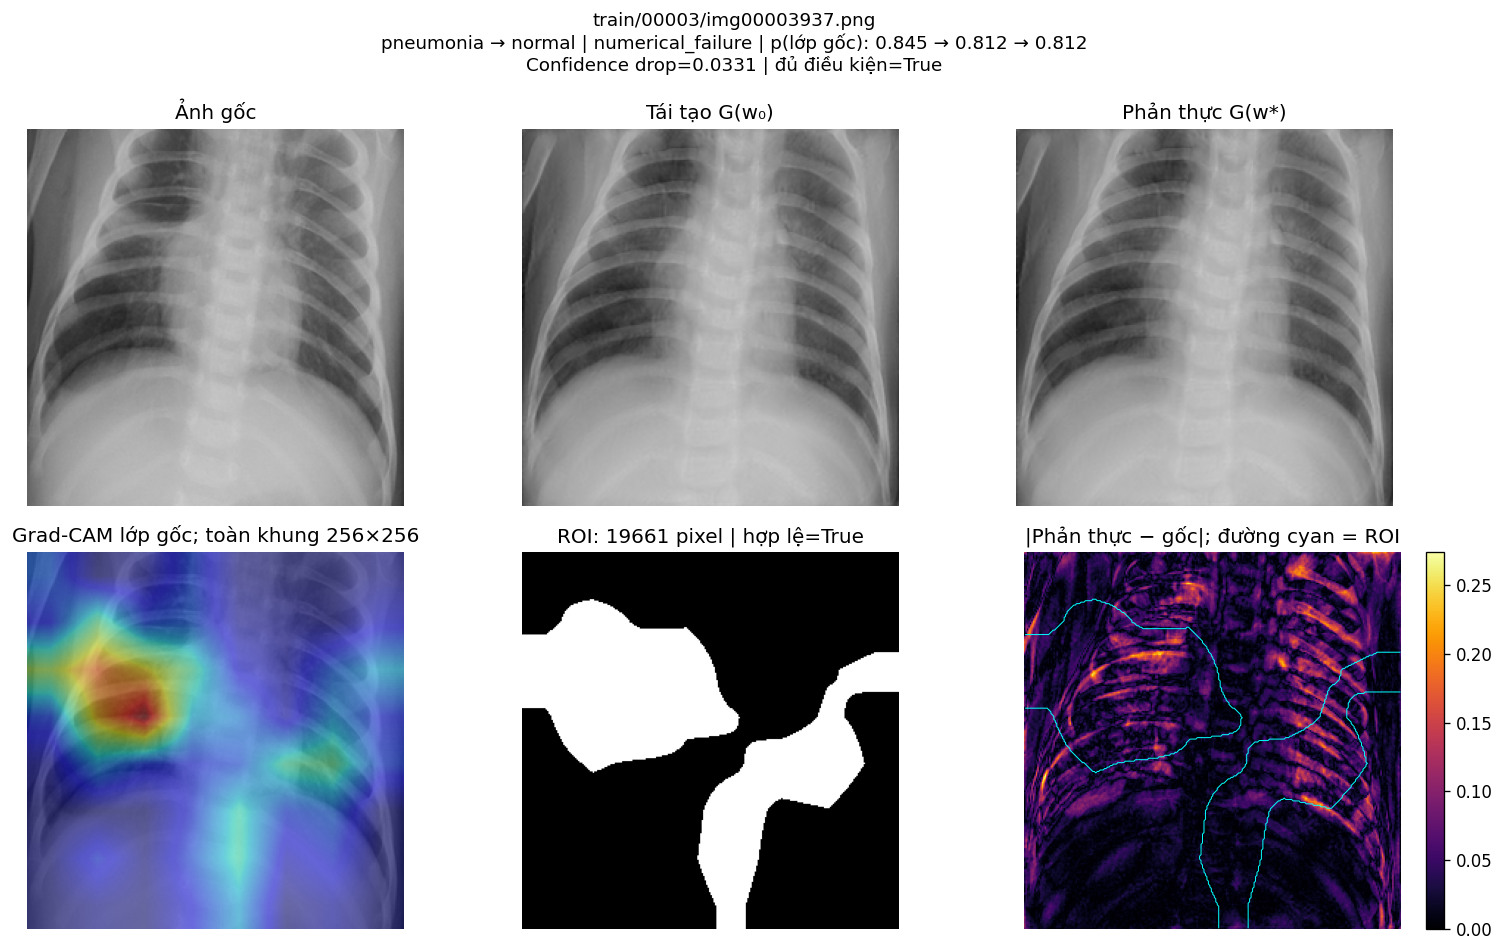

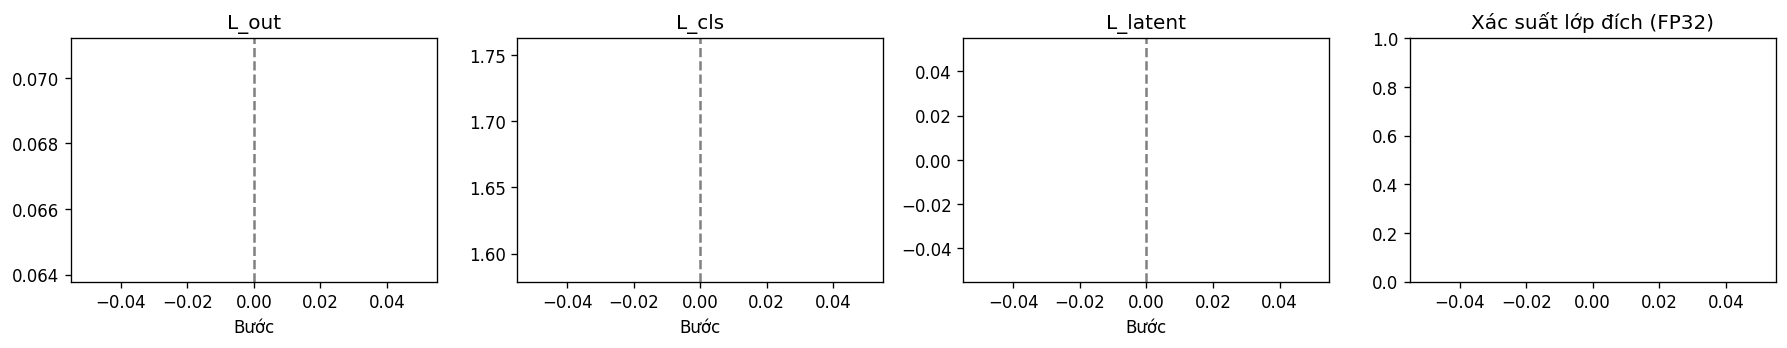

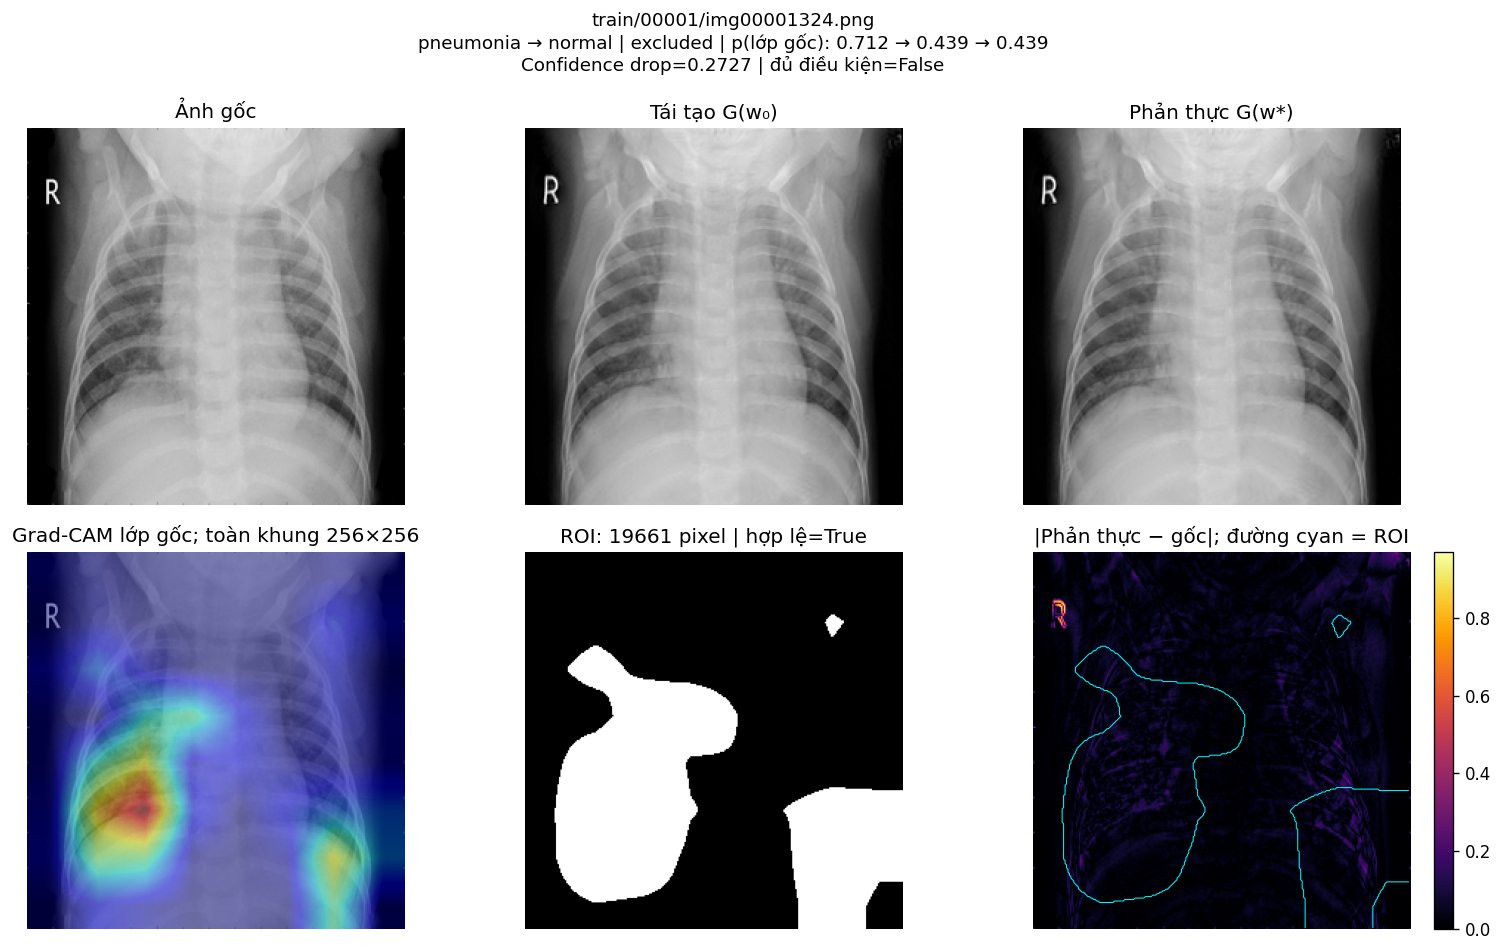

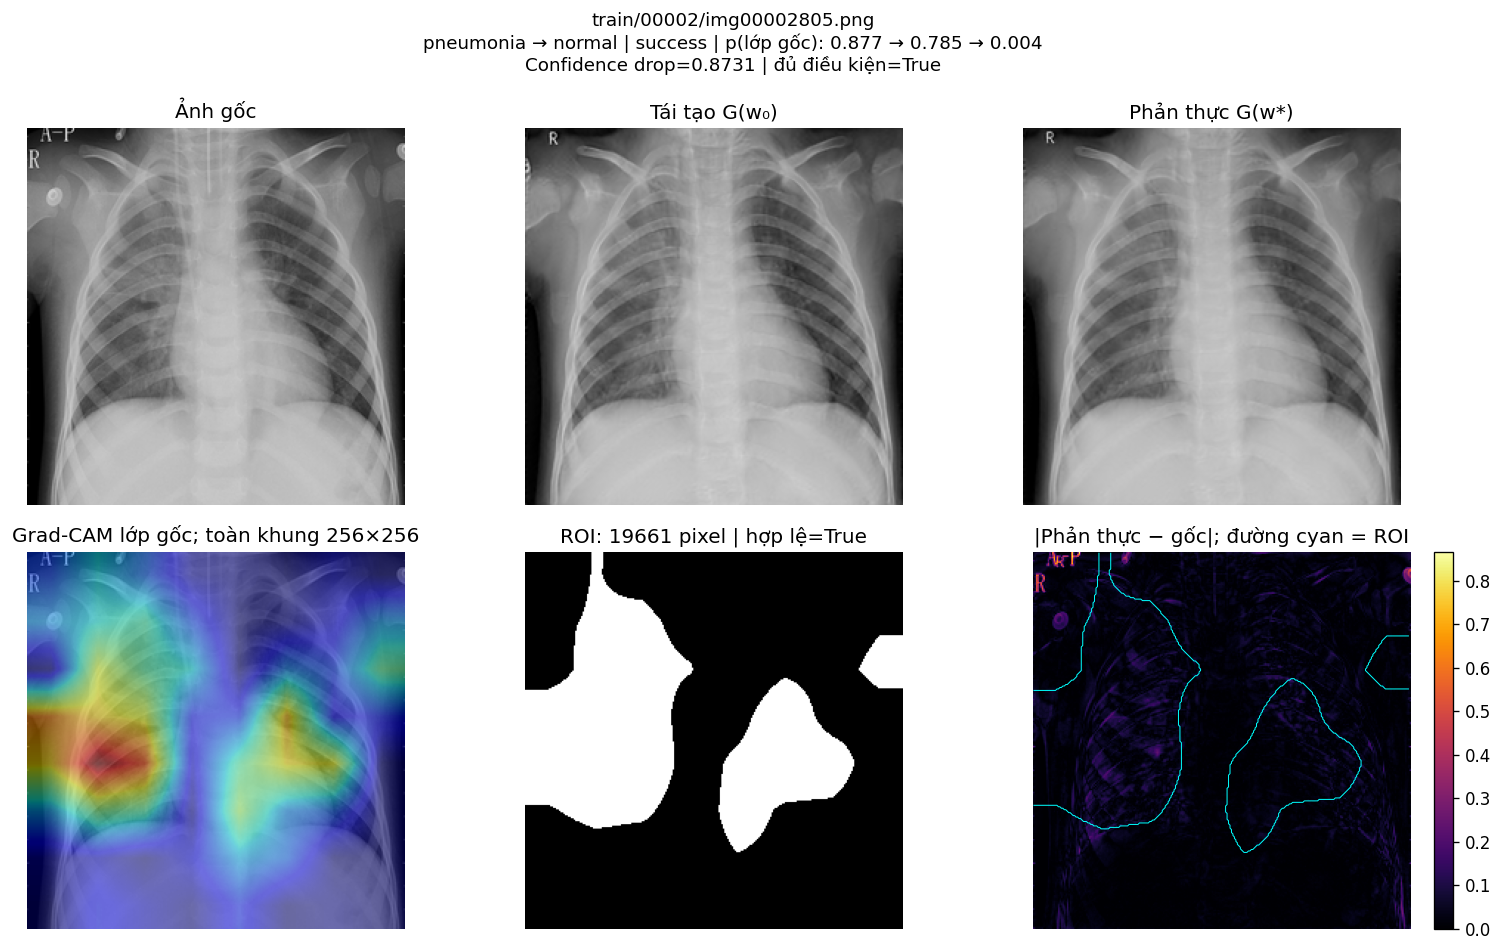

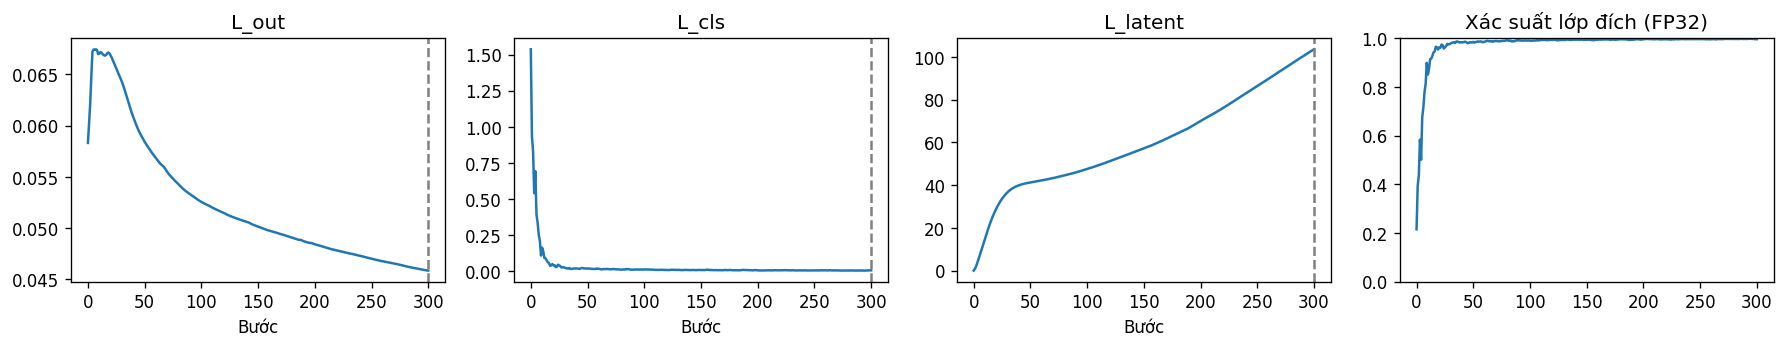

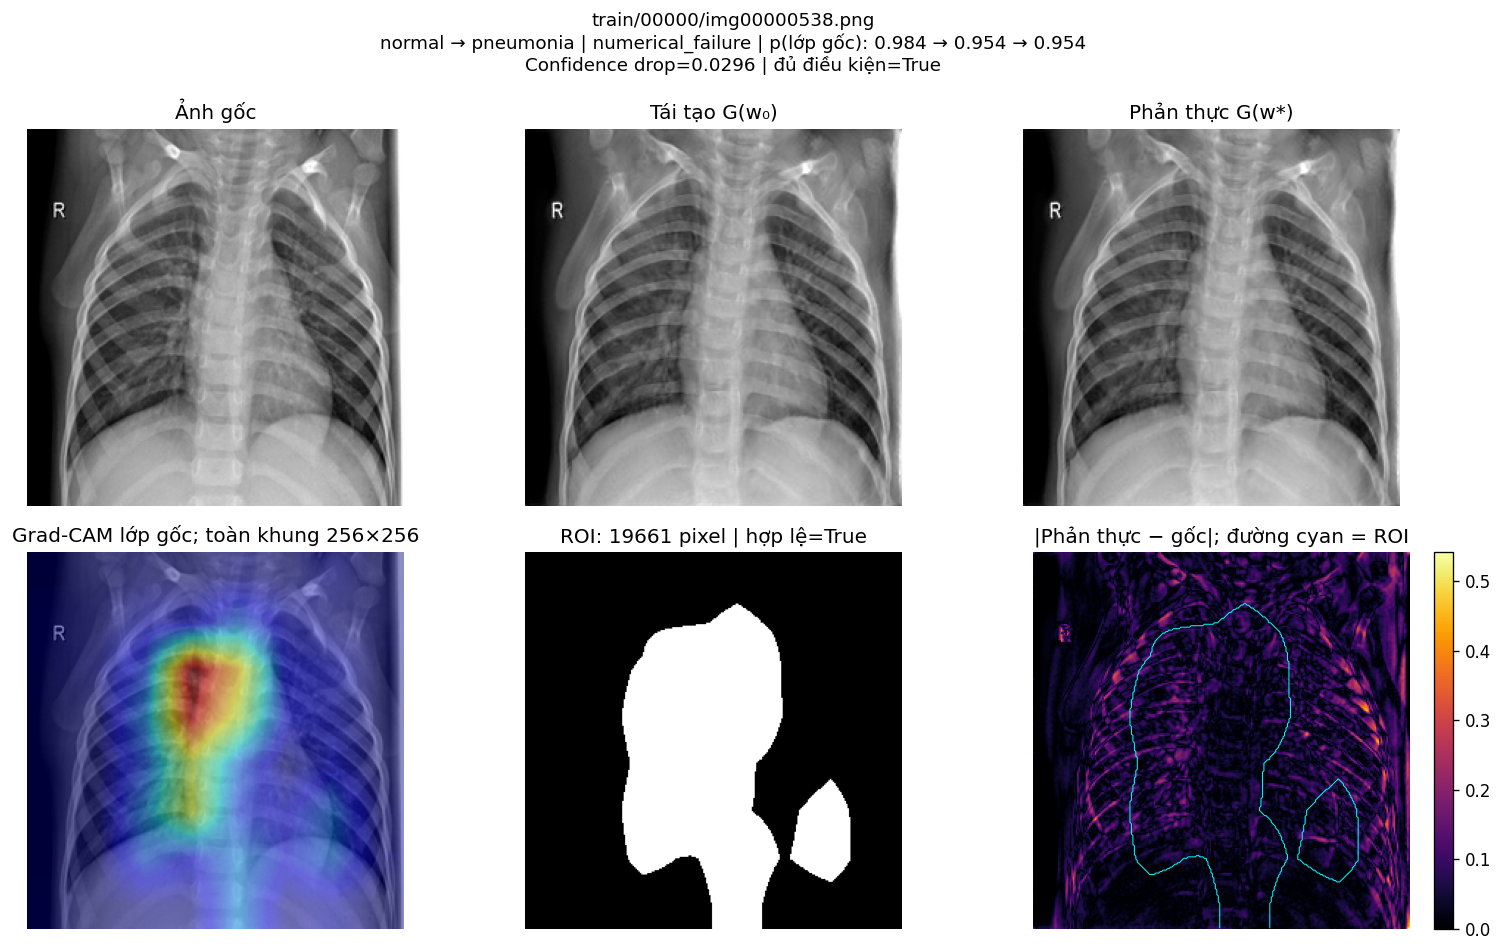

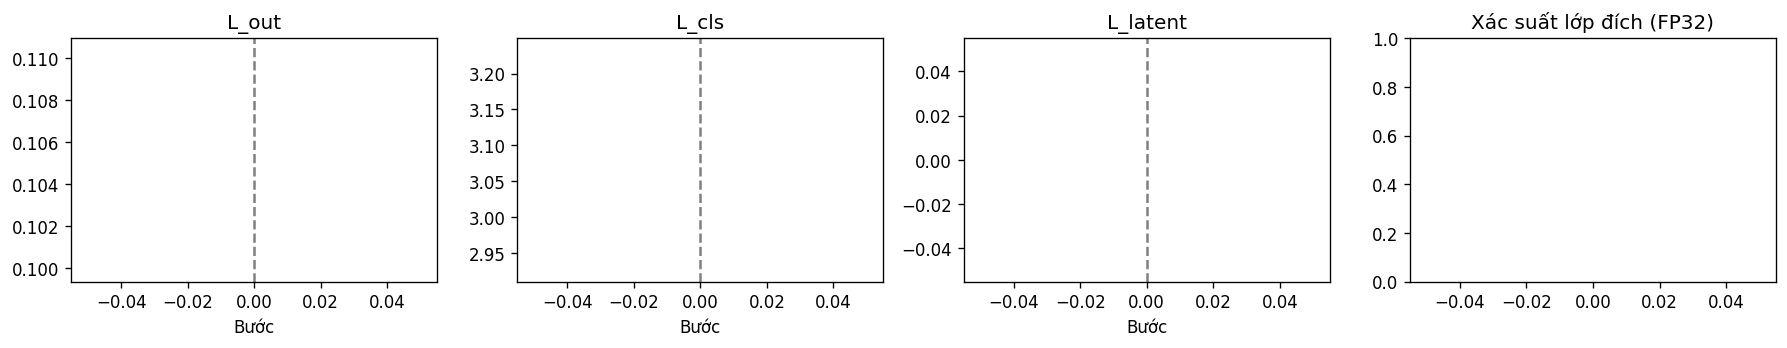

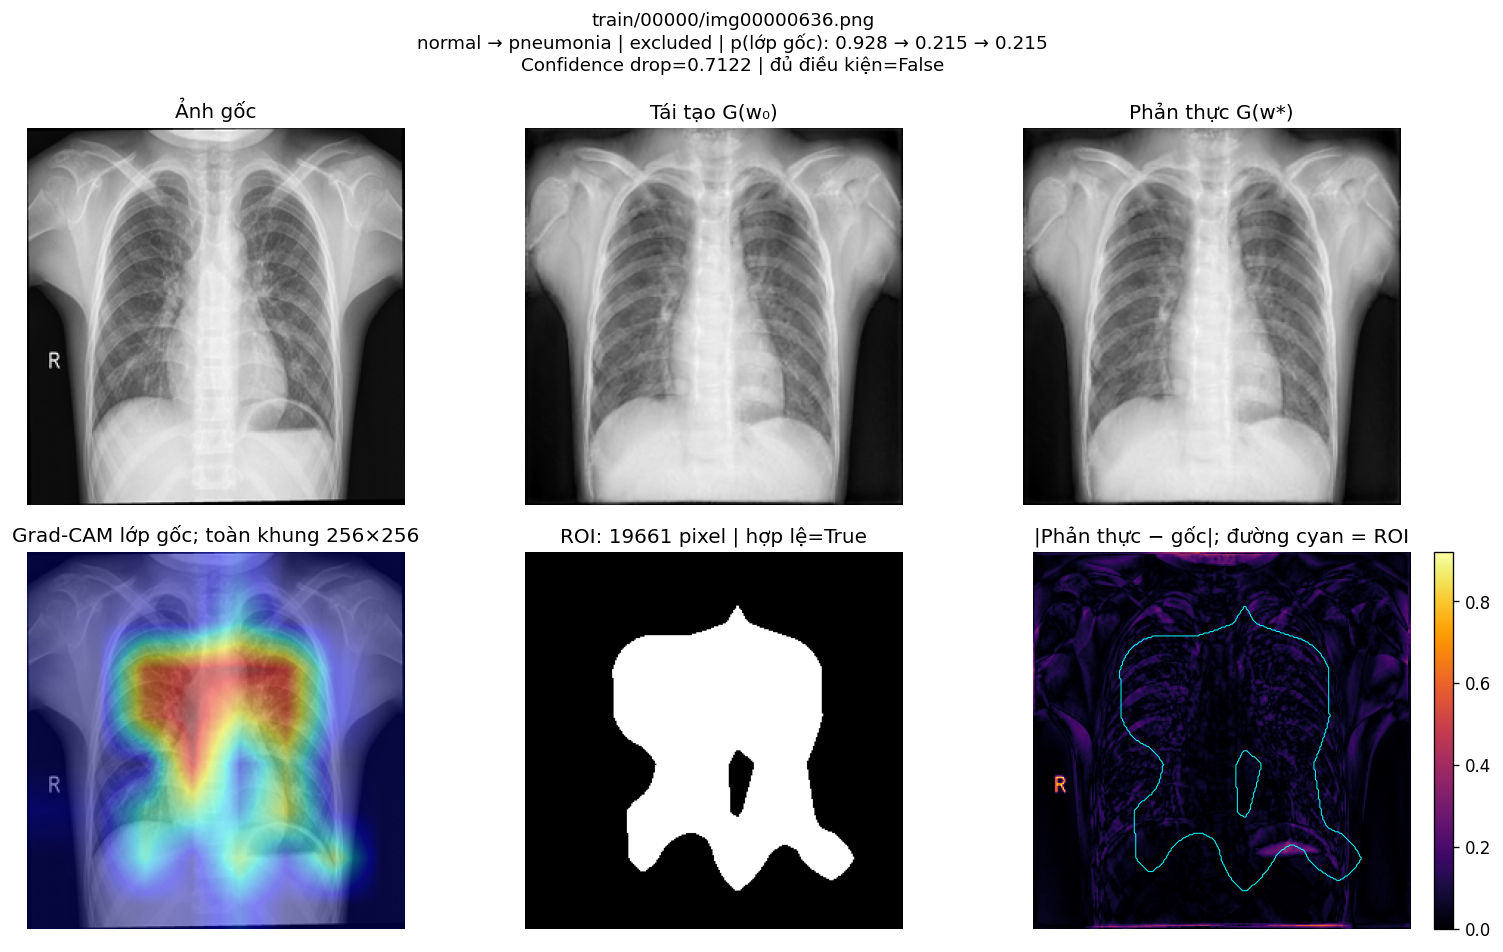

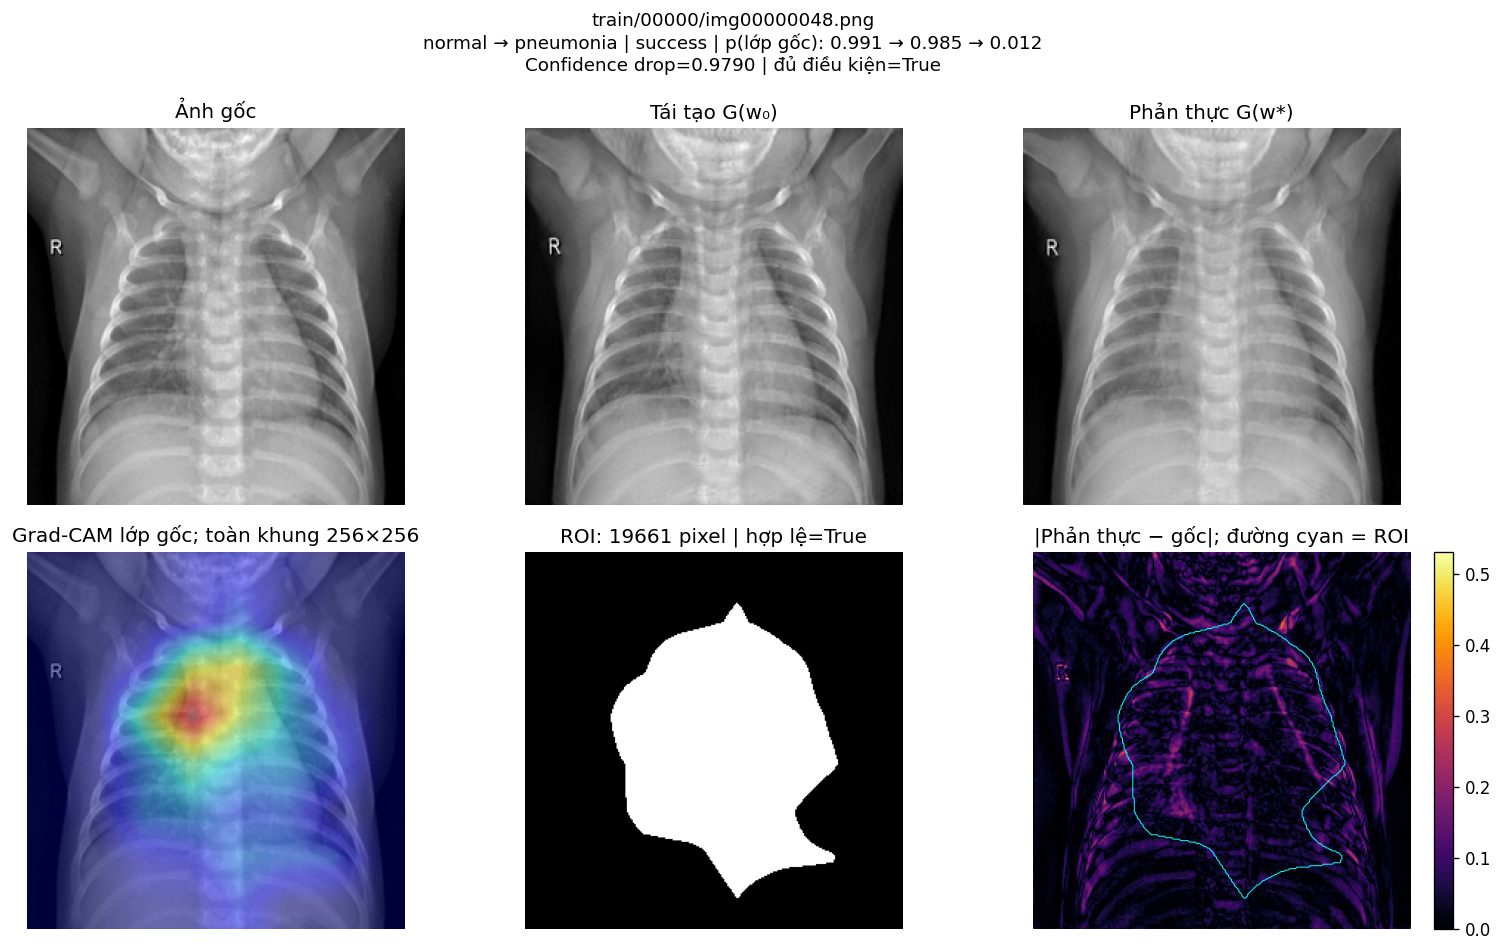

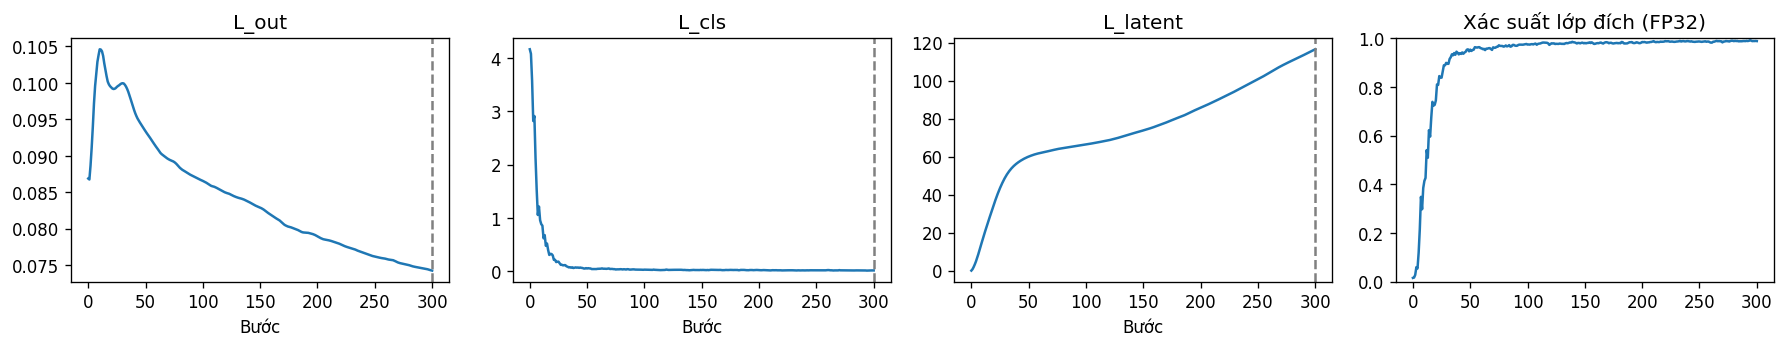

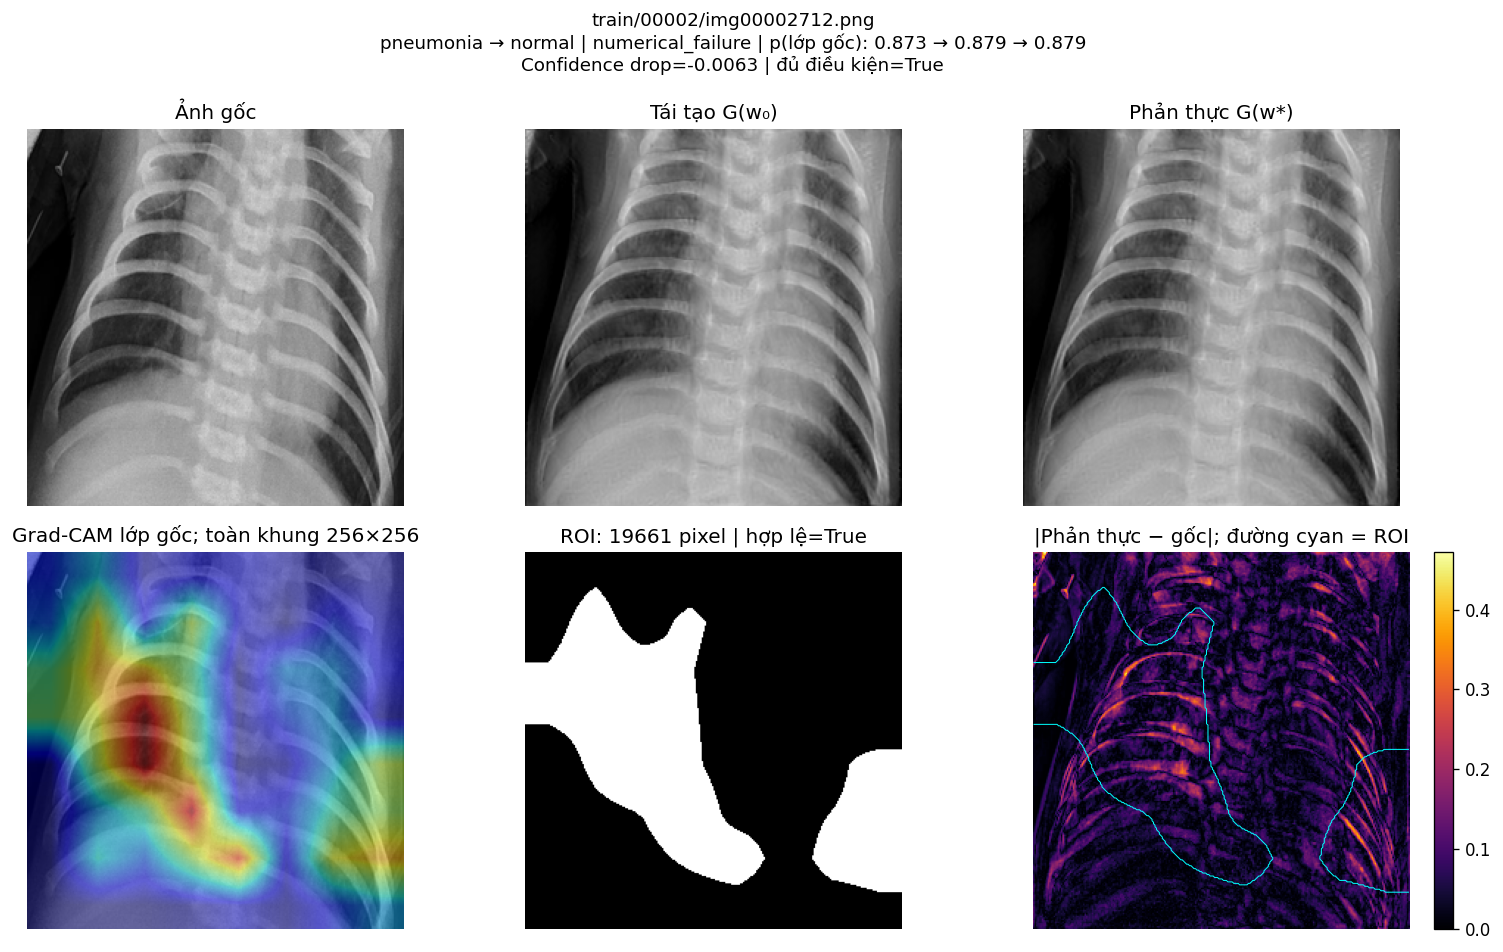

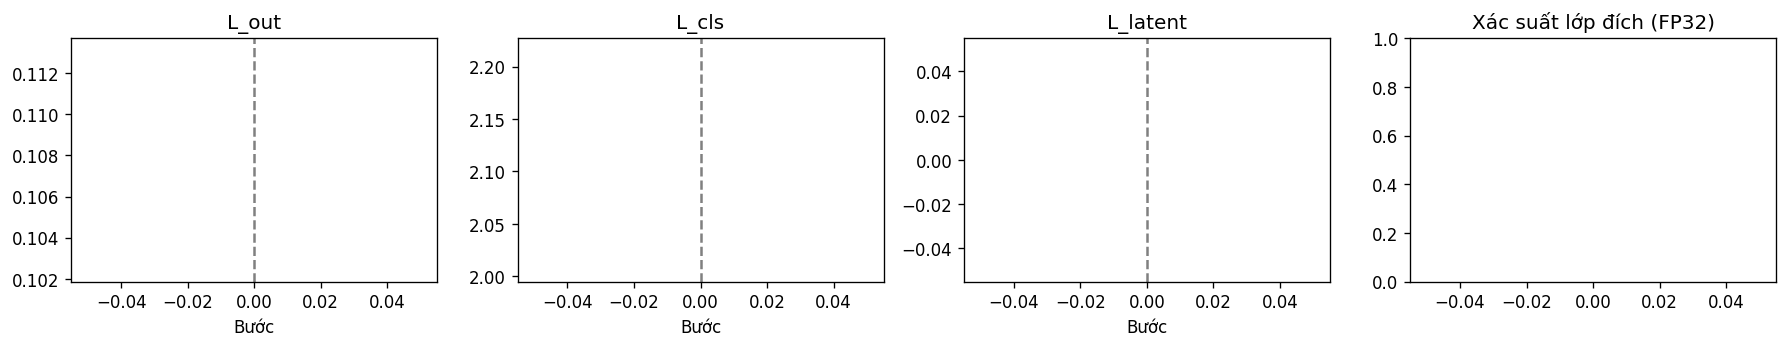

CSV, JSON, lịch sử loss, W+, mask, tensor float và PNG được lưu ở: /kaggle/working/chest_cf/encoder_only/train/9558531e20158ca1


In [5]:
import pandas as pd
from IPython.display import display, Image
OUTPUT = Path(json.loads((Path(OUTPUT_ROOT) / "latest_run.json").read_text())["output_dir"])
# Re-export from saved per-image records, including runs created before SD was added.
subprocess.run([PYTHON, "-c",
                "import json, sys; from pathlib import Path; "
                "from counterfactual_io import export_summary; "
                "export_summary(json.loads(Path(sys.argv[1]).read_text(encoding='utf-8')))",
                str(OUTPUT / "config.json")], env=RUN_ENV, check=True)
report = json.loads((OUTPUT / "summary.json").read_text(encoding="utf-8"))
print(f"Hoàn thành {report['completed_count']}/{report['selected_count']} ảnh; "
      f"đủ điều kiện: {report['eligible_count']}; toàn split: {report['dataset']['full_split']}")
print("Loại khỏi cohort:", report["exclusion_reasons"])
print("Trạng thái:", report["statuses"])
def format_mean_sd(mean, std):
    if mean is None:
        return "N/A"
    return f"{mean:.5f} ± {std:.5f}" if std is not None else f"{mean:.5f} ± N/A"


overall = report["metrics"]["overall"]
print(f"Confidence drop tổng thể (Mean ± SD): "
      f"{format_mean_sd(overall['confidence_drop'], overall['confidence_drop_std'])} "
      f"(N = {overall['count']})")
if not report["complete"]:
    print("Kết quả tạm thời: run chưa hoàn tất.")
print("SD mẫu giữa các ảnh (ddof=1); N/A khi N < 2; đơn vị: chênh lệch xác suất.")
metric_table = pd.DataFrame.from_dict(report["metrics"], orient="index")
for key, title in [("confidence_drop", "Confidence drop (Mean ± SD)"),
                   ("confidence_drop_from_reconstruction", "Drop từ tái tạo (Mean ± SD)")]:
    metric_table[title] = [format_mean_sd(group[key], group[key + "_std"])
                           for group in report["metrics"].values()]
    metric_table = metric_table.drop(columns=[key, key + "_std"])
metric_table = metric_table.rename(columns={
    "count": "N", "valid_count": "Đổi lớp thành công", "validity": "Validity",
    "outside_mae_raw": "MAE ngoài ROI", "outside_mae_count": "N ROI hợp lệ",
})
metric_table.index.name = "Nhóm đánh giá"
display(metric_table.style.format(precision=5, na_rep="N/A")
        .set_caption("Kết quả phản thực — trung bình ± độ lệch chuẩn mẫu"))
display(pd.read_csv(OUTPUT / "per_image_metrics.csv").head())
subprocess.run([PYTHON, str(BUNDLE / "src/counterfactual_report.py"), str(OUTPUT),
                "--limit", str(PREVIEW_IMAGES)], env=RUN_ENV, check=True)
for filename in json.loads((OUTPUT / "figures.json").read_text(encoding="utf-8")):
    display(Image(filename=filename))
print("CSV, JSON, lịch sử loss, W+, mask, tensor float và PNG được lưu ở:", OUTPUT)


## 7. Nguồn và giới hạn kiểm chứng

- [Encoder ReStyle-pSp step 3500](https://huggingface.co/Purino/restyle-psp-chest-xray-pneumonia-256-gray/tree/ee53ea578502d6befa6cc73af4cd316ceb817c60/checkpoints/step-00003500)
- [Generator StyleGAN2 500 kimg](https://huggingface.co/Purino/stylegan2-ada-chest-xray-pneumonia-256-gray-scratch/tree/9f6e759670e129ee426771126411973e5fedc3c0/checkpoints/nimg-000000500000)
- [Classifier full-frame v2](https://huggingface.co/Purino/resnet50-chest-xray-256-fullframe-gray-v2/tree/94d95886e98da0c3a7a61670429c60419ceba2c4)
- [Dataset full-frame grayscale](https://huggingface.co/datasets/Purino/chest-xray-pneumonia-256-fullframe-gray/tree/558d8fad0b36f170a8f706370cc8dba5a7161e3d)
- [Grad-CAM](https://arxiv.org/abs/1610.02391), [ReStyle](https://github.com/yuval-alaluf/restyle-encoder)

Bản ghi nguồn và phạm vi kiểm chứng nằm trong bundle. Baseline được tính lại,
không sao chép kết quả model card. Kiểm tra val là bước thăm dò phương pháp;
chưa thể suy ra hiệu quả trên tập đánh giá độc lập. Đối chiếu tensor float khi
tái đánh giá; PNG đã lượng tử hóa chỉ dùng minh họa.


## 8. Đẩy toàn bộ dữ liệu thực nghiệm lên Hugging Face

Trong Kaggle, mở **Add-ons → Secrets**, tạo **HF_TOKEN** có quyền ghi của **Purino**
và bật quyền sử dụng cho notebook **ngay trước section 5**. Cell dưới chạy khi thực hiện Run All sau thí nghiệm.
Repo dataset: `Purino/chest-xray-counterfactual-cam-results`; repo mới mặc định private,
quyền hiển thị repo đã tồn tại được giữ nguyên.

Mặc định upload **mọi run đã xử lý** dưới OUTPUT_ROOT và thư mục smoke tương ứng.
Mỗi run có đường dẫn riêng theo chế độ/split/fingerprint. Có thể đặt UPLOAD_OUTPUT
để chọn một run. Bao gồm cả kết quả chưa hoàn tất, được ghi rõ trạng thái.

Mỗi ảnh: `tensors.npz` (gốc, tái tạo, phản thực, W+, CAM, mask), `counterfactual.png`,
`history.json`, `record.json`. Lưu cả ca bị loại hoặc thất bại. Upload đầy đủ CSV/JSON,
preflight, benchmark, hình minh họa, manifest dataset, cấu hình mô hình, môi trường và
`source.zip` chứa mã thực nghiệm cùng source encoder gốc. PREVIEW_IMAGES chỉ giới hạn
số hình minh họa, không giới hạn dữ liệu từng ảnh được upload.

`summary.json` có upload các trung bình confidence drop. File này cũng lưu
`confidence_drop_std` và `confidence_drop_from_reconstruction_std` cho từng nhóm,
kèm quy ước SD mẫu (`ddof=1`) trong `protocol.confidence_std`. Mean và SD giữ dạng
số riêng để phân tích lại; `null` biểu thị SD không xác định khi N < 2.
Section 5 và cell upload dùng chung cơ chế checkpoint. Cell upload xuất lại summary từ record từng ảnh bằng mã section 2 đã cập nhật,
nhờ đó các run cũ cũng có SD mà không cần chạy lại tối ưu. Chạy lại cell mã nguồn
ở section 2 sau khi cập nhật notebook, rồi chạy section 6/8.

Kiểm tra hash artifact trước upload và hash remote sau upload. Chạy lại cell để tiếp tục
nếu gián đoạn; bỏ qua tệp đã khớp. Token chỉ nằm trong bộ nhớ, không ghi vào kết quả.
`checkpoint.json` chỉ được publish sau khi xác minh đủ tệp, trỏ tới commit cố định
để section 5 tự khôi phục. Cấu hình repo và số tệp/commit nằm ở section 1.
[Hướng dẫn Hugging Face](https://huggingface.co/docs/huggingface_hub/v0.34.4/en/guides/upload).


In [6]:
# Dùng cùng cơ chế upload/xác minh/publish checkpoint với section 5.
from counterfactual_hub import checkpoint_environment

UPLOAD_OUTPUT = None  # None = mọi run đã xử lý dưới OUTPUT_ROOT và thư mục smoke.
if UPLOAD_OUTPUT is not None:
    upload_runs = [Path(UPLOAD_OUTPUT)]
else:
    upload_runs = sorted({config.parent.resolve()
        for root in (Path(OUTPUT_ROOT), Path(OUTPUT_ROOT + "_smoke"))
        for config in root.glob("*/*/*/config.json")
        if any(config.parent.glob("images/*/record.json"))})
if not upload_runs:
    raise FileNotFoundError("Chưa có kết quả thực nghiệm để upload.")
upload_env = checkpoint_environment(RUN_ENV)
try:
    for run_output in upload_runs:
        run_with_progress([PYTHON, str(BUNDLE / "src/counterfactual_hub.py"), str(run_output),
                           "--repo", HF_RESULTS_REPO, "--files-per-commit", str(HF_FILES_PER_COMMIT)],
                          env=upload_env)
finally:
    upload_env.pop("HF_TOKEN", None)
    del upload_env


HF checkpoint: 4000/4000 ảnh; 15/16027 tệp cần upload.

Processing Files (0 / 0)                : |          |  0.00B /  0.00B

New Data Upload                         : |          |  0.00B /  0.00B            


  .../9558531e20158ca1/comparison_04.png:   9%|▉         | 64.9kB /  736kB            



  .../9558531e20158ca1/comparison_05.png:   9%|▉         | 57.2kB /  649kB            




  ...rain/9558531e20158ca1/losses_04.png:   9%|▉         | 3.42kB / 38.8kB            





  ...rain/9558531e20158ca1/losses_00.png:   9%|▉         | 5.20kB / 59.0kB            






  .../9558531e20158ca1/comparison_00.png:   9%|▉         | 66.5kB /  754kB            







  ...rain/9558531e20158ca1/losses_07.png:   9%|▉         | 3.22kB / 36.6kB            








  .../9558531e20158ca1/comparison_07.png:   9%|▉         | 70.3kB /  798kB            









  ...rain/9558531e20158ca1/losses_06.png:   9%|▉         | 5.45kB / 61.8kB            










  ...rain/9558531e20158ca1/losses_03.pn